<a href="https://colab.research.google.com/github/Akshara369-1/Minor_Project-Starchaccumulation-vs-Daylength-/blob/main/DLM_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install cobra --quiet

In [ ]:
from cobra.io import read_sbml_model
plant_model=read_sbml_model('PlantCoreMetabolism_v2_1_0.xml')

In [ ]:
backup=plant_model.copy()#This one is unmodified throughout the code
plant_model1=plant_model.copy()
plant_model2=plant_model.copy()

In [ ]:
#Renaming all reactions
for rxn in plant_model1.reactions:
  rxn.id=rxn.id+"_Light"
  print(rxn.id)#just to see the change
for rxn in plant_model2.reactions:
  rxn.id=rxn.id+"_Dark"
  print(rxn.id)

#Renaming all metabolites
for met in plant_model1.metabolites:
  met.id=met.id+"_Light"
  print(met.id)
for met in plant_model2.metabolites:
  met.id=met.id+"_Dark"
  print(met.id)

  #Renaming compartments
for i in plant_model1.metabolites:
   if i.compartment==i.compartment +"_Light":
    break
   else:
    i.compartment=i.compartment+"_Light"
    print(i.compartment)
for j in plant_model2.metabolites:
   if j.compartment==j.compartment +"_Dark":
    break
   else:
    j.compartment=j.compartment+"_Dark"
    print(j.compartment)


Streaming output truncated to the last 5000 lines.
MDA_Fd_Ascorbate_p_Light
CHORISMATEMUT_RXN_p_Light
SUC_FUM_mc_Light
GLT_PROTON_vc_Light
GUANYL_KIN_RXN_c_Light
PRAISOM_RXN_p_Light
MercaptoPyruvateSulfurtransferase_m_Light
RXN_9533_p_Light
sSER_biomass_Light
GLUTAMATE_DEHYDROGENASE_RXN_m_Light
ARG_HIS_mc_Light
SUCROSE_PHOSPHATASE_RXN_c_Light
ARG_pc_Light
PREPHENATEDEHYDROG_RXN_c_Light
AIRS_RXN_p_Light
GLUTAMATE_SYNTHASE_NADH_RXN_p_Light
RXN_9528_p_Light
BRANCHED_CHAINAMINOTRANSFERVAL_RXN_m_Light
OROTATE_REDUCTASE_NADH_RXN_p_Light
RXN_7676_p_Light
ARG_PROTON_rev_vc_Light
RXN0_5114_p_Light
ILE_PROTON_rev_vc_Light
GLC_vc_Light
TYR_PROTON_rev_vc_Light
ASPCARBTRANS_RXN_p_Light
DIHYDRODIPICSYN_RXN_p_Light
K_rev_vc_Light
VAL_mc_Light
Plastoquinol_Oxidase_p_Light
10_FORMYL_THF_pc_Light
IMIDPHOSDEHYD_RXN_p_Light
1_PERIOD_1_PERIOD_1_PERIOD_39_RXN_m_Light
MAL_PROTON_vc_Light
RXN_6383_x_Light
pVAL_biomass_Light
RXN_9648_p_Light
6PGLUCONDEHYDROG_RXN_p_Light
METHIONINE_TRNA_LIGASE_RXN_c_Light
FORMA

In [ ]:
C3_dup_model=plant_model1.merge(plant_model2)


Constraining the biomass reaction

In [ ]:
Constraint1=C3_dup_model.problem.Constraint(C3_dup_model.reactions.AraCore_Biomass_tx_Light.flux_expression-3*C3_dup_model.reactions.AraCore_Biomass_tx_Dark.flux_expression,lb=0,ub=0)
C3_dup_model.add_cons_vars(Constraint1)

Constraining on phloem transport light:dark=3:1 AND DEFINING THE OBJECTIVE FUNCTION IN MATURE LEAVES

In [ ]:
#2nd constraint ,constraining the phloem output during day vs night
Phloem_biomass=C3_dup_model.problem.Constraint(
    C3_dup_model.reactions.Phloem_output_tx_Light.flux_expression-3*C3_dup_model.reactions.Phloem_output_tx_Dark.flux_expression,
    lb=0,ub=0)
C3_dup_model.add_cons_vars(Phloem_biomass)

In [ ]:
#Making the objective reaction
from cobra import Reaction,Metabolite
#Making new metabolites and adding it to existing phloem transport reaction
phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
C3_dup_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
C3_dup_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
#Making new reaction
rxn = Reaction('diel_biomass')
rxn.add_metabolites({phloem_transport_Light:-3,phloem_transport_Dark:-1})
rxn.lower_bound=0
rxn.upper_bound=1000
C3_dup_model.add_reactions([rxn])


In [ ]:
C3_dup_model.objective='diel_biomass'

In [ ]:

C3_sol3=C3_dup_model.optimize()
print(C3_sol3)

<Solution 182.337 at 0x7e11b85b7980>


getting informations from original model


In [ ]:
!pip install cobra --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 27.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.9/141.9 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 54.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 56.0 MB/s eta 0:00:00


In [ ]:
#Getting accumulation reactions from C3 model in github
from cobra.io import read_sbml_model
C3_org_model=read_sbml_model('C3_model.sbml.txt')

In [ ]:
C3_org_model

In [ ]:
backup=C3_org_model.copy()
C3_org_model1=C3_org_model.copy()

In [ ]:
obj=C3_org_model1.reactions.get_by_id("diel_biomass")
print(obj.reaction)
print(obj.upper_bound)
print(obj.metabolites)
C3_org_model1.metabolites.get_by_id("X_Phloem_contribution_t1")

In [ ]:
#Get to know in  the paper accumulation of starch,malate,citrate is happening.So lets find its reaction ids from c3_org_mode;
for rxn in C3_org_model1.reactions:
   if C3_org_model1.metabolites.get_by_id("STARCH_p2") in rxn.metabolites:
     print(rxn.id, "     ",rxn.reaction)

 #STARCH_p_dielTransfer reaction id that is different from reaction ids we duplicated we found.This means accumulation reactions are recorded as "diel transfer" key word

In [ ]:
for rxn in C3_org_model1.reactions:
  for m in plant_model.metabolites:
    if rxn.id==m.id +"_dielTransfer":#query
      print(rxn.id," ",rxn.reaction," ",rxn.bounds)

  #Thus we got all accumulation reactions



GLY_v_dielTransfer   GLY_v1 --> GLY_v2   (0.0, 1000.0)
ILE_v_dielTransfer   ILE_v1 --> ILE_v2   (0.0, 1000.0)
ARG_v_dielTransfer   ARG_v1 --> ARG_v2   (0.0, 1000.0)
THR_v_dielTransfer   THR_v1 --> THR_v2   (0.0, 1000.0)
NITRATE_v_dielTransfer   NITRATE_v1 <=> NITRATE_v2   (-1000.0, 1000.0)
GLN_v_dielTransfer   GLN_v1 --> GLN_v2   (0.0, 1000.0)
L_ALPHA_ALANINE_v_dielTransfer   L_ALPHA_ALANINE_v1 --> L_ALPHA_ALANINE_v2   (0.0, 1000.0)
TYR_v_dielTransfer   TYR_v1 --> TYR_v2   (0.0, 1000.0)
MET_v_dielTransfer   MET_v1 --> MET_v2   (0.0, 1000.0)
GLT_v_dielTransfer   GLT_v1 --> GLT_v2   (0.0, 1000.0)
VAL_v_dielTransfer   VAL_v1 --> VAL_v2   (0.0, 1000.0)
TRP_v_dielTransfer   TRP_v1 --> TRP_v2   (0.0, 1000.0)
4_AMINO_BUTYRATE_v_dielTransfer   4_AMINO_BUTYRATE_v1 --> 4_AMINO_BUTYRATE_v2   (0.0, 1000.0)
SER_v_dielTransfer   SER_v1 --> SER_v2   (0.0, 1000.0)
PHE_v_dielTransfer   PHE_v1 --> PHE_v2   (0.0, 1000.0)
CYS_v_dielTransfer   CYS_v1 --> CYS_v2   (0.0, 1000.0)
PROTON_v_dielTransfer   PROTO

In [ ]:
l=[]#to be list of reaction ids
N=[]#to be list of reaction names
lb=[]#to be list of reaction lb
ub=[]#to be list of reaction ub
r=[]#to be list of reaction formula
for rxn in C3_org_model1.reactions:
  for m in plant_model.metabolites:
    if rxn.id==m.id +"_dielTransfer":
      l.append(rxn.id)
      N.append(rxn.name)
      lb.append(rxn.lower_bound)
      ub.append(rxn.upper_bound)
      r.append(rxn.reaction)
print(l)
print(len(l))
print(N)
print(lb)
print(ub)
print(r)

Adding Accumulation reactions

Change it to for loop

In [ ]:
from cobra import Reaction#The reason why most diel transfer reactions are in v(vacuole) because in plants accumulation of metabolites happen in vacuoles(cover 90% of plant cell)
r1=Reaction('GLY_v_dielTransfer')
r1.name='GLY_v_dielTransfer'
r1.lower_bound=0
r1.upper_bound=1000
r1.add_metabolites({C3_dup_model.metabolites.get_by_id("GLY_v_Light"):-1,C3_dup_model.metabolites.get_by_id("GLY_v_Dark"): 1})
C3_dup_model.add_reactions([r1])

r2=Reaction('ILE_v_dielTransfer')
r2.name='ILE_v_diel_Transfer'
r2.lower_bound=0
r2.upper_bound=1000
r2.add_metabolites({C3_dup_model.metabolites.get_by_id("ILE_v_Light"):-1,C3_dup_model.metabolites.get_by_id("ILE_v_Dark"):1})
C3_dup_model.add_reactions([r2])

r3=Reaction('ARG_v_dielTransfer')
r3.name='ARG_v_dielTransfer'
r3.lower_bound=0
r3.upper_bound=1000
r3.add_metabolites({C3_dup_model.metabolites.get_by_id("ARG_v_Light"):-1,C3_dup_model.metabolites.get_by_id("ARG_v_Dark"):1})
C3_dup_model.add_reactions([r3])

r4=Reaction('THR_v_dielTransfer')
r4.name='THR_v_dielTransfer'
r4.lower_bound=0
r4.upper_bound=1000
r4.add_metabolites({C3_dup_model.metabolites.get_by_id("THR_v_Light"):-1,C3_dup_model.metabolites.get_by_id("THR_v_Dark"):1})
C3_dup_model.add_reactions([r4])

r5=Reaction('NITRATE_v_dielTransferReverse')
r5.name='NITRATE_v_dielTransfer_reversible'
r5.lower_bound=-1000
r5.upper_bound=1000
r5.add_metabolites({C3_dup_model.metabolites.get_by_id('NITRATE_v_Light'):-1,C3_dup_model.metabolites.get_by_id('NITRATE_v_Dark'):1})
C3_dup_model.add_reactions([r5])

r6=Reaction('GLN_v_dielTransfer')
r6.name='GLN_v_dielTransfer'
r6.lower_bound=0
r6.upper_bound=1000
r6.add_metabolites({C3_dup_model.metabolites.get_by_id('GLN_v_Light'):-1,C3_dup_model.metabolites.get_by_id('GLN_v_Dark'):1})
C3_dup_model.add_reactions([r6])

r7=Reaction('L_ALPHA_ALANINE_v_dielTransfer')
r7.name='L_ALPHA_ALANINE_v_dielTransfer'
r7.lower_bound=0
r7.upper_bound=1000
r7.add_metabolites({C3_dup_model.metabolites.get_by_id('L_ALPHA_ALANINE_v_Light'):-1,C3_dup_model.metabolites.get_by_id("L_ALPHA_ALANINE_v_Dark"):1})
C3_dup_model.add_reactions([r7])

r8=Reaction('TYR_v_dielTransfer')
r8.name='TYR_v_dielTransfer'
r8.lower_bound=0
r8.upper_bound=1000
r8.add_metabolites({C3_dup_model.metabolites.get_by_id('TYR_v_Light'):-1,C3_dup_model.metabolites.get_by_id("TYR_v_Dark"):1})
C3_dup_model.add_reactions([r8])

r9=Reaction('MET_v_dielTransfer')
r9.name='MET_v_dielTransfer'
r9.lower_bound=0
r9.upper_bound=1000
r9.add_metabolites({C3_dup_model.metabolites.get_by_id('MET_v_Light'):-1,C3_dup_model.metabolites.get_by_id("MET_v_Dark"):1})
C3_dup_model.add_reactions([r9])

r10=Reaction('GLT_v_dielTransfer')
r10.name='GLT_v_dielTransfer'
r10.lower_bound=0
r10.upper_bound=1000
r10.add_metabolites({C3_dup_model.metabolites.get_by_id('GLT_v_Light'):-1,C3_dup_model.metabolites.get_by_id("GLT_v_Dark"):1})
C3_dup_model.add_reactions([r10])

r11=Reaction('VAL_v_dielTransfer')
r11.name='VAL_v_dielTransfer'
r11.lower_bound=0
r11.upper_bound=1000
r11.add_metabolites({C3_dup_model.metabolites.get_by_id('VAL_v_Light'):-1,C3_dup_model.metabolites.get_by_id("VAL_v_Dark"):1})
C3_dup_model.add_reactions([r11])

r12=Reaction('TRP_v_dielTransfer')
r12.name='TRP_v_dielTransfer'
r12.lower_bound=0
r12.upper_bound=1000
r12.add_metabolites({C3_dup_model.metabolites.get_by_id('TRP_v_Light'):-1,C3_dup_model.metabolites.get_by_id("TRP_v_Dark"):1})
C3_dup_model.add_reactions([r12])

r13=Reaction('4_AMINO_BUTYRATE_v_dielTransfer')
r13.name='4_AMINO_BUTYRATE_v_dielTransfer'
r13.lower_bound=0
r13.upper_bound=1000
r13.add_metabolites({C3_dup_model.metabolites.get_by_id('4_AMINO_BUTYRATE_v_Light'):-1,C3_dup_model.metabolites.get_by_id("4_AMINO_BUTYRATE_v_Dark"):1})
C3_dup_model.add_reactions([r13])

r14=Reaction('SER_v_dielTransfer')
r14.name='SER_v_dielTransfer'
r14.lower_bound=0
r14.upper_bound=1000
r14.add_metabolites({C3_dup_model.metabolites.get_by_id('SER_v_Light'):-1,C3_dup_model.metabolites.get_by_id("SER_v_Dark"):1})
C3_dup_model.add_reactions([r14])

r15=Reaction('PHE_v_dielTransfer')
r15.name='PHE_v_dielTransfer'
r15.lower_bound=0
r15.upper_bound=1000
r15.add_metabolites({C3_dup_model.metabolites.get_by_id('PHE_v_Light'):-1,C3_dup_model.metabolites.get_by_id("PHE_v_Dark"):1})
C3_dup_model.add_reactions([r15])

r16=Reaction('CYS_v_dielTransfer')
r16.name='CYS_v_dielTransfer'
r16.lower_bound=0
r16.upper_bound=1000
r16.add_metabolites({C3_dup_model.metabolites.get_by_id('CYS_v_Light'):-1,C3_dup_model.metabolites.get_by_id("CYS_v_Dark"):1})
C3_dup_model.add_reactions([r16])

r17=Reaction('PROTON_v_dielTransferReverse')
r17.name='PROTON_v_dielTransfer_reversible'
r17.lower_bound=-1000
r17.upper_bound=1000
r17.add_metabolites({C3_dup_model.metabolites.get_by_id('PROTON_v_Light'):-1,C3_dup_model.metabolites.get_by_id("PROTON_v_Dark"):1})
C3_dup_model.add_reactions([r17])

r18=Reaction('LEU_v_dielTransfer')
r18.name='LEU_v_dielTransfer'
r18.lower_bound=0
r18.upper_bound=1000
r18.add_metabolites({C3_dup_model.metabolites.get_by_id('LEU_v_Light'):-1,C3_dup_model.metabolites.get_by_id("LEU_v_Dark"):1})
C3_dup_model.add_reactions([r18])

r19=Reaction('L_ASPARTATE_v_dielTransfer')
r19.name='L_ASPARTATE_v_dielTransfer'
r19.lower_bound=0
r19.upper_bound=1000
r19.add_metabolites({C3_dup_model.metabolites.get_by_id('L_ASPARTATE_v_Light'):-1,C3_dup_model.metabolites.get_by_id("L_ASPARTATE_v_Dark"):1})
C3_dup_model.add_reactions([r19])

r20=Reaction('LYS_v_dielTransfer')
r20.name='LYS_v_dielTransfer'
r20.lower_bound=0
r20.upper_bound=1000
r20.add_metabolites({C3_dup_model.metabolites.get_by_id('LYS_v_Light'):-1,C3_dup_model.metabolites.get_by_id("LYS_v_Dark"):1})
C3_dup_model.add_reactions([r20])

r21=Reaction('STARCH_p_dielTransferReverse')
r21.name='STARCH_p_dielTransfer_reversible'
r21.lower_bound=-1000
r21.upper_bound=1000
r21.add_metabolites({C3_dup_model.metabolites.get_by_id('STARCH_p_Light'):-1,C3_dup_model.metabolites.get_by_id("STARCH_p_Dark"):1})
C3_dup_model.add_reactions([r21])

r22=Reaction('ASN_v_dielTransfer')
r22.name='ASN_v_dielTransfer'
r22.lower_bound=0
r22.upper_bound=1000
r22.add_metabolites({C3_dup_model.metabolites.get_by_id("ASN_v_Light"):-1,C3_dup_model.metabolites.get_by_id("ASN_v_Dark"):1})
C3_dup_model.add_reactions([r22])

r23=Reaction('SUCROSE_v_dielTransferReverse')
r23.name='SUCROSE_v_dielTransfer_reversible'
r23.lower_bound=-1000
r23.upper_bound=1000
r23.add_metabolites({C3_dup_model.metabolites.get_by_id("SUCROSE_v_Light"):-1,C3_dup_model.metabolites.get_by_id("SUCROSE_v_Dark"):1})
C3_dup_model.add_reactions([r23])

r24=Reaction('PRO_v_dielTransfer')
r24.name='PRO_v_dielTransfer'
r24.lower_bound=0
r24.upper_bound=1000
r24.add_metabolites({C3_dup_model.metabolites.get_by_id("PRO_v_Light"):-1,C3_dup_model.metabolites.get_by_id("PRO_v_Dark"):1})
C3_dup_model.add_reactions([r24])

r25=Reaction('CIT_v_dielTransferReverse')
r25.name='CIT_v_dielTransfer_reversible'
r25.lower_bound=-1000
r25.upper_bound=1000
r25.add_metabolites({C3_dup_model.metabolites.get_by_id("CIT_v_Light"):-0.5,C3_dup_model.metabolites.get_by_id("aCIT_v_Light"):-0.5,C3_dup_model.metabolites.get_by_id("CIT_v_Dark"):0.5,C3_dup_model.metabolites.get_by_id("aCIT_v_Dark"):0.5})
C3_dup_model.add_reactions([r25])

r26=Reaction('HIS_v_dielTransfer')
r26.name='HIS_v_dielTransfer'
r26.lower_bound=0
r26.upper_bound=1000
r26.add_metabolites({C3_dup_model.metabolites.get_by_id("bHIS_v_Light"):-1,C3_dup_model.metabolites.get_by_id("bHIS_v_Dark"):1})
C3_dup_model.add_reactions([r26])

r27=Reaction('MAL_v_dielTransferReverse')
r27.name='MAL_v_dielTransfer_reversible'
r27.lower_bound=-1000
r27.upper_bound=1000
r27.add_metabolites({C3_dup_model.metabolites.get_by_id("MAL_v_Light"):-0.7,C3_dup_model.metabolites.get_by_id("aMAL_v_Light"):-0.3,C3_dup_model.metabolites.get_by_id("MAL_v_Dark"):0.7,C3_dup_model.metabolites.get_by_id("aMAL_v_Dark"):0.3})
C3_dup_model.add_reactions([r27])

In [ ]:
from cobra.flux_analysis import pfba
C3_sol4=pfba(C3_dup_model)

In [ ]:
C3_dup_model.reactions.GLY_v_dielTransfer

Reaction identifier,GLY_v_dielTransfer
Name,GLY_v_dielTransfer
Memory address,0x7e11b86a8230
Stoichiometry,GLY_v_Light --> GLY_v_Dark GLY --> GLY
GPR,
Lower bound,0
Upper bound,1000


In [ ]:
C3_dup_model.reactions.PROTON_v_dielTransferReverse

Reaction identifier,PROTON_v_dielTransferReverse
Name,PROTON_v_dielTransfer_reversible
Memory address,0x7e11b8379a90
Stoichiometry,PROTON_v_Light <=> PROTON_v_Dark PROTON <=> PROTON
GPR,
Lower bound,-1000
Upper bound,1000


In [ ]:
from cobra.io import write_sbml_model
D_L_MODEL=write_sbml_model(C3_dup_model,'DL_model')

In [ ]:
!pip install cobra --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.8/141.8 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 3.7 MB/s eta 0:00:00


In [ ]:
from cobra.io import read_sbml_model
C3_dup_model=read_sbml_model('DL_model')

from Diel Lief model C3-dup to C3 model

In [ ]:
!pip install cobra --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.8/141.8 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 63.6 MB/s eta 0:00:00


In [ ]:
from cobra.io import read_sbml_model

In [ ]:
C3_dup_model=read_sbml_model('DL_model')

In [ ]:
#Setting photosythetically active photon flux intensity to be 500
PPFD = 500 #umol/m2/s
C3_dup_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
C3_dup_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
C3_dup_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
C3_dup_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0


In [ ]:
# We want no sucrose uptake to happen during day as well as night
C3_dup_model.reactions.get_by_id("Sucrose_tx_Dark").bounds = (0,0)
C3_dup_model.reactions.get_by_id("Sucrose_tx_Light").bounds = (0,0)

# We want no Glucose uptake to happen during day as well as night
C3_dup_model.reactions.get_by_id("GLC_tx_Dark").bounds = (0,0)
C3_dup_model.reactions.get_by_id("GLC_tx_Light").bounds = (0,0)

SINCE We found no nitrate uptake then our aim is to find where does this aminoacids for phloemtransport synthesised

In [ ]:
met=C3_dup_model.metabolites.get_by_id('S_ALLANTOIN_r_Light')
for rxn in met.reactions:
  rxn.bounds=(0,0)
C3_dup_model.reactions.get_by_id('NH4_tx_Light').bounds=(0,0)



NITRATE UPTAKE Constraint Day:Night=3:2

In [ ]:
sameflux=C3_dup_model.problem.Constraint(2*C3_dup_model.reactions.Nitrate_tx_Light.flux_expression-3*C3_dup_model.reactions.Nitrate_tx_Dark.flux_expression,
                                         lb=0,ub=0)

C3_dup_model.add_cons_vars(sameflux)

RuBPcarboxylase:RuBPoxygenase reaction= 3:1

In [ ]:
Rubisco_constraint=C3_dup_model.problem.Constraint(3*C3_dup_model.reactions.RXN_961_p_Light.flux_expression-C3_dup_model.reactions.RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p_Light.flux_expression,
                                                   lb=0,ub=0)
C3_dup_model.add_cons_vars(Rubisco_constraint)

In [ ]:
print(C3_dup_model.reactions.PEPCARBOX_RXN_c_Light,C3_dup_model.reactions.PEPCARBOX_RXN_c_Light.flux)
print(C3_dup_model.reactions.PEPDEPHOS_RXN_c_Light,C3_dup_model.reactions.PEPDEPHOS_RXN_c_Light.flux)

PEPCARBOX_RXN_c_Light: HCO3_c_Light + PHOSPHO_ENOL_PYRUVATE_c_Light + 0.3 PROTON_c_Light --> OXALACETIC_ACID_c_Light + 0.7 Pi_c_Light + 0.3 aPi_c_Light 0.0
PEPDEPHOS_RXN_c_Light: 0.5 ADP_c_Light + PHOSPHO_ENOL_PYRUVATE_c_Light + 0.85 PROTON_c_Light + 0.5 aADP_c_Light --> 0.65 ATP_c_Light + PYRUVATE_c_Light + 0.35 aATP_c_Light 20.069173690227416


ATP:NADPH ratio 3:1

In [ ]:
#Day
NGAM_constraint=C3_dup_model.problem.Constraint(3*(C3_dup_model.reactions.NADPHoxc_tx_Light.flux_expression+C3_dup_model.reactions.NADPHoxm_tx_Light.flux_expression+C3_dup_model.reactions.NADPHoxp_tx_Light.flux_expression)-C3_dup_model.reactions.ATPase_tx_Light.flux_expression,
                                                lb=0,ub=0)
C3_dup_model.add_cons_vars(NGAM_constraint)
#Night
NGAM_constraint2=C3_dup_model.problem.Constraint(3*(C3_dup_model.reactions.NADPHoxc_tx_Dark.flux_expression+C3_dup_model.reactions.NADPHoxm_tx_Dark.flux_expression+C3_dup_model.reactions.NADPHoxp_tx_Dark.flux_expression)-C3_dup_model.reactions.ATPase_tx_Dark.flux_expression,
                                                lb=0,ub=0)
C3_dup_model.add_cons_vars(NGAM_constraint2)

ATP DAY:ATP NIGHT =1:1 and hence for NADPH

In [ ]:
atpdaynightconstraint=C3_dup_model.problem.Constraint(C3_dup_model.reactions.ATPase_tx_Light.flux_expression-C3_dup_model.reactions.ATPase_tx_Dark.flux_expression,
                                            lb=0,ub=0)
C3_dup_model.add_cons_vars(atpdaynightconstraint)

NADPHdaynightconstraint=C3_dup_model.problem.Constraint(C3_dup_model.reactions.NADPHoxc_tx_Light.flux_expression+C3_dup_model.reactions.NADPHoxp_tx_Light.flux_expression+C3_dup_model.reactions.NADPHoxm_tx_Light.flux_expression-(C3_dup_model.reactions.NADPHoxc_tx_Dark.flux_expression+C3_dup_model.reactions.NADPHoxp_tx_Dark.flux_expression+C3_dup_model.reactions.NADPHoxm_tx_Dark.flux_expression),
                                                        lb=0,ub=0)
C3_dup_model.add_cons_vars(NADPHdaynightconstraint)

Maintainance cost

In [ ]:
# Setting maintenance cost
VATPase = 0.0049*PPFD+2.7851#From cheung paper
print(VATPase)
C3_dup_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)

5.235099999999999


STARCH ACCUMULATION VS DAY LENGTH (Part 3)

Constraining C3 diel leaf model

In [ ]:
#Switching off GPT(Glucose 6P FROM plastid to cytosol) Transport in both Day and Night
C3_dup_model.reactions.get_by_id("G6P_Pi_pc_Light").lower_bound= 0
C3_dup_model.reactions.get_by_id("G6P_Pi_pc_Light").upper_bound= 0
C3_dup_model.reactions.get_by_id("G6P_Pi_pc_Dark").lower_bound= 0
C3_dup_model.reactions.get_by_id("G6P_Pi_pc_Dark").upper_bound= 0

#Restricting the activity of plastoquinol oxidase

C3_dup_model.reactions.Plastoquinol_Oxidase_p_Light.bounds=(0,0)
C3_dup_model.reactions.Plastoquinol_Oxidase_p_Dark.bounds=(0,0)
#Restricting the activity of plastidic enolase
C3_dup_model.reactions.get_by_id("2PGADEHYDRAT_RXN_p_Light").bounds=(0,0)
C3_dup_model.reactions.get_by_id("2PGADEHYDRAT_RXN_p_Dark").bounds=(0,0)
#Restricting the activity of NADPH dehydrogenase
C3_dup_model.reactions.NADPH_Dehydrogenase_p_Light.bounds=(0,0)
C3_dup_model.reactions.NADPH_Dehydrogenase_p_Dark.bounds=(0,0)
#Restricting the activity of plastidic nucleotide transporter
C3_dup_model.reactions.ATP_pc_Light.bounds=(0,0)
C3_dup_model.reactions.ATP_pc_Dark.bounds=(0,0)
#Switching off Sucrose accumulation
C3_dup_model.reactions.get_by_id("SUCROSE_v_dielTransferReverse").bounds = (0,0)
#Switching off Starch phosphorylation(one way of starch degradation)#only seen in cam plants that'swhy
C3_dup_model.reactions.get_by_id("RXN_1826_p_Light").lower_bound= 0
C3_dup_model.reactions.get_by_id("RXN_1826_p_Light").upper_bound= 0
C3_dup_model.reactions.get_by_id("RXN_1826_p_Dark").lower_bound= 0
C3_dup_model.reactions.get_by_id("RXN_1826_p_Dark").upper_bound= 0

In [ ]:
from cobra.flux_analysis import pfba
C3_sol10=pfba(C3_dup_model)
print(C3_sol10)

<Solution 3067.074 at 0x7a0f9d14ec30>


In [ ]:
C3_dup_model

Name,PlantCoreMetabolism_v2_1_0
Memory address,7a0f9df76bd0
Number of metabolites,1822
Number of reactions,1958
Number of genes,0
Number of groups,208
Objective expression,1.0*diel_biomass - 1.0*diel_biomass_reverse_79408
Compartments,"m_Light, c_Light, b_Light, p_Light, v_Light, x_Light, r_Light, mi_Light, mc_Light, e_Light, l_Light, i_Light, c_Dark, v_Dark, e_Dark, x_Dark, b_Dark, p_Dark, m_Dark, mi_Dark, i_Dark, mc_Dark, r_Dark, l_Dark, b1"


In [ ]:
C3_dup_model.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
CARBON_DIOXIDE_e_Light,CO2_tx_Light,35.17,1,100.00%
WATER_e_Light,H2O_tx_Light,31.58,0,0.00%
NITRATE_e_Dark,Nitrate_tx_Dark,0.1091,0,0.00%
NITRATE_e_Light,Nitrate_tx_Light,0.1636,0,0.00%
OXYGEN_MOLECULE_e_Dark,O2_tx_Dark,1.992,0,0.00%
Photon_e_Light,Photon_tx_Light,500,0,0.00%
SULFATE_e_Light,SO4_tx_Light,0.002773,0,0.00%
PROTON_c_Light,unlProtHYPO_c_Light,0.2308,0,0.00%
Metabolite,Reaction,Flux,C-Number,C-Flux
CARBON_DIOXIDE_e_Dark,CO2_tx_Dark,-1.894,1,100.00%


In [ ]:
C3_dup_model_back=C3_dup_model.copy()

In [ ]:
C3_dup_model_back_2=C3_dup_model_back.copy()

In [ ]:
atpdaynightconstraint=C3_dup_model_back.problem.Constraint(C3_dup_model_back.reactions.ATPase_tx_Light.flux_expression-C3_dup_model_back.reactions.ATPase_tx_Dark.flux_expression,
                                            lb=0,ub=0)
C3_dup_model_back.add_cons_vars(atpdaynightconstraint)

NADPHdaynightconstraint=C3_dup_model_back.problem.Constraint(C3_dup_model_back.reactions.NADPHoxc_tx_Light.flux_expression+C3_dup_model_back.reactions.NADPHoxp_tx_Light.flux_expression+C3_dup_model_back.reactions.NADPHoxm_tx_Light.flux_expression-(C3_dup_model_back.reactions.NADPHoxc_tx_Dark.flux_expression+C3_dup_model_back.reactions.NADPHoxp_tx_Dark.flux_expression+C3_dup_model_back.reactions.NADPHoxm_tx_Dark.flux_expression),
                                                        lb=0,ub=0)
C3_dup_model_back.add_cons_vars(NADPHdaynightconstraint)

In [ ]:
# Setting maintenance cost
PPFD=500#umol/m2/s
VATPase =(0.0049*PPFD) + 2.7851#From cheung paper
print(VATPase)
C3_dup_model_back.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)

5.235099999999999


In [ ]:
pfba(C3_dup_model_back)

,fluxes,reduced_costs
PRO_PROTON_vc_Light,0.000000,0.400000
Ca_tx_Light,0.000000,0.000000
H2O_xc_Light,14.250786,-2.000000
sCIT_biomass_Light,0.000000,2.000000
ACETYLGLUTKIN_RXN_p_Light,0.001077,-2.000000
...,...,...
SUCROSE_v_dielTransferReverse,0.000000,-1190.927653
PRO_v_dielTransfer,0.000000,1390.552971
CIT_v_dielTransferReverse,-0.103440,2.000000
HIS_v_dielTransfer,0.000000,10560.803663


In [ ]:
#Day
NGAM_constraint=C3_dup_model_back_2.problem.Constraint(3*(C3_dup_model_back_2.reactions.NADPHoxc_tx_Light.flux_expression+C3_dup_model_back_2.reactions.NADPHoxm_tx_Light.flux_expression+C3_dup_model_back_2.reactions.NADPHoxp_tx_Light.flux_expression)-C3_dup_model_back_2.reactions.ATPase_tx_Light.flux_expression,
                                                lb=0,ub=0)
C3_dup_model_back_2.add_cons_vars(NGAM_constraint)
#Night
NGAM_constraint2=C3_dup_model_back_2.problem.Constraint(3*(C3_dup_model_back_2.reactions.NADPHoxc_tx_Dark.flux_expression+C3_dup_model_back_2.reactions.NADPHoxm_tx_Dark.flux_expression+C3_dup_model_back_2.reactions.NADPHoxp_tx_Dark.flux_expression)-C3_dup_model_back_2.reactions.ATPase_tx_Dark.flux_expression,
                                                lb=0,ub=0)
C3_dup_model_back_2.add_cons_vars(NGAM_constraint2)

In [ ]:
# Setting maintenance cost
PPFD=500#umol/m2/s
VATPase =(0.0049*PPFD) + 2.7851#From cheung paper
print(VATPase)
C3_dup_model_back_2.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)

5.235099999999999


In [ ]:
pfba(C3_dup_model_back_2)

,fluxes,reduced_costs
PRO_PROTON_vc_Light,0.000000,-0.666667
Ca_tx_Light,0.000000,0.000000
H2O_xc_Light,14.105101,-2.000000
sCIT_biomass_Light,0.000000,2.000000
ACETYLGLUTKIN_RXN_p_Light,0.001091,-2.000000
...,...,...
SUCROSE_v_dielTransferReverse,0.000000,-1208.861474
PRO_v_dielTransfer,0.000000,1382.249342
CIT_v_dielTransferReverse,-0.104764,2.000000
HIS_v_dielTransfer,0.000000,10562.568470


In [ ]:
#C3_dup_model.get_by_id('CO2_tx_Light').bounds=(0,0)
#pfba(C3_dup_model)

In [ ]:
def calculateTransitoryStarchLevels(Orig_model,daylength):
  new_model = Orig_model.copy()

  #update stoichiometry based on daylength
  for rxn in new_model.reactions.query("_dielTransfer"):
    for met in rxn.reactants:
      stoich = rxn.metabolites[met]
      rxn.add_metabolites({met:round((-1*stoich)+(stoich*(24-daylength)/daylength),20)})

  # perform pFBA
  tempsol = pfba(new_model)

  # Starch synthesis reaction is identified
  StarchSynDay = new_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")
  # Number of moles of starch (GLC units) generated by the reaction is noted
  StarchDayStoich = new_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light").metabolites[new_model.metabolites.get_by_id("STARCH_p_Light")]
  # Starch accumulation rate
  Answer = StarchSynDay.flux*StarchDayStoich
  return(Answer)

In [ ]:
def calculateTransitoryDegStarchLevels(Orig_model,daylength):
  new_model1 = Orig_model.copy()

  #update stoichiometry based on daylength
  for rxn in new_model1.reactions.query("_dielTransfer"):
    for met in rxn.reactants:
      stoich = rxn.metabolites[met]
      rxn.add_metabolites({met:round((-1*stoich)+(stoich*(24-daylength)/daylength),20)})

  # perform pFBA
  tempsol = pfba(new_model1)

  # Starch degradation reaction is identified
  StarchDegNight1 = new_model1.reactions.get_by_id("RXN_1827_p_Dark")
  StarchDegNight2 = new_model1.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
  StarchDegNight3 = new_model1.reactions.get_by_id("RXN_1826_p_Dark")
  # Number of moles of starch (GLC units) degraded by the reaction is noted
  StarchNight1Stoich = new_model1.reactions.get_by_id("RXN_1827_p_Dark").metabolites[new_model1.metabolites.get_by_id("STARCH_p_Dark")]
  StarchNight2Stoich = new_model1.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark").metabolites[new_model1.metabolites.get_by_id("STARCH_p_Dark")]
  StarchNight3Stoich = new_model1.reactions.get_by_id("RXN_1826_p_Dark").metabolites[new_model1.metabolites.get_by_id("STARCH_p_Dark")]
  # Starch degradation rate
  Answer = abs((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich))
  return(Answer)

In [ ]:
StarchAccumRateList = []
StarchDegRatesumList=[]
Starchacc=[]
Starchdeg=[]
# Using a for loop simulate for different daylengths
for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
  StarchAccumRate = calculateTransitoryStarchLevels(C3_dup_model,daylength)
  StarchAccumRateList.append(StarchAccumRate)
  Starchacc.append((StarchAccumRate*daylength*3600/1000))

  StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup_model,daylength)
  StarchDegRatesumList.append(StarchDegRatesum)
  Starchdeg.append((abs(StarchDegRatesum)*(24-daylength)*3600/1000))
print(StarchAccumRateList )
print(StarchDegRatesumList)
print(Starchacc)
print(Starchdeg)


[3.4722652167670867, 3.12535492088925, 2.812309875134759, 2.5283838369174627, 2.26967958906443, 2.026581457876304, 1.7950707982192522, 1.5803050392172744, 1.3811658966461104, 1.1964023227381115, 1.0245340571566415, 0.8642729206882254, 0.7109191141215013]
[1.1574217389223622, 1.2869108497779267, 1.4061549375673796, 1.5170303021504776, 1.6211997064745929, 1.7147996951261038, 1.795070798219252, 1.8676332281658696, 1.9336322553045548, 1.9940038712301862, 2.049068114313283, 2.0989485216714048, 2.132757342364504]
[75.00092868216908, 78.7589440064091, 80.99452440388104, 81.91963631612579, 81.7084652063195, 80.25262573190165, 77.5470584830717, 73.95827583536844, 69.61076119096397, 64.60572542785802, 59.01316169222255, 52.893502746119395, 46.06755859507329]
[75.00092868216908, 78.75894400640911, 80.99452440388106, 81.91963631612579, 81.70846520631947, 80.25262573190166, 77.5470584830717, 73.95827583536844, 69.61076119096397, 64.60572542785803, 59.01316169222255, 52.893502746119395, 46.067558595

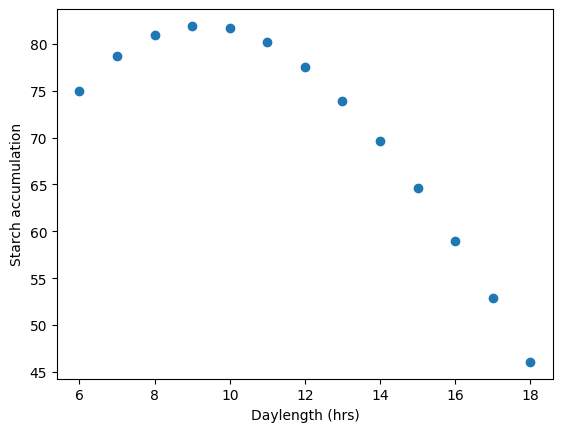

In [ ]:
import matplotlib.pyplot as plt

x = [6,7,8,9,10,11,12,13,14,15,16,17,18] #DAYLENGTH lIST
y = [75.00092868216908, 78.7589440064091, 80.99452440388104, 81.91963631612579, 81.7084652063195, 80.25262573190165, 77.5470584830717, 73.95827583536844, 69.61076119096397, 64.60572542785802, 59.01316169222255, 52.893502746119395, 46.06755859507329]#Starch accumulation
plt.xlabel("Daylength (hrs)")
plt.ylabel("Starch accumulation")

plt.scatter(x, y)
plt.show()

In [ ]:
StarchAccumRateList = []
StarchDegRatesumList=[]
Starchacc=[]
Starchdeg=[]
# Using a for loop simulate for different daylengths
for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
  StarchAccumRate = calculateTransitoryStarchLevels(C3_dup_model,daylength)
  StarchAccumRateList.append(StarchAccumRate)
  Starchacc.append((StarchAccumRate*daylength*3600/1000))

  StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup_model,daylength)
  StarchDegRatesumList.append(StarchDegRatesum)
  Starchdeg.append((abs(StarchDegRatesum)*(24-daylength)*3600/1000))
print(StarchAccumRateList )
print(StarchDegRatesumList)
print(Starchacc)
print(Starchdeg)


[18.43713074065938, 18.152248977774743, 17.895281302385683, 17.66227840281215, 17.450008312685696, 17.25579873953462, 17.072609529566016, 16.887216083569534, 16.717329040958862, 16.560952035862268, 16.416442359618593, 16.282430265312062, 16.157760806846454]
[6.145710246886461, 7.47445546143666, 8.947640651192843, 10.597367041687288, 12.464291651918357, 14.60106047191391, 17.07260952956602, 19.9576190078549, 23.40426065734241, 27.60158672643712, 32.832884719237185, 39.54304493004357, 48.47328242053939]
[398.2420239982426, 457.43667423992355, 515.3841015087077, 572.2578202511136, 628.2002992566851, 683.329630085571, 737.5367316772519, 790.3217127110543, 842.5533836643267, 894.2914099365624, 945.5870799140309, 996.4847322370982, 1047.0229002836502]
[398.24202399824264, 457.4366742399236, 515.3841015087078, 572.2578202511136, 628.2002992566852, 683.329630085571, 737.536731677252, 790.321712711054, 842.5533836643267, 894.2914099365627, 945.5870799140309, 996.484732237098, 1047.0229002836509

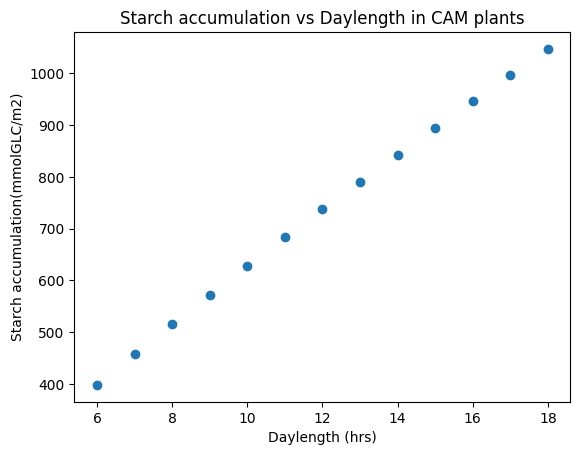

In [ ]:
import matplotlib.pyplot as plt

x = [6,7,8,9,10,11,12,13,14,15,16,17,18] #DAYLENGTH lIST
y = Starchacc#Starch accumulation
plt.xlabel("Daylength (hrs)")
plt.ylabel("Starch accumulation(mmolGLC/m2)")
plt.title("Starch accumulation vs Daylength in CAM plants")

plt.scatter(x, y)
plt.show()

In [ ]:
StarchAccumRateList = []
StarchDegRatesumList=[]
Starchacc=[]
Starchdeg=[]
# Using a for loop simulate for different daylengths
for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
  StarchAccumRate = calculateTransitoryStarchLevels(C3_dup_model,daylength)
  StarchAccumRateList.append(StarchAccumRate)
  Starchacc.append((StarchAccumRate*daylength*3600/1000))

  StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup_model,daylength)
  StarchDegRatesumList.append(StarchDegRatesum)
  Starchdeg.append((abs(StarchDegRatesum)*(24-daylength)*3600/1000))
print(StarchAccumRateList )
print(StarchDegRatesumList)
print(Starchacc)
print(Starchdeg)


[18.437130740659864, 18.152248977773404, 17.89528130238424, 17.662278402814838, 17.450008312685462, 17.255798739533773, 17.07260952956537, 16.887216083570113, 16.71732904095962, 16.560952035862538, 16.416442359618905, 16.2824302653215, 16.15776080685238]
[6.145710246886622, 7.474455461436107, 8.947640651192122, 10.597367041688901, 12.464291651918186, 14.601060471913195, 17.07260952956537, 19.957619007855588, 23.404260657343475, 27.60158672643757, 32.83288471923781, 39.54304493006651, 48.473282420557155]
['398.24202399825305', '457.4366742398898', '515.3841015086662', '572.2578202512008', '628.2002992566767', '683.3296300855375', '737.5367316772239', '790.3217127110813', '842.5533836643648', '894.2914099365771', '945.5870799140489', '996.4847322376759', '1047.022900284034']
['398.2420239982531', '457.4366742398898', '515.3841015086663', '572.2578202512007', '628.2002992566765', '683.3296300855376', '737.5367316772239', '790.3217127110812', '842.553383664365', '894.2914099365773', '945.5

In [ ]:
C3_dup2_model=C3_dup_model.copy()


In [ ]:
from cobra.io import write_sbml_model
C3_cons_model=write_sbml_model(C3_dup_model,'Without3atpppfdconst')

Constraining Day length

In [ ]:
C3_dup1_model=C3_dup_model.copy()


Updating the stoichiometric coefficients of Linker reactions for different daylengths

In [ ]:
C3_modelN = C3_dup1_model.copy()

daylength = 18


for rxn in C3_modelN.reactions.query("_dielTransfer"):
   #print(rxn.id,"  ",rxn.reaction)
   for met in rxn.reactants:
     stoich = rxn.metabolites[met]
     rxn.add_metabolites({met:round((-1*stoich)+(stoich*(24-daylength)/daylength),3)})#Equation from paper
     print(rxn.reaction)


0.33299999999999996 GLY_v_Light --> GLY_v_Dark
0.33299999999999996 ILE_v_Light --> ILE_v_Dark
0.33299999999999996 ARG_v_Light --> ARG_v_Dark
0.33299999999999996 THR_v_Light --> THR_v_Dark
0.33299999999999996 NITRATE_v_Light <=> NITRATE_v_Dark
0.33299999999999996 GLN_v_Light --> GLN_v_Dark
0.33299999999999996 L_ALPHA_ALANINE_v_Light --> L_ALPHA_ALANINE_v_Dark
0.33299999999999996 TYR_v_Light --> TYR_v_Dark
0.33299999999999996 MET_v_Light --> MET_v_Dark
0.33299999999999996 GLT_v_Light --> GLT_v_Dark
0.33299999999999996 VAL_v_Light --> VAL_v_Dark
0.33299999999999996 TRP_v_Light --> TRP_v_Dark
0.33299999999999996 4_AMINO_BUTYRATE_v_Light --> 4_AMINO_BUTYRATE_v_Dark
0.33299999999999996 SER_v_Light --> SER_v_Dark
0.33299999999999996 PHE_v_Light --> PHE_v_Dark
0.33299999999999996 CYS_v_Light --> CYS_v_Dark
0.33299999999999996 PROTON_v_Light <=> PROTON_v_Dark
0.33299999999999996 LEU_v_Light --> LEU_v_Dark
0.33299999999999996 L_ASPARTATE_v_Light --> L_ASPARTATE_v_Dark
0.33299999999999996 LYS_v_L

In [ ]:
#Verification
print("Original stoichiometry:")
print(C3_dup1_model.reactions.get_by_id("STARCH_p_dielTransferReverse").reaction)

print("\nNew stoichiometry:")
print(C3_modelN.reactions.get_by_id("STARCH_p_dielTransferReverse").reaction)

Original stoichiometry:
STARCH_p_Light <=> STARCH_p_Dark

New stoichiometry:
0.33299999999999996 STARCH_p_Light <=> STARCH_p_Dark


In [ ]:
C3_sol11 = pfba(C3_modelN)
print(C3_sol11)

<Solution 3076.765 at 0x792f19fb5ca0>


Back tracing reactions and their fluxes

In [ ]:
met=C3_modelN.metabolites.get_by_id("STARCH_p_Dark")
for rxn in met.reactions:
  print(rxn,"\t",rxn.flux*rxn.metabolites[met])

STARCH_p_dielTransferReverse: 0.33299999999999996 STARCH_p_Light <=> STARCH_p_Dark 	 2.3497332154493864
GLYCOGENSYN_RXN_p_Dark: ADP_D_GLUCOSE_p_Dark --> 0.8 ADP_p_Dark + 0.8 PROTON_p_Dark + STARCH_p_Dark + 0.2 aADP_p_Dark 	 0.0
RXN_1827_p_Dark: 2.0 STARCH_p_Dark + WATER_p_Dark --> MALTOSE_p_Dark 	 -2.3497332154493864
RXN_1826_p_Dark: Pi_p_Dark + STARCH_p_Dark --> GLC_1_P_p_Dark 	 -0.0
MALTODEXGLUCOSID_RXN_p_Dark: STARCH_p_Dark + WATER_p_Dark --> GLC_p_Dark 	 -0.0
Starch_biomass_Dark: Starch_b_Dark <-- STARCH_p_Dark 	 0.0


In [ ]:
met=C3_modelN.metabolites.get_by_id("STARCH_p_Light")
for rxn in met.reactions:
  print(rxn,"\t",rxn.flux*rxn.metabolites[met])

RXN_1826_p_Light: Pi_p_Light + STARCH_p_Light --> GLC_1_P_p_Light 	 -0.0
GLYCOGENSYN_RXN_p_Light: ADP_D_GLUCOSE_p_Light --> 0.8 ADP_p_Light + 0.8 PROTON_p_Light + STARCH_p_Light + 0.2 aADP_p_Light 	 0.7824611607446456
RXN_1827_p_Light: 2.0 STARCH_p_Light + WATER_p_Light --> MALTOSE_p_Light 	 -0.0
MALTODEXGLUCOSID_RXN_p_Light: STARCH_p_Light + WATER_p_Light --> GLC_p_Light 	 -0.0
Starch_biomass_Light: Starch_b_Light <-- STARCH_p_Light 	 0.0
STARCH_p_dielTransferReverse: 0.33299999999999996 STARCH_p_Light <=> STARCH_p_Dark 	 -0.7824611607446456


In [ ]:
met=C3_modelN.metabolites.get_by_id("MALTOSE_p_Dark")
for rxn in met.reactions:
  print(rxn,"\t",rxn.flux*rxn.metabolites[met])

RXN_1827_p_Dark: 2.0 STARCH_p_Dark + WATER_p_Dark --> MALTOSE_p_Dark 	 1.1748666077246932
RXN_14351_pc_Dark: MALTOSE_p_Dark --> MALTOSE_c_Dark 	 -1.1748666077246932
RXN_2141_p_Dark: MALTOSE_p_Dark + WATER_p_Dark --> 2.0 GLC_p_Dark 	 -0.0


In [ ]:
met=C3_modelN.metabolites.get_by_id("MALTOSE_c_Dark")
for rxn in met.reactions:
  print(rxn,"\t",rxn.flux*rxn.metabolites[met])

MALTODEG_RXN_c_Dark: MALTOSE_c_Dark <=> GLC_c_Dark + Heteroglycans_c_Dark 	 -1.1748666077246934
RXN_14351_pc_Dark: MALTOSE_p_Dark --> MALTOSE_c_Dark 	 1.1748666077246932


In [ ]:
met=C3_modelN.metabolites.get_by_id("GLC_c_Dark")
for rxn in met.reactions:
  print(rxn,"\t",rxn.flux*rxn.metabolites[met])

GLC_vc_Dark: GLC_v_Dark --> GLC_c_Dark 	 0.0
GLC_ec_Dark: GLC_e_Dark + PROTON_e_Dark --> GLC_c_Dark + PROTON_c_Dark 	 0.0
Phloem_output_tx_Dark: 0.0022970297 4_AMINO_BUTYRATE_c_Dark + 0.0004186704 ARG_c_Dark + 0.0015049505 ASN_c_Dark + 0.0004186704 CYS_c_Dark + 0.0792079208 FRU_c_Dark + 0.0693069307 GLC_c_Dark + 0.0240792079 GLN_c_Dark + 0.0124356436 GLT_c_Dark + 0.0007128713 GLY_c_Dark + 0.0004186704 HIS_c_Dark + 0.0017425743 ILE_c_Dark + 0.0020594059 LEU_c_Dark + 0.0022178218 LYS_c_Dark + 0.0038811881 L_ALPHA_ALANINE_c_Dark + 0.006019802 L_ASPARTATE_c_Dark + 0.0004186704 MET_c_Dark + 0.0057029703 PHE_c_Dark + 0.9603960396 PROTON_e_Dark + 0.0004186704 PRO_c_Dark + 0.003960396 SER_c_Dark + 0.0068910891 THR_c_Dark + 0.0004186704 TRP_c_Dark + 0.0004186704 TYR_c_Dark + 0.0027722772 VAL_c_Dark + 0.7326732673 sSUCROSE_b_Dark --> 0.9603960396 PROTON_c_Dark + phloem_transport_Dark 	 -0.0713522452770349
GLC_PROTON_rev_vc_Dark: GLC_c_Dark + PROTON_v_Dark --> GLC_v_Dark + PROTON_c_Dark 	 -0.0
CO

In [ ]:
met=C3_modelN.metabolites.get_by_id("Heteroglycans_c_Dark")
for rxn in met.reactions:
  print(rxn,"\t",rxn.flux*rxn.metabolites[met])

RXN0_5184_c_Dark: Heteroglycans_c_Dark + 0.7 Pi_c_Dark + 0.3 aPi_c_Dark <=> GLC_1_P_c_Dark + 0.3 PROTON_c_Dark 	 -1.1748666077283898
MALTODEG_RXN_c_Dark: MALTOSE_c_Dark <=> GLC_c_Dark + Heteroglycans_c_Dark 	 1.1748666077283898


In [ ]:
met=C3_model3.metabolites.get_by_id("FRUCTOSE_16_DIPHOSPHATE_p_Light")
for rxn in met.reactions:
  print(rxn,"\t",rxn.flux*rxn.metabolites[met])

F16ALDOLASE_RXN_p_Light: FRUCTOSE_16_DIPHOSPHATE_p_Light <=> DIHYDROXY_ACETONE_PHOSPHATE_p_Light + GAP_p_Light 	 19.64234653943507
6PFRUCTPHOS_RXN_p_Light: 0.9 ATP_p_Light + FRUCTOSE_6P_p_Light + 0.1 aATP_p_Light --> 0.8 ADP_p_Light + FRUCTOSE_16_DIPHOSPHATE_p_Light + 0.9 PROTON_p_Light + 0.2 aADP_p_Light 	 0.0
F16BDEPHOS_RXN_p_Light: FRUCTOSE_16_DIPHOSPHATE_p_Light + WATER_p_Light --> FRUCTOSE_6P_p_Light + Pi_p_Light 	 -19.64234653943507


In [ ]:
met=C3_model3.metabolites.get_by_id("DIHYDROXY_ACETONE_PHOSPHATE_p_Light")
for rxn in met.reactions:
  print(rxn,"\t",rxn.flux*rxn.metabolites[met])

DHAP_3PGA_pc_Light: DIHYDROXY_ACETONE_PHOSPHATE_p_Light + G3P_c_Light <=> DIHYDROXY_ACETONE_PHOSPHATE_c_Light + G3P_p_Light 	 -0.0
F16ALDOLASE_RXN_p_Light: FRUCTOSE_16_DIPHOSPHATE_p_Light <=> DIHYDROXY_ACETONE_PHOSPHATE_p_Light + GAP_p_Light 	 -19.64234653943507
TRIOSEPISOMERIZATION_RXN_p_Light: GAP_p_Light <=> DIHYDROXY_ACETONE_PHOSPHATE_p_Light 	 43.70304741135909
DHAP_Pi_pc_Light: DIHYDROXY_ACETONE_PHOSPHATE_p_Light + 0.7 Pi_c_Light + 0.3 aPi_c_Light <=> DIHYDROXY_ACETONE_PHOSPHATE_c_Light + 0.3 PROTON_c_Light + Pi_p_Light 	 -5.113304713314607
SEDOBISALDOL_RXN_p_Light: DIHYDROXY_ACETONE_PHOSPHATE_p_Light + ERYTHROSE_4P_p_Light --> D_SEDOHEPTULOSE_1_7_P2_p_Light 	 -18.9473961586094


In [ ]:
met=C3_model.metabolites.get_by_id('STARCH_p_Light')
for rxn in met.reactions:
  #if rxn.metabolites[met]>0:
   print(rxn,rxn.flux)

RXN_1827_p_Light: 2.0 STARCH_p_Light + WATER_p_Light --> MALTOSE_p_Light 0.0
MALTODEXGLUCOSID_RXN_p_Light: STARCH_p_Light + WATER_p_Light --> GLC_p_Light 0.0
STARCH_p_dielTransferReverse: 0.5 STARCH_p_Light <=> STARCH_p_Dark 1.7760237097197074
RXN_1826_p_Light: Pi_p_Light + STARCH_p_Light --> GLC_1_P_p_Light 0.0
Starch_biomass_Light: Starch_b_Light <-- STARCH_p_Light 0.0
GLYCOGENSYN_RXN_p_Light: ADP_D_GLUCOSE_p_Light --> 0.8 ADP_p_Light + 0.8 PROTON_p_Light + STARCH_p_Light + 0.2 aADP_p_Light 0.8880118548598537


In [ ]:
met1=C3_model.metabolites.get_by_id('STARCH_p_Dark')
for rxn in met1.reactions:
  if rxn.metabolites[met1]<0:
   print(rxn, "\t", rxn.flux*rxn.metabolites[met1])

RXN_1826_p_Dark: Pi_p_Dark + STARCH_p_Dark --> GLC_1_P_p_Dark 	 -0.0
RXN_1827_p_Dark: 2.0 STARCH_p_Dark + WATER_p_Dark --> MALTOSE_p_Dark 	 -1.7760237097197074
MALTODEXGLUCOSID_RXN_p_Dark: STARCH_p_Dark + WATER_p_Dark --> GLC_p_Dark 	 -0.0


RXN_1827_p_Light: 2.0 STARCH_p_Light + WATER_p_Light --> MALTOSE_p_Light 	 -0.0
MALTODEXGLUCOSID_RXN_p_Light: STARCH_p_Light + WATER_p_Light --> GLC_p_Light 	 -0.0
STARCH_p_dielTransferReverse: 0.5 STARCH_p_Light <=> STARCH_p_Dark 	 -0.8880118548598537
RXN_1826_p_Light: Pi_p_Light + STARCH_p_Light --> GLC_1_P_p_Light 	 -0.0
Starch_biomass_Light: Starch_b_Light <-- STARCH_p_Light 	 0.0
GLYCOGENSYN_RXN_p_Light: ADP_D_GLUCOSE_p_Light --> 0.8 ADP_p_Light + 0.8 PROTON_p_Light + STARCH_p_Light + 0.2 aADP_p_Light 	 0.8880118548598537


In [ ]:
# Starch synthesis reaction is identified
StarchSynDay = C3_modelN.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

# Number of moles of starch (GLC units) generated by the reaction is noted
StarchDayStoich = C3_modelN.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light").metabolites[C3_modelN.metabolites.get_by_id("STARCH_p_Light")]

# Print starch synthesis rate
print("Starch synthesis rate (umol GLC/m2/s) ="+str(StarchSynDay.flux*StarchDayStoich)) #Starch(in micromol) accumulated per m2 in 1s
print("Total starch accumulated over "+str(daylength)+"hr photoperiod (mmol GLC/m2) ="+str(StarchSynDay.flux*StarchDayStoich*daylength*3600/1000))#starch accumulated (in millimol)
print("")



# Starch degradation reactions is identified
StarchDegNight1 = C3_modelN.reactions.get_by_id("RXN_1827_p_Dark")
StarchDegNight2 = C3_modelN.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
StarchDegNight3 = C3_modelN.reactions.get_by_id("RXN_1826_p_Dark")

# Number of moles of starch (GLC units) generated by the reactions is noted
StarchNight1Stoich = C3_modelN.reactions.get_by_id("RXN_1827_p_Dark").metabolites[C3_modelN.metabolites.get_by_id("STARCH_p_Dark")]
StarchNight2Stoich = C3_modelN.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark").metabolites[C3_modelN.metabolites.get_by_id("STARCH_p_Dark")]
StarchNight3Stoich = C3_modelN.reactions.get_by_id("RXN_1826_p_Dark").metabolites[C3_modelN.metabolites.get_by_id("STARCH_p_Dark")]

# Print starch degradation rate (flux is converted to absolute values)
print("Starch degradation rate1 by hydrolysis (umol GLC/m2/s) ="+str((StarchDegNight1.flux*StarchNight1Stoich)))
print("Starch degradation rate2 by hydrolysis (umol GLC/m2/s) ="+str((StarchDegNight2.flux*StarchNight2Stoich)))
print("Starch degradation rate3 by hydrolysis (umol GLC/m2/s) ="+str((StarchDegNight3.flux*StarchNight3Stoich)))
print("Total starch degraded over "+str(24-daylength)+"hr photoperiod (mmol GLC/m2) ="+str(abs(((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich)))*(24-daylength)*3600/1000))

Starch synthesis rate (umol GLC/m2/s) =1.0245340571574681
Total starch accumulated over 16hr photoperiod (mmol GLC/m2) =59.01316169227017

Starch degradation rate1 by hydrolysis (umol GLC/m2/s) =-2.0490681143149363
Starch degradation rate2 by hydrolysis (umol GLC/m2/s) =-0.0
Starch degradation rate3 by hydrolysis (umol GLC/m2/s) =-0.0
Total starch degraded over 8hr photoperiod (mmol GLC/m2) =59.01316169227017


In [ ]:
def calculateTransitoryStarchLevels(Orig_model,daylength):
  new_model = Orig_model.copy()

  #update stoichiometry based on daylength
  for rxn in new_model.reactions.query("_dielTransfer"):
    for met in rxn.reactants:
      stoich = rxn.metabolites[met]
      rxn.add_metabolites({met:round((-1*stoich)+(stoich*(24-daylength)/daylength),20)})

  # perform pFBA
  tempsol = pfba(new_model)

  # Starch synthesis reaction is identified
  StarchSynDay = new_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")
  # Number of moles of starch (GLC units) generated by the reaction is noted
  StarchDayStoich = new_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light").metabolites[new_model.metabolites.get_by_id("STARCH_p_Light")]
  # Starch accumulation rate
  Answer = StarchSynDay.flux*StarchDayStoich
  return(Answer)

In [ ]:
for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
 print(round(-1+((-1*-1)+(-1*(24-daylength)/daylength)),3))

-3.0
-2.429
-2.0
-1.667
-1.4
-1.182
-1.0
-0.846
-0.714
-0.6
-0.5
-0.412
-0.333


In [ ]:
def calculateTransitoryDegStarchLevels(Orig_model,daylength):
  new_model1 = Orig_model.copy()

  #update stoichiometry based on daylength
  for rxn in new_model1.reactions.query("_dielTransfer"):
    for met in rxn.reactants:
      stoich = rxn.metabolites[met]
      rxn.add_metabolites({met:round((-1*stoich)+(stoich*(24-daylength)/daylength),20)})

  # perform pFBA
  tempsol = pfba(new_model1)

  # Starch degradation reaction is identified
  StarchDegNight1 = new_model1.reactions.get_by_id("RXN_1827_p_Dark")
  StarchDegNight2 = new_model1.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
  StarchDegNight3 = new_model1.reactions.get_by_id("RXN_1826_p_Dark")
  # Number of moles of starch (GLC units) degraded by the reaction is noted
  StarchNight1Stoich = new_model1.reactions.get_by_id("RXN_1827_p_Dark").metabolites[new_model1.metabolites.get_by_id("STARCH_p_Dark")]
  StarchNight2Stoich = new_model1.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark").metabolites[new_model1.metabolites.get_by_id("STARCH_p_Dark")]
  StarchNight3Stoich = new_model1.reactions.get_by_id("RXN_1826_p_Dark").metabolites[new_model1.metabolites.get_by_id("STARCH_p_Dark")]
  # Starch degradation rate
  Answer = abs((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich))
  return(Answer)

In [ ]:
daylengthList=[6,7,8,9,10,11,12,13,14,15,16,17,18]


In [ ]:
StarchAccumRateList = []
StarchDegRatesumList=[]
Starchacc=[]
Starchdeg=[]
# Using a for loop simulate for different daylengths
for daylength in daylengthList:
  StarchAccumRate = calculateTransitoryStarchLevels(C3_dup1_model,daylength)
  StarchAccumRateList.append(StarchAccumRate)
  Starchacc.append(str(StarchAccumRate*daylength*3600/1000))

  StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup1_model,daylength)
  StarchDegRatesumList.append(StarchDegRatesum)
  Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))
print(StarchAccumRateList )
print(StarchDegRatesumList)
print(Starchacc)
print(Starchdeg)


[3.47226521676797, 3.1253549208863425, 2.8123098751341207, 2.528383836915474, 2.2696795890681707, 2.0265814578748875, 1.7950707982186027, 1.5803050392156237, 1.3811658966454061, 1.1964023227395089, 1.0245340571571606, 0.8642729206885327, 0.7109191141213165]
[1.1574217389226569, 1.2869108497767292, 1.4061549375670601, 1.517030302149284, 1.6211997064772645, 1.7147996951249052, 1.795070798218603, 1.867633228163919, 1.9336322553035687, 1.9940038712325152, 2.0490681143143212, 2.098948521672151, 2.13275734236395]
['75.00092868218816', '78.75894400633584', '80.99452440386267', '81.91963631606136', '81.70846520645415', '80.25262573184554', '77.54705848304363', '73.95827583529119', '69.61076119092847', '64.60572542793348', '59.013161692252446', '52.893502746138196', '46.06755859506131']
['75.00092868218817', '78.75894400633582', '80.99452440386267', '81.91963631606134', '81.70846520645414', '80.25262573184555', '77.54705848304364', '73.95827583529119', '69.61076119092847', '64.60572542793349', 

In [ ]:
I=-1
starchaccNew2=[]
for n in daylengthList:
 I=I+1
 #print(I)
 starchaccNew2.append(float(Starchacc[I]))
 #print(float(Starchacc[I]))

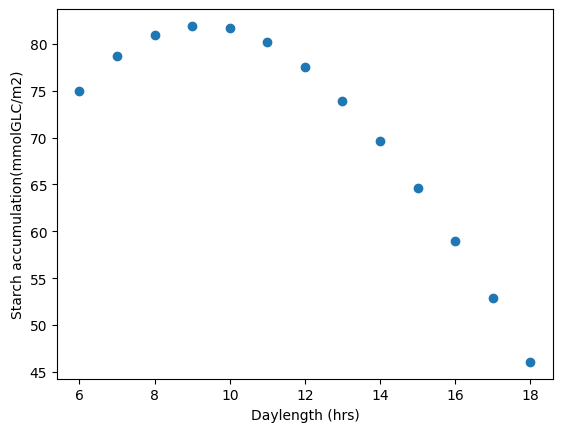

In [ ]:
import matplotlib.pyplot as plt

x = daylengthList #DAYLENGTH lIST
y = starchaccNew2#Starch accumulation
plt.xlabel("Daylength (hrs)")
plt.ylabel("Starch accumulation(mmolGLC/m2)")


plt.scatter(x, y)
plt.show()

In [ ]:
StarchAccumRateList=[3.47226521676797, 3.1253549208863425, 2.8123098751341207, 2.528383836915474, 2.2696795890681707, 2.0265814578748875, 1.7950707982186027, 1.5803050392156237, 1.3811658966454061, 1.1964023227395089, 1.0245340571571606, 0.8642729206885327, 0.7109191141213165]
StarchDegRatesumList=[1.1574217389226569, 1.2869108497767292, 1.4061549375670601, 1.517030302149284, 1.6211997064772645, 1.7147996951249052, 1.795070798218603, 1.867633228163919, 1.9336322553035687, 1.9940038712325152, 2.0490681143143212, 2.098948521672151, 2.13275734236395]
daylengthList=[6,7,8,9,10,11,12,13,14,15,16,17,18]

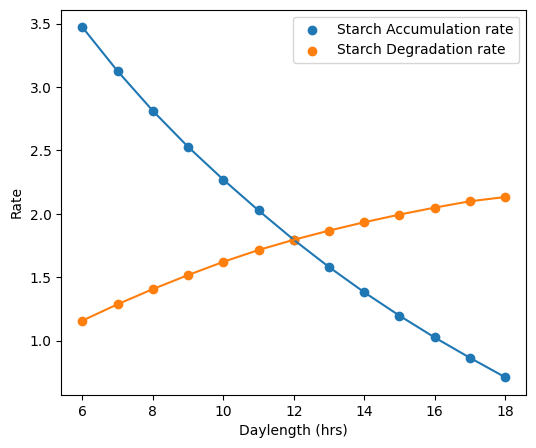

In [ ]:
import matplotlib.pyplot as plt

# Example data
daylength = [6,7,8,9,10,11,12,13,14,15,16,17,18]


# Single plot
plt.figure(figsize=(6,5))

plt.scatter(daylength, StarchAccumRateList, label='Starch Accumulation rate')
plt.scatter(daylength, StarchDegRatesumList, label='Starch Degradation rate')

# Optional: join points
plt.plot(daylength, StarchAccumRateList)
plt.plot(daylength, StarchDegRatesumList)

plt.xlabel("Daylength (hrs)")
plt.ylabel("Rate")
plt.legend()

plt.show()

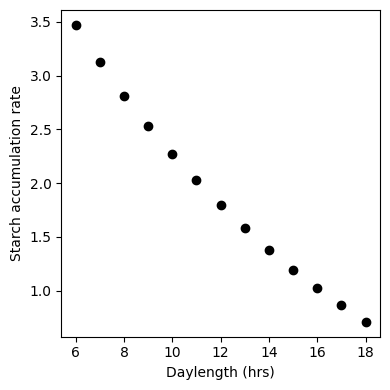

In [ ]:
from matplotlib import pyplot as plt

# Create two subplots side by side
fig, axs = plt.subplots(1, 1, figsize=(4, 4))  # 1 row, 2 columns

# Plot starch accumulation rate vs daylength
axs.scatter(daylengthList, StarchAccumRateList,color="black")
axs.set_xlabel("Daylength (hrs)")
axs.set_ylabel("Starch accumulation rate")


plt.tight_layout()
plt.show()


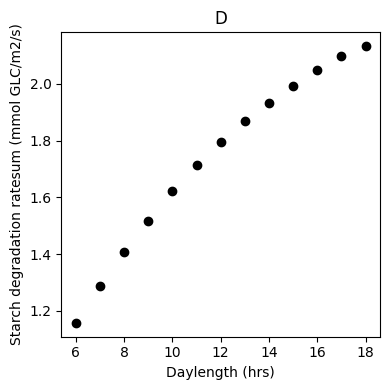

In [ ]:
from matplotlib import pyplot as plt

# Create two subplots side by side
fig, axs = plt.subplots(1, 1, figsize=(4, 4))  # 1 row, 2 columns

# Plot starch DEGRADATION rate vs daylength
axs.scatter(daylengthList, StarchDegRatesumList,color="black")
axs.set_xlabel("Daylength (hrs)")
axs.set_ylabel("Starch degradation ratesum (mmol GLC/m2/s)")
axs.set_title("D")

plt.tight_layout()
plt.show()

Starch accumulation vs Daylength in different values of maintainance cost

In [ ]:
#To be deleted
pfba(C3_dup_model)

,fluxes,reduced_costs
PRO_PROTON_vc_Light,0.000000,-0.666667
Ca_tx_Light,0.000000,2.000000
H2O_xc_Light,14.386271,-2.000000
sCIT_biomass_Light,0.000000,2.000000
ACETYLGLUTKIN_RXN_p_Light,0.001113,-2.000000
...,...,...
SUCROSE_v_dielTransferReverse,0.000000,-1207.528141
PRO_v_dielTransfer,0.000000,1382.249342
CIT_v_dielTransferReverse,-0.106853,2.000000
HIS_v_dielTransfer,0.000000,10562.568470


In [ ]:
def maintenancecost(org_model,n):
  PPFD=500
  VATPase = (0.0049*PPFD) + 2.7851#From cheung paper
  Model_new=org_model.copy()
  Model_new.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase*n,VATPase*n)
  pfba(Model_new)

  StarchAccumRateList = []
  #StarchDegRatesumList=[]
  Starchacc=[]
  #Starchdeg=[]
  # Using a for loop simulate for different daylengths
  for daylength in [6,9,12,15,18]:
      StarchAccumRate = calculateTransitoryStarchLevels(Model_new,daylength)
      StarchAccumRateList.append(StarchAccumRate)
      Starchacc.append(round(StarchAccumRate*daylength*3600/1000,6))

      #StarchDegRatesum= calculateTransitoryDegStarchLevels(Model_new,daylength)
      #StarchDegRatesumList.append(StarchDegRatesum)
      #Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))
  print(Starchacc)
    #print(Starchdeg)


In [ ]:
for m in [0,0.5,1,1.5,2]:
  maintenancecost(C3_dup_model,m)

[67.633567, 74.027466, 70.630562, 58.720795, 40.619016]
[71.306181, 77.960077, 74.013223, 61.62231, 43.776477]
[75.000929, 81.919636, 77.547058, 64.605725, 46.067559]
[78.695677, 85.879195, 81.074301, 67.589141, 48.35864]
[82.390424, 89.838755, 84.581851, 70.572556, 50.649722]


In [ ]:
a1=[67.633567, 74.027466, 70.630562, 58.720795, 40.619016]
a2=[71.306181, 77.960077, 74.013223, 61.62231, 43.776477]
a3=[75.000929, 81.919636, 77.547058, 64.605725, 46.067559]
a4=[78.695677, 85.879195, 81.074301, 67.589141, 48.35864]
a5=[82.390424, 89.838755, 84.581851, 70.572556, 50.649722]
dL=[6,9,12,15,18]

In [ ]:
import pandas as pd
import numpy as np
data={"daylength":dL,"0":a1,"0.5":a2,"1":a3,"1.5":a4,"2":a5}
DF3=pd.DataFrame(data)
print(DF3)
DF3 = DF3.set_index("daylength")


   daylength          0        0.5          1        1.5          2
0          6  67.633567  71.306181  75.000929  78.695677  82.390424
1          9  74.027466  77.960077  81.919636  85.879195  89.838755
2         12  70.630562  74.013223  77.547058  81.074301  84.581851
3         15  58.720795  61.622310  64.605725  67.589141  70.572556
4         18  40.619016  43.776477  46.067559  48.358640  50.649722


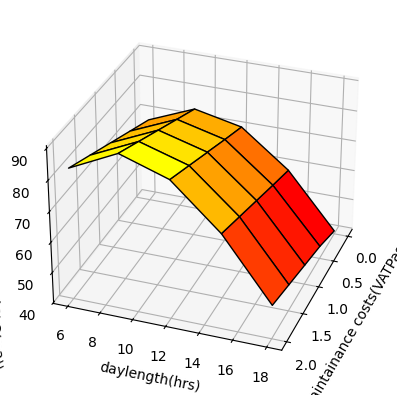

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(DF3.columns.astype(float),DF3.index)
z = DF3.values.astype(float)



fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('Maintainance costs(VATPase)')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('starch accumulation((mmolGLC/m2))')



ax.plot_surface(x,y,z,cmap='autumn',edgecolor='black')
ax.view_init(elev=30, azim=20)
plt.show()

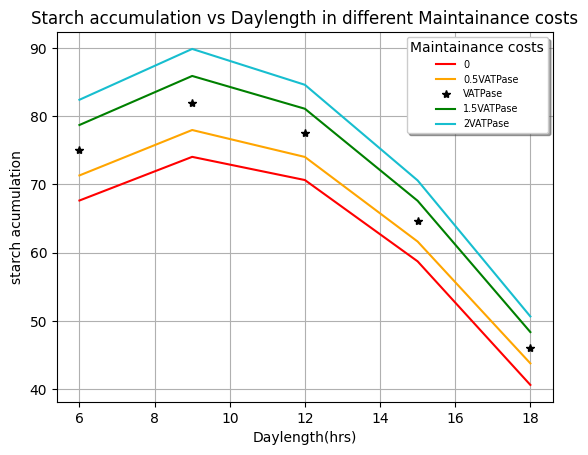

In [ ]:
import matplotlib.pyplot as plt
a = [6,9,12,15,18]
fig, ax=plt.subplots()
ax.plot(a,a1,'red',label='0')
ax.plot(a,a2,'orange',label='0.5VATPase')
ax.plot(a,a3,'k*',label='VATPase')
ax.plot(a,a4,'green',label='1.5VATPase')
ax.plot(a,a5,'C9',label='2VATPase')


legend=ax.legend(loc="upper right",shadow=True,fontsize='x-small',title='Maintainance costs')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch accumulation vs Daylength in different Maintainance costs')

plt.grid()
plt.show()

In [ ]:
S1=['67.63356698801671', '73.13583892330182', '73.7182290942077', '74.02747523739534', '74.08205591669933', '73.89887648935843', '44.15917936947099']
S2=['71.3061808422584', '77.05201764610642', '77.65033847921741', '77.9600873528644', '78.0008108006773', '77.79038878172959', '48.552694955042']
S3=['75.00092868218816', '80.99452440386267', '81.60921123475465', '81.9196469747418', '81.94644631854834', '81.70846520643336', '50.75885327606169']
S4=['78.69567652215154', '84.93703116163621', '85.56808399056654', '85.87920659656508', '85.89208183658796', '85.62654163093084', '52.96501159686667']
S5=['82.39042436207627', '88.87953791932503', '89.52695674627978', '89.8387662183669', '89.83771735471441', '89.38569504748114', '55.171169917064795']
dl=[6,8,8.5,9,9.5,10,18]

In [ ]:
import pandas as pd
import numpy as np
data={"daylength":dl,"0":S1," 2.6175499999999996":S2,"5.235099999999999":S3,"7.852649999999999":S4,"10.470199999999998":S5}
df=pd.DataFrame(data)
print(df)
df = df.set_index("daylength")


   daylength                  0  2.6175499999999996  5.235099999999999  \
0        6.0  67.63356698801671    71.3061808422584  75.00092868218816   
1        8.0  73.13583892330182   77.05201764610642  80.99452440386267   
2        8.5   73.7182290942077   77.65033847921741  81.60921123475465   
3        9.0  74.02747523739534    77.9600873528644   81.9196469747418   
4        9.5  74.08205591669933    78.0008108006773  81.94644631854834   
5       10.0  73.89887648935843   77.79038878172959  81.70846520643336   
6       18.0  44.15917936947099     48.552694955042  50.75885327606169   

   7.852649999999999  10.470199999999998  
0  78.69567652215154   82.39042436207627  
1  84.93703116163621   88.87953791932503  
2  85.56808399056654   89.52695674627978  
3  85.87920659656508    89.8387662183669  
4  85.89208183658796   89.83771735471441  
5  85.62654163093084   89.38569504748114  
6  52.96501159686667  55.171169917064795  


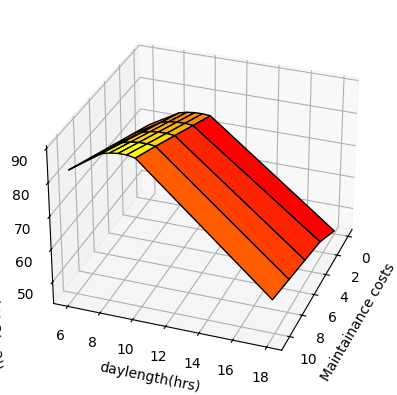

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(df.columns.astype(float),df.index)
z = df.values.astype(float)



fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('Maintainance costs')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('starch accumulation((mmolGLC/m2))')



ax.plot_surface(x,y,z,cmap='autumn',edgecolor='black')
ax.view_init(elev=30, azim=20)
plt.show()

In [ ]:
S1=['67.63356698801671', '73.13583892330182', '73.7182290942077', '74.02747523739534', '74.08205591669933', '73.89887648935843', '44.15917936947099']
S2=['71.3061808422584', '77.05201764610642', '77.65033847921741', '77.9600873528644', '78.0008108006773', '77.79038878172959', '48.552694955042']
S3=['75.00092868218816', '80.99452440386267', '81.60921123475465', '81.9196469747418', '81.94644631854834', '81.70846520643336', '50.75885327606169']
S4=['78.69567652215154', '84.93703116163621', '85.56808399056654', '85.87920659656508', '85.89208183658796', '85.62654163093084', '52.96501159686667']
S5=['82.39042436207627', '88.87953791932503', '89.52695674627978', '89.8387662183669', '89.83771735471441', '89.38569504748114', '55.171169917064795']


In [ ]:
I=-1
starchaccNew=[]
for n in range(7):
 I=I+1
 starchaccNew.append(round(float(S5[I]),1))
print(starchaccNew)

[82.4, 88.9, 89.5, 89.8, 89.8, 89.4, 55.2]


In [ ]:
S1=[67.6, 73.1, 73.7, 74.0, 74.1, 73.9, 44.2]
S2=[71.3, 77.1, 77.7, 78.0, 78.0, 77.8, 48.6]
S3=[75.0, 81.0, 81.6, 81.9, 81.9, 81.7, 50.8]
S4=[78.7, 84.9, 85.6, 85.9, 85.9, 85.6, 53.0]
S5=[82.4, 88.9, 89.5, 89.8, 89.8, 89.4, 55.2]


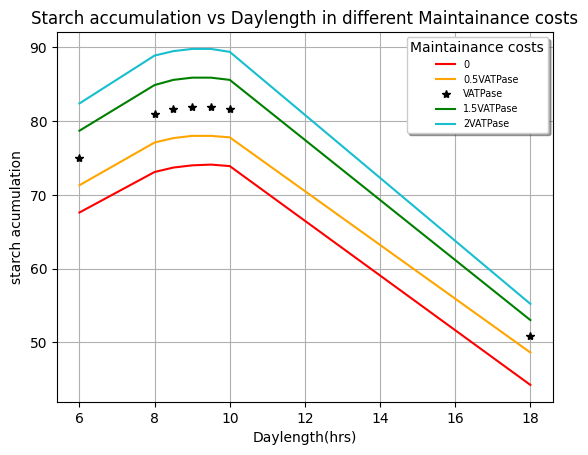

In [ ]:
import matplotlib.pyplot as plt
a = [6,8,8.5,9,9.5,10,18]
fig, ax=plt.subplots()
ax.plot(a,S1,'red',label='0')
ax.plot(a,S2,'orange',label='0.5VATPase')
ax.plot(a,S3,'k*',label='VATPase')
ax.plot(a,S4,'green',label='1.5VATPase')
ax.plot(a,S5,'C9',label='2VATPase')


legend=ax.legend(loc="upper right",shadow=True,fontsize='x-small',title='Maintainance costs')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch accumulation vs Daylength in different Maintainance costs')

plt.grid()
plt.savefig("plot.png", dpi=300, bbox_inches='tight')
plt.show()

DAYLENGTH VS STARCH ACCUMULATION IN DIFFERENT atp:nadph ratio

In [ ]:
#C3_dup1_model=C3_dup_model.copy() without atp:nadph ratio constraint
#[0.5,0.75,1.5,3,4.5,6]

In [ ]:
def ATPvNADPH (org_model,m):
    Model_new=org_model.copy()
    #Day
    NGAM_constraint=Model_new.problem.Constraint(m*(Model_new.reactions.NADPHoxc_tx_Light.flux_expression+Model_new.reactions.NADPHoxm_tx_Light.flux_expression+Model_new.reactions.NADPHoxp_tx_Light.flux_expression)-Model_new.reactions.ATPase_tx_Light.flux_expression,
                                                    lb=0,ub=0)
    Model_new.add_cons_vars(NGAM_constraint)

    pfba(Model_new)

    StarchAccumRateList = []
    StarchDegRatesumList=[]
    Starchacc=[]
    Starchdeg=[]
    # Using a for loop simulate for different daylengths
    for daylength in [6,9,12,15,18]:
      StarchAccumRate = calculateTransitoryStarchLevels(Model_new,daylength)
      StarchAccumRateList.append(StarchAccumRate)
      Starchacc.append(str(StarchAccumRate*daylength*3600/1000))

      #StarchDegRatesum= calculateTransitoryDegStarchLevels(Model_new,daylength)
      #StarchDegRatesumList.append(StarchDegRatesum)
      #Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))
    #print(StarchAccumRateList)
    #print(StarchDegRatesumList)
    print(Starchacc)
    #print(Starchdeg)



In [ ]:
for m in [0.5,0.75,1.5,3,4.5]:
  ATPvNADPH(C3_dup_model_back,m)

['94.70734506613094', '103.04272624409839', '98.1129174058669', '84.2459716173708', '61.86715798738475']
['86.82477851255156', '94.59349027292734', '90.24037379910399', '77.54272494599999', '55.63997361012415']
['78.9422119589872', '86.14425430172619', '82.36783019230391', '68.97202017812442', '49.41278923282338']
['75.00092868219272', '81.91963631604699', '77.54705848295585', '64.60572542763498', '46.06755859491273']
['73.68716758982845', '80.51143032086863', '75.7930488404406', '63.15029384423697', '45.26653314626846']


In [ ]:
b1=['94.70734506613094', '103.04272624409839', '98.1129174058669', '84.2459716173708', '61.86715798738475']
b2=['86.82477851255156', '94.59349027292734', '90.24037379910399', '77.54272494599999', '55.63997361012415']
b3=['78.9422119589872', '86.14425430172619', '82.36783019230391', '68.97202017812442', '49.41278923282338']
b4=['75.00092868219272', '81.91963631604699', '77.54705848295585', '64.60572542763498', '46.06755859491273']
b5=['73.68716758982845', '80.51143032086863', '75.7930488404406', '63.15029384423697', '45.26653314626846']


In [ ]:
import pandas as pd
import numpy as np
data2={"daylength":dL,"0.5":b1,"0.75":b2,"1.5":b3,"3":b4,"4.5":b5}
DF2=pd.DataFrame(data2)
print(DF2)
DF2 = DF2.set_index("daylength")

   daylength                 0.5               0.75                1.5  \
0          6   94.70734506613094  86.82477851255156   78.9422119589872   
1          9  103.04272624409839  94.59349027292734  86.14425430172619   
2         12    98.1129174058669  90.24037379910399  82.36783019230391   
3         15    84.2459716173708  77.54272494599999  68.97202017812442   
4         18   61.86715798738475  55.63997361012415  49.41278923282338   

                   3                4.5  
0  75.00092868219272  73.68716758982845  
1  81.91963631604699  80.51143032086863  
2  77.54705848295585   75.7930488404406  
3  64.60572542763498  63.15029384423697  
4  46.06755859491273  45.26653314626846  


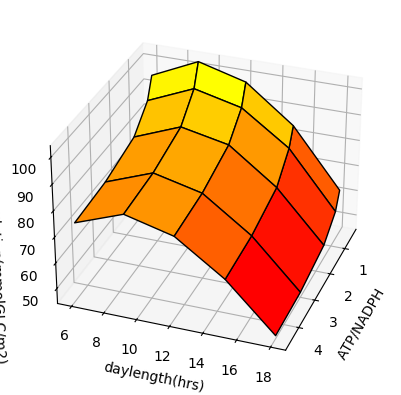

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(DF2.columns.astype(float),DF2.index)
z = DF2.values.astype(float)



fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('ATP/NADPH ')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('strach accumulation(mmolGLC/m2)')


#rgb = LightSource(270, 45).shade(z, cmap=plt.cm.cool, vert_exag=0.00001, blend_mode='soft')
#surf = ax.plot_surface(x, y, z,facecolors=rgb,
                       #linewidth=0, antialiased=False, shade=False,edgecolor='green')
ax.plot_surface(x, y, z, cmap='autumn', edgecolor='black')
ax.view_init(elev=30, azim=20)
plt.show()

In [ ]:
S1=['94.70734506615021', '102.0250619318666', '102.72782015901264', '103.04273940239352', '102.99612858254724', '102.61204651317033', '61.86710503446346']
S2=['86.8247785125503', '93.61284692067265', '94.2803765893219', '94.59350243135509', '94.57625567695044', '94.25061399041704', '57.70864947723146']
S3=['78.94221195896907', '85.20063190945767', '85.83293301965178', '86.14426546020565', '86.15638277140256', '85.88918146769358', '53.0754520097678']
S4=['75.00092868217796', '80.99452440388667', '81.60921123476209', '81.91964697480527', '81.94644631865052', '81.70846520631902', '50.75885327741497']
S5=['73.68716758988332', '79.59248856867055', '80.20130397323373', '80.51144081287516', '80.5431341676456', '80.1699815290037', '49.98665369827429']
S6=['73.03028704381376', '78.8914706510796', '79.49735034244482', '79.80733773202401', '79.70481723177163', '79.24515914258997', '49.6005539104754']

dl=[6,8,8.5,9,9.5,10,18]

In [ ]:
import pandas as pd
import numpy as np
data2={"daylength":dl,"0.5":S1,"0.75":S2,"1.5":S3,"3":S4,"4.5":S5,"6":S6}
df2=pd.DataFrame(data2)
print(df2)
df2 = df2.set_index("daylength")

   daylength                 0.5               0.75                1.5  \
0        6.0   94.70734506615021   86.8247785125503  78.94221195896907   
1        8.0   102.0250619318666  93.61284692067265  85.20063190945767   
2        8.5  102.72782015901264   94.2803765893219  85.83293301965178   
3        9.0  103.04273940239352  94.59350243135509  86.14426546020565   
4        9.5  102.99612858254724  94.57625567695044  86.15638277140256   
5       10.0  102.61204651317033  94.25061399041704  85.88918146769358   
6       18.0   61.86710503446346  57.70864947723146   53.0754520097678   

                   3                4.5                  6  
0  75.00092868217796  73.68716758988332  73.03028704381376  
1  80.99452440388667  79.59248856867055   78.8914706510796  
2  81.60921123476209  80.20130397323373  79.49735034244482  
3  81.91964697480527  80.51144081287516  79.80733773202401  
4  81.94644631865052   80.5431341676456  79.70481723177163  
5  81.70846520631902   80.1699815290037  

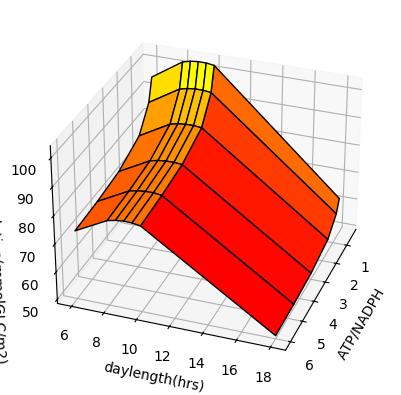

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(df2.columns.astype(float),df2.index)
z = df2.values.astype(float)



fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('ATP/NADPH ')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('strach accumulation(mmolGLC/m2)')


#rgb = LightSource(270, 45).shade(z, cmap=plt.cm.cool, vert_exag=0.00001, blend_mode='soft')
#surf = ax.plot_surface(x, y, z,facecolors=rgb,
                       #linewidth=0, antialiased=False, shade=False,edgecolor='green')
ax.plot_surface(x, y, z, cmap='autumn', edgecolor='black')
ax.view_init(elev=30, azim=20)
plt.show()

In [ ]:
for m in [0.5,0.75,1.5,3,4.5,6]:
  ATPvNADPH(C3_dup_model,m)

[94.70734506615165, 99.33677281393524, 102.0250619318666, 103.0427262441137, 102.61204651317031, 100.91737723196582, 98.11291740589735, 94.32864478564629, 89.67490087220187, 84.24597161737297, 78.12291150720594, 70.57780473271663, 61.86715798761886]
[86.82477851255778, 91.10564129092374, 93.61284692067265, 94.59349027289369, 94.25061399041704, 92.75262147009188, 90.24037379910138, 86.83260943244241, 82.63013166312685, 77.54272494602331, 70.91144194214785, 63.56931986962861, 55.63997361009701]
[78.94221195891951, 82.87450976787903, 85.20063190945767, 86.14425430169136, 85.88918146769238, 84.5878657082904, 82.36783019232442, 78.90439145567878, 74.33061789230429, 68.97202017811662, 62.99030584549599, 56.45210845408748, 49.412789232924275]
[75.00092868217796, 78.7589440063816, 80.99452440388667, 81.91963631608215, 81.70846520635527, 80.2526257318512, 77.54705848294995, 73.95827583543016, 69.61076119093066, 64.60572542782666, 59.01316169222915, 52.893502746760035, 46.06755859504834]
[73.687

In [ ]:
As1=[94.70734506615165, 99.33677281393524, 102.0250619318666, 103.0427262441137, 102.61204651317031, 100.91737723196582, 98.11291740589735, 94.32864478564629, 89.67490087220187, 84.24597161737297, 78.12291150720594, 70.57780473271663, 61.86715798761886]
As2=[86.82477851255778, 91.10564129092374, 93.61284692067265, 94.59349027289369, 94.25061399041704, 92.75262147009188, 90.24037379910138, 86.83260943244241, 82.63013166312685, 77.54272494602331, 70.91144194214785, 63.56931986962861, 55.63997361009701]
As3=[78.94221195891951, 82.87450976787903, 85.20063190945767, 86.14425430169136, 85.88918146769238, 84.5878657082904, 82.36783019232442, 78.90439145567878, 74.33061789230429, 68.97202017811662, 62.99030584549599, 56.45210845408748, 49.412789232924275]
As4=[75.00092868217796, 78.7589440063816, 80.99452440388667, 81.91963631608215, 81.70846520635527, 80.2526257318512, 77.54705848294995, 73.95827583543016, 69.61076119093066, 64.60572542782666, 59.01316169222915, 52.893502746760035, 46.06755859504834]
As5=[73.68716758988332, 77.38708875249053, 79.59248856867055, 80.5114303209491, 80.16998152900054, 78.45949654379028, 75.79304884047457, 72.27744879558426, 68.03652714186755, 63.15029384415986, 57.68744697454502, 51.24726695498074, 45.26653314647113]
As6=[73.03028704380058, 76.70116112567577, 78.8914706510796, 79.80732732328042, 79.24515914242215, 77.56293194984185, 74.90619754419846, 71.43703527604221, 67.2494101174251, 62.42257805252699, 57.024589615537536, 50.66669409708074, 44.86602042183825]


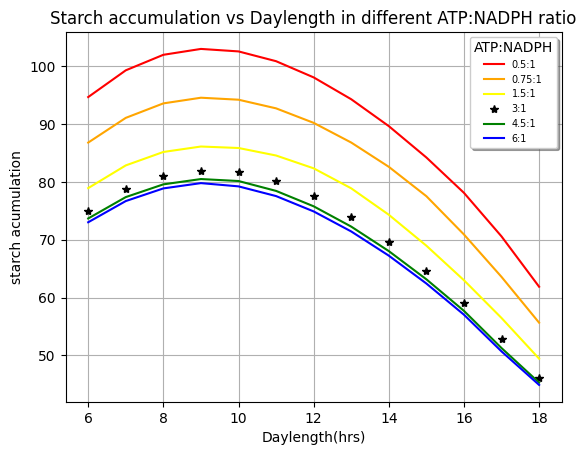

In [ ]:
#[0.5,0.75,1.5,3,4.5,6]
import matplotlib.pyplot as plt
a = [6,7,8,9,10,11,12,13,14,15,16,17,18]
fig, ax=plt.subplots()
ax.plot(a,As1,'red',label='0.5:1')
ax.plot(a,As2,'orange',label='0.75:1')
ax.plot(a,As3,'yellow',label='1.5:1')
ax.plot(a,As4,'k*',label='3:1')
ax.plot(a,As5,'green',label='4.5:1')
ax.plot(a,As6,'blue',label='6:1')
legend=ax.legend(loc="upper right",shadow=True,fontsize='x-small',title='ATP:NADPH')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch accumulation vs Daylength in different ATP:NADPH ratio')
plt.grid()
plt.savefig("plot.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
S1=['102.0250619318666', '102.72782015901264', '103.04273940239352', '102.99612858254724', '102.61204651317033']
S2=['93.61284692067265', '94.2803765893219', '94.59350243135509', '94.57625567695044', '94.25061399041704']
S3=['85.20063190945767', '85.83293301965178', '86.14426546020565', '86.15638277140256', '85.88918146769358']
S4=['80.99452440388667', '81.60921123476209', '81.91964697480527', '81.94644631865052', '81.70846520631902']
S5=['79.59248856867055', '80.20130397323373', '80.51144081287516', '80.5431341676456', '80.1699815290037']
S6=['78.8914706510796', '79.49735034244482', '79.80733773202401', '79.70481723177163', '79.24515914258997']
dl=[8,8.5,9,9.5,10]

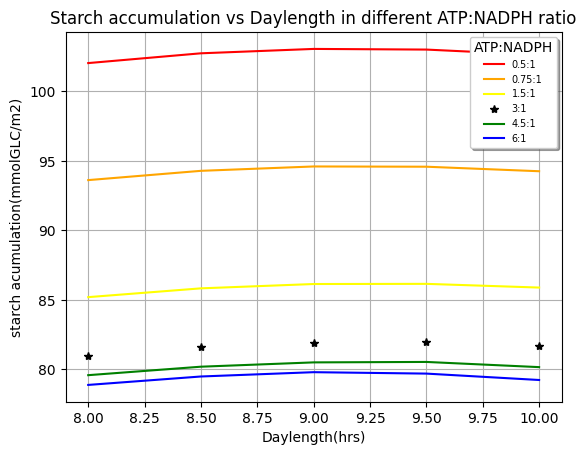

In [ ]:
#[0.5,0.75,1.5,3,4.5,6]
import matplotlib.pyplot as plt
a = [8,8.5,9,9.5,10]
fig, ax=plt.subplots()
ax.plot(a,s1,'red',label='0.5:1')
ax.plot(a,s2,'orange',label='0.75:1')
ax.plot(a,s3,'yellow',label='1.5:1')
ax.plot(a,s4,'k*',label='3:1')
ax.plot(a,s5,'green',label='4.5:1')
ax.plot(a,s6,'blue',label='6:1')
legend=ax.legend(loc="upper right",shadow=True,fontsize='x-small',title='ATP:NADPH')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation(mmolGLC/m2)')
plt.title('Starch accumulation vs Daylength in different ATP:NADPH ratio')
plt.grid()
plt.show()

Starch accumulation vs Daylength for different Day:Night ratio of ATP and NADPH requirments


In [ ]:
ModelNNN=C3_dup1_model.copy()#constrained without day:Night ratio of ATP and NADPH

In [ ]:
def daynightAN(org_model,h):

    Model_new1=org_model.copy()

    atpdaynightconstraint=Model_new1.problem.Constraint(Model_new1.reactions.ATPase_tx_Light.flux_expression-h*Model_new1.reactions.ATPase_tx_Dark.flux_expression,
                                                lb=0,ub=0)
    Model_new1.add_cons_vars(atpdaynightconstraint)
    pfba(Model_new1)

    StarchAccumRateList = []
    #StarchDegRatesumList=[]
    Starchacc=[]
    #Starchdeg=[]
    # Using a for loop simulate for different daylengths
    for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
      StarchAccumRate = calculateTransitoryStarchLevels(Model_new1,daylength)
      StarchAccumRateList.append(StarchAccumRate)
      Starchacc.append(StarchAccumRate*daylength*3600/1000)

      #StarchDegRatesum= calculateTransitoryDegStarchLevels(Model_new1,daylength)
      #StarchDegRatesumList.append(StarchDegRatesum)
      #Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))

    print(Starchacc)
    #print(Starchdeg)


In [ ]:
for v in [0.25,0.3,0.5,1,2]:
 daynightAN(C3_dup_model_back_2,v)

['100.2292123113759', '109.15071550605039', '102.74871399907282', '85.9443988962929', '62.24646736255336']
['94.88247203830525', '103.3133276489637', '97.1527223176274', '81.20247145874318', '58.651154303106864']
['83.71184745029687', '91.28504837445497', '85.96073895503251', '71.71861658393696', '51.46052818421265']
['75.0009286821794', '81.91963631611675', '77.54705848302179', '64.60572542777932', '46.067558595183314']
['70.6454692980635', '77.23693028687626', '73.3244855288764', '61.04927984977346', '43.37107380055984']


In [ ]:
c1=['100.2292123113759', '109.15071550605039', '102.74871399907282', '85.9443988962929', '62.24646736255336']
c2=['94.88247203830525', '103.3133276489637', '97.1527223176274', '81.20247145874318', '58.651154303106864']
c3=['83.71184745029687', '91.28504837445497', '85.96073895503251', '71.71861658393696', '51.46052818421265']
c4=['75.0009286821794', '81.91963631611675', '77.54705848302179', '64.60572542777932', '46.067558595183314']
c5=['70.6454692980635', '77.23693028687626', '73.3244855288764', '61.04927984977346', '43.37107380055984']
dL=[6,9,12,15,18]

In [ ]:
import pandas as pd
import numpy as np
data={"daylength":dL,"0.25":c1,"0.3":c2,"0.5":c3,"1":c4,"2":c5}
DF1=pd.DataFrame(data)
print(DF1)
DF1 = DF1.set_index("daylength")

   daylength                0.25                 0.3                0.5  \
0          6   100.2292123113759   94.88247203830525  83.71184745029687   
1          9  109.15071550605039   103.3133276489637  91.28504837445497   
2         12  102.74871399907282    97.1527223176274  85.96073895503251   
3         15    85.9443988962929   81.20247145874318  71.71861658393696   
4         18   62.24646736255336  58.651154303106864  51.46052818421265   

                    1                  2  
0    75.0009286821794   70.6454692980635  
1   81.91963631611675  77.23693028687626  
2   77.54705848302179   73.3244855288764  
3   64.60572542777932  61.04927984977346  
4  46.067558595183314  43.37107380055984  


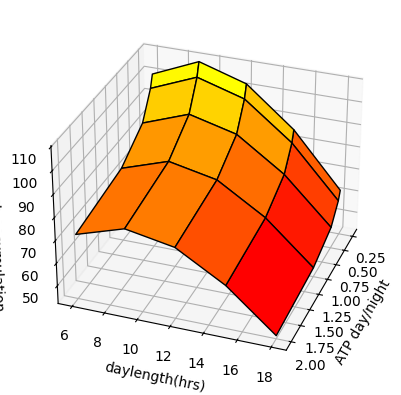

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(DF1.columns.astype(float),DF1.index)
z = DF1.values.astype(float)

fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('ATP day/night')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('starch accumulation')

#fig = plt.figure(figsize=(20, 20))
#rgb = LightSource(270, 45).shade(z, cmap=plt.cm.autumn, vert_exag=0.1, blend_mode='soft')
# surf = ax.plot_surface(x, y, z,facecolors=rgb,
#                        linewidth=0, antialiased=False, shade=False)
ax.plot_surface(x, y, z, cmap='autumn', edgecolor='black')
ax.view_init(elev=30, azim=20)
plt.show()

In [ ]:
accum1=['100.22921231136011', '108.17413354699447', '108.88958163525353', '109.15072864788402', '108.98879725784742', '108.43230559064257', '66.71324524466154']
accum2=['83.71184745049425', '90.30841749435852', '90.96721026385607', '91.28506015936324', '91.28507934765177', '90.84475204690146', '56.0769839326035']
accum3=['75.00092868215756', '80.99452440386477', '81.60921123483423', '81.91964697472604', '81.9464463185917', '81.70846520630629', '50.758853370029094']
accum4=['70.64546929813879', '76.33757785860568', '76.93021172034734', '77.23694038248551', '77.27712980413514', '77.06849475593155', '48.09978804245515']
accum5=['69.19364950344081', '74.7852623435188', '75.37054521545305', '75.67603818508863', '75.7206909659995', '75.52183793909184', '47.21343283838232']
accum6=['68.46773960614546', '74.00910458592105', '74.59071196316125', '74.89558708640794', '74.94247154696372', '74.74850953073157', '46.77025528390185']
accum7=['68.03219366768275', '73.54340993140812', '74.12281201161386', '74.42731642708563', '74.47553989540194', '74.28451248565494', '46.38432879433019']

dl=[6,8,8.5,9,9.5,10,18]

In [ ]:
import pandas as pd
import numpy as np
data3={"daylength":dl,"0.25":accum1,"0.5":accum2,"1":accum3,"2":accum4,"3":accum5,"4":accum6,"5":accum7}
df3=pd.DataFrame(data3)
print(df3)
df3 = df3.set_index("daylength")


   daylength                0.25                0.5                   1  \
0        6.0  100.22921231136011  83.71184745049425   75.00092868215756   
1        8.0  108.17413354699447  90.30841749435852   80.99452440386477   
2        8.5  108.88958163525353  90.96721026385607   81.60921123483423   
3        9.0  109.15072864788402  91.28506015936324   81.91964697472604   
4        9.5  108.98879725784742  91.28507934765177    81.9464463185917   
5       10.0  108.43230559064257  90.84475204690146   81.70846520630629   
6       18.0   66.71324524466154   56.0769839326035  50.758853370029094   

                   2                  3                  4                  5  
0  70.64546929813879  69.19364950344081  68.46773960614546  68.03219366768275  
1  76.33757785860568   74.7852623435188  74.00910458592105  73.54340993140812  
2  76.93021172034734  75.37054521545305  74.59071196316125  74.12281201161386  
3  77.23694038248551  75.67603818508863  74.89558708640794  74.42731642708563  

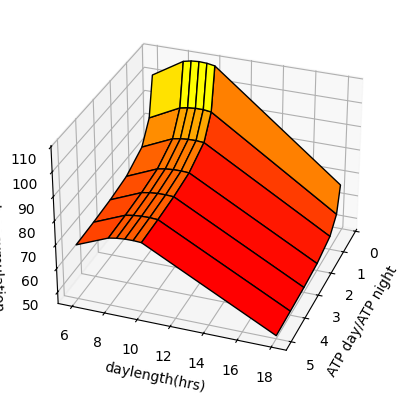

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(df3.columns.astype(float),df3.index)
z = df3.values.astype(float)



fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('ATP day/ATP night')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('starch accumulation')

#fig = plt.figure(figsize=(20, 20))
#rgb = LightSource(270, 45).shade(z, cmap=plt.cm.autumn, vert_exag=0.1, blend_mode='soft')
# surf = ax.plot_surface(x, y, z,facecolors=rgb,
#                        linewidth=0, antialiased=False, shade=False)
ax.plot_surface(x, y, z, cmap='autumn', edgecolor='black')
ax.view_init(elev=30, azim=20)
plt.show()

In [ ]:
for v in [0.25,0.3,0.5,1,2,3,4,5]:
 daynightAN(C3_dup_model,v)

[100.22921231132004, 104.96849167182444, 108.17413354699447, 109.15071550604567, 108.43230559074473, 106.23743769536014, 102.74871399888244, 98.119891799267, 92.48135728645006, 85.94439889638032, 78.11190629494523, 70.47885497274868, 62.24646736254671]
[94.88247203829441, 99.73634933461982, 102.43666472794129, 103.31332764937663, 102.59566274074875, 100.48260180734931, 97.15272231770537, 92.75064380731163, 87.39900259878827, 81.20247145860677, 74.10737599261529, 66.3810011103593, 58.65115430328899]
[83.71184745049425, 87.86323229431747, 90.30841749435852, 91.28504837449023, 90.84475204689481, 88.94492911605316, 85.9607389549048, 82.01214782329485, 77.23429322280694, 71.71861658384846, 65.5436332899654, 58.41100364724455, 51.46052818425847]
[75.00092868219552, 78.75894400645588, 80.99452440386477, 81.91963631607243, 81.70846520630889, 80.25262573181607, 77.54705848292323, 73.95827583529693, 69.610761190884, 64.60572542777274, 59.01316169227017, 52.89350274620363, 46.06755859504606]
[70.

In [ ]:
accum1=[100.22921231132004, 104.96849167182444, 108.17413354699447, 109.15071550604567, 108.43230559074473, 106.23743769536014, 102.74871399888244, 98.119891799267, 92.48135728645006, 85.94439889638032, 78.11190629494523, 70.47885497274868, 62.24646736254671]
accum2=[94.88247203829441, 99.73634933461982, 102.43666472794129, 103.31332764937663, 102.59566274074875, 100.48260180734931, 97.15272231770537, 92.75064380731163, 87.39900259878827, 81.20247145860677, 74.10737599261529, 66.3810011103593, 58.65115430328899]
accum3=[83.71184745049425, 87.86323229431747, 90.30841749435852, 91.28504837449023, 90.84475204689481, 88.94492911605316, 85.9607389549048, 82.01214782329485, 77.23429322280694, 71.71861658384846, 65.5436332899654, 58.41100364724455, 51.46052818425847]
accum4=[75.00092868219552, 78.75894400645588, 80.99452440386477, 81.91963631607243, 81.70846520630889, 80.25262573181607, 77.54705848292323, 73.95827583529693, 69.610761190884, 64.60572542777274, 59.01316169227017, 52.89350274620363, 46.06755859504606]
accum5=[70.64546929816018, 74.20679986243351, 76.33757785860568, 77.23693028691612, 77.06849475592378, 75.90647403965828, 73.32448552879784, 69.93133984144305, 65.79899517495782, 61.04927984962376, 55.74792589325369, 49.95168622106112, 43.371073800478186]
accum6=[69.19364950344347, 72.68941848116094, 74.7852623435188, 75.67602827718179, 75.52183793911551, 74.45550656727775, 71.91696121077072, 68.58902784346006, 64.52840650310786, 59.86379799029588, 54.65951396019508, 48.97108071270284, 42.47224553559564]
accum7=[68.46773960614546, 71.93072779044739, 74.00910458592105, 74.89557727238653, 74.7485095307316, 73.69925890979647, 71.21319905181548, 67.91787184430645, 63.89311216693163, 59.27105706033722, 54.115307993665056, 48.480777958076644, 42.02283140313162]
accum8=[68.03219366767658, 71.47551337620709, 73.54340993140812, 74.42730666945944, 74.28451248565557, 73.24551031523988, 70.79094175643641, 67.51517824505298, 63.51193556553356, 58.91541250271268, 53.78878441420578, 48.186596305900764, 41.366149318682375]


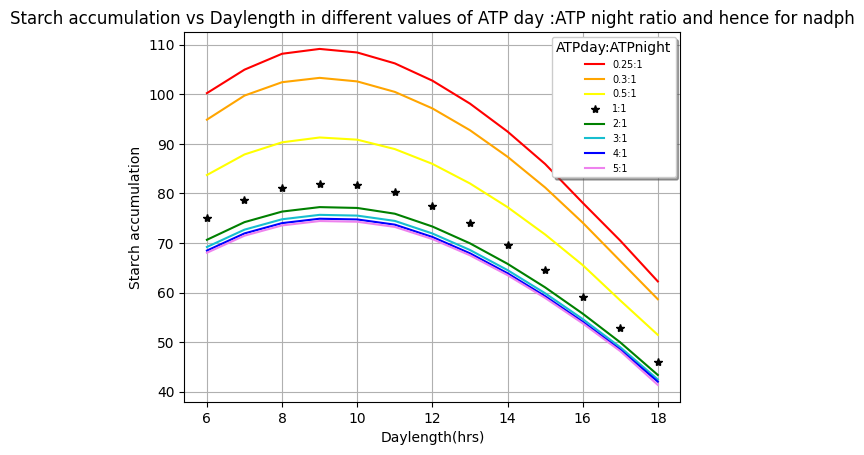

In [ ]:
#[0.25,0.3,0.5,1,2,3,4,5]:
import matplotlib.pyplot as plt


a  = [6,7,8,9,10,11,12,13,14,15,16,17,18]


# Create plots with pre-defined labels.
fig, ax = plt.subplots()
ax.plot(a, accum1, 'red', label='0.25:1')
ax.plot(a,accum2, 'orange', label='0.3:1')
ax.plot(a, accum3, 'yellow', label='0.5:1')
ax.plot(a,accum4,'k*',label='1:1')
ax.plot(a,accum5,'green',label='2:1')
ax.plot(a,accum6,'C9',label='3:1')
ax.plot(a,accum7,'blue',label='4:1')
ax.plot(a,accum8,'violet',label='5:1')


legend = ax.legend(loc='upper right', shadow=True, fontsize='x-small',title='ATPday:ATPnight')

plt.xlabel("Daylength(hrs)")
plt.ylabel("Starch accumulation")
plt.title("Starch accumulation vs Daylength in different values of ATP day :ATP night ratio and hence for nadph")
plt.grid()
plt.savefig("plot.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
[108.98879725784742, 103.14345266965925, 91.28507934765177, 81.9464463185917, 77.27712980413514, 75.7206909659995, 74.94247154696372, 74.47553989540194]
[108.43230559064257, 102.59566274076164, 90.84475204690146, 81.70846520630629, 77.06849475593155, 75.52183793909184, 74.74850953073157, 74.28451248565494]
[(108.17413354699447, 102.43666472794129, 90.30841749435852, 80.99452440386477, 76.33757785860568, 74.7852623435188, 74.00910458592105, 73.54340993140812),(108.88958163525353, 103.08650814791349, 90.96721026385607, 81.60921123483423, 76.93021172034734, 75.37054521545305, 74.59071196316125, 74.12281201161386),(109.15072864788402, 103.31334016372931, 91.28506015936324, 81.91964697472604, 77.23694038248551, 75.67603818508863, 74.89558708640794, 74.42731642708563),(108.98879725784742, 103.14345266965925, 91.28507934765177, 81.9464463185917, 77.27712980413514, 75.7206909659995, 74.94247154696372, 74.47553989540194),(108.43230559064257, 102.59566274076164, 90.84475204690146, 81.70846520630629, 77.06849475593155, 75.52183793909184, 74.74850953073157, 74.28451248565494)]

In [ ]:
# create variables to store the daylengths, starch accumulation rate and total starch accumulated

daylengthList = [6,7,8,9,10,11,12,13,14,15,16,17,18]
StarchAccumRateList = []
StarchDegRatesumList=[]
Starchacc=[]
Starchdeg=[]
# Using a for loop simulate for different daylengths
for daylength in daylengthList:
  StarchAccumRate = calculateTransitoryStarchLevels(C3_dup1_model,daylength)
  StarchAccumRateList.append(StarchAccumRate)
  Starchacc.append(str(StarchAccumRate*daylength*3600/1000))

  StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup1_model,daylength)
  StarchDegRatesumList.append(StarchDegRatesum)
  Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))

  print("Starch accumulation rate (mmol GLC/m2/s) ="+str(StarchAccumRate))
  print("Total starch accumulated over "+str(daylength)+"hr photoperiod (mmol GLC/m2) ="+str(StarchAccumRate*daylength*3600/1000))
  print("                                                                Total starch degraded over "+str(24-daylength)+"hr photoperiod (mmol GLC/m2) ="+str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))

Starch accumulation rate (mmol GLC/m2/s) =3.472265216766554
Total starch accumulated over 6hr photoperiod (mmol GLC/m2) =75.00092868215756
                                                                Total starch degraded over 18hr photoperiod (mmol GLC/m2) =75.00092868215755
Starch accumulation rate (mmol GLC/m2/s) =3.125354625753556
Total starch accumulated over 7hr photoperiod (mmol GLC/m2) =78.75893656898961
                                                                Total starch degraded over 17hr photoperiod (mmol GLC/m2) =78.75895046762795
Starch accumulation rate (mmol GLC/m2/s) =2.8123098751341935
Total starch accumulated over 8hr photoperiod (mmol GLC/m2) =80.99452440386477
                                                                Total starch degraded over 16hr photoperiod (mmol GLC/m2) =80.99452440386477
Starch accumulation rate (mmol GLC/m2/s) =2.528384165886606
Total starch accumulated over 9hr photoperiod (mmol GLC/m2) =81.91964697472604
                    

Research tells that (for Arabidopsis plant(C3))


1.decline in starch accumulation is "**independent of starch content**" but is
rather due to "**time dependent effect on starch metabolism**"

2. **simultaneous synthesis and degradation** of starch is occurring after **daylength 14 onwards**


*   This can be due to lower rate of synthesis or onset of degradation but experiments show its due to onset of degradation


*  We found the onset of starch egradtion is due to time dependent signal rather than by a high starch content
*   Maltose levels-Starch degradation
 slight increase-(9-12)
 Very large increase -after 12,daylength


*  Circadian clock plays a IMP role in onset of starch degradation
*   List item









In [ ]:
D=-1
diff=[]
for n in daylengthList:
  D=D+1
  print(D)
  print(float(Starchacc[D])-float(Starchdeg[D]))
  diff.append(float(Starchacc[D])-float(Starchdeg[D]))



0
-1.4210854715202004e-14
1
1.4210854715202004e-14
2
0.0
3
1.4210854715202004e-14
4
1.4210854715202004e-14
5
-1.4210854715202004e-14
6
-1.4210854715202004e-14
7
0.0
8
0.0
9
-1.4210854715202004e-14
10
0.0
11
0.0
12
-7.105427357601002e-15


In [ ]:
print(diff)

[-1.4210854715202004e-14, 1.4210854715202004e-14, 0.0, 1.4210854715202004e-14, 1.4210854715202004e-14, -1.4210854715202004e-14, -1.4210854715202004e-14, 0.0, 0.0, -1.4210854715202004e-14, 0.0, 0.0, -7.105427357601002e-15]


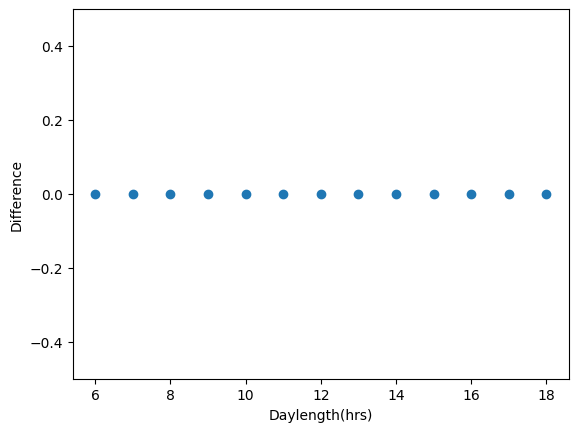

In [ ]:
import matplotlib.pyplot as plt
x=daylengthList
y=diff
plt.xlabel("Daylength(hrs)")
plt.ylabel("Difference")
plt.ylim(-0.5,0.5)
plt.scatter(x, y)
plt.show()

In [ ]:
R=-1
ratediff=[]
for n in daylengthList:
  R=R+1
  print(R)
  print(float(StarchAccumRateList[R])-float(StarchDegRatesumList[R]))
  ratediff.append(float(StarchAccumRateList[R])-float(StarchDegRatesumList[R]))

0
2.3148434778453133
1
1.8384440711096133
2
1.4061549375670606
3
1.0113535347661902
4
0.6484798825909062
5
0.31178176274998237
6
-2.220446049250313e-16
7
-0.28732818894829526
8
-0.5524663586581626
9
-0.7976015484930064
10
-1.0245340571571606
11
-1.2346756009836182
12
-1.4218382282426334


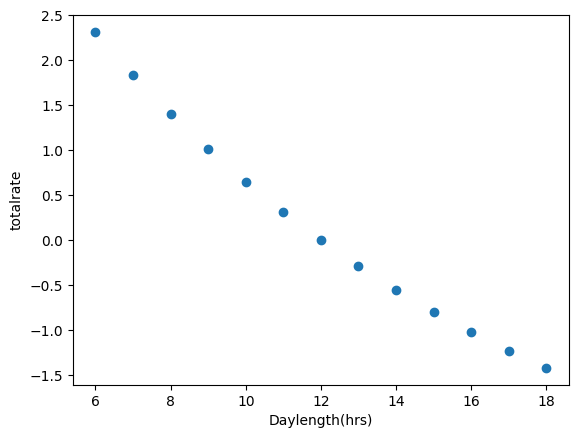

In [ ]:
import matplotlib.pyplot as plt
x=daylengthList
y=ratediff
plt.xlabel("Daylength(hrs)")
plt.ylabel("totalrate")

plt.scatter(x, y)
plt.show()

How starch degradation is initiated at different daylengths

Back tracing the degradation reaction

Constraining the linker reactions

In [ ]:
from cobra.io import write_sbml_model
C3_dup2_model=write_sbml_model(C3_dup_model,'C3_DL_model')

In [ ]:
l=[]
for rxn in C3_dup1_model.reactions.query('_dielTransfer'):
  print(rxn.id,"\t",rxn,"\t",rxn.flux)
  l.append(rxn.id)

GLY_v_dielTransfer 	 GLY_v_dielTransfer: GLY_v_Light --> GLY_v_Dark 	 0.0
ILE_v_dielTransfer 	 ILE_v_dielTransfer: ILE_v_Light --> ILE_v_Dark 	 0.0
ARG_v_dielTransfer 	 ARG_v_dielTransfer: ARG_v_Light --> ARG_v_Dark 	 0.0
THR_v_dielTransfer 	 THR_v_dielTransfer: THR_v_Light --> THR_v_Dark 	 0.0
NITRATE_v_dielTransferReverse 	 NITRATE_v_dielTransferReverse: NITRATE_v_Light <=> NITRATE_v_Dark 	 -0.10907111920474816
GLN_v_dielTransfer 	 GLN_v_dielTransfer: GLN_v_Light --> GLN_v_Dark 	 0.0
L_ALPHA_ALANINE_v_dielTransfer 	 L_ALPHA_ALANINE_v_dielTransfer: L_ALPHA_ALANINE_v_Light --> L_ALPHA_ALANINE_v_Dark 	 0.0
TYR_v_dielTransfer 	 TYR_v_dielTransfer: TYR_v_Light --> TYR_v_Dark 	 0.0
MET_v_dielTransfer 	 MET_v_dielTransfer: MET_v_Light --> MET_v_Dark 	 0.00034657269243775347
GLT_v_dielTransfer 	 GLT_v_dielTransfer: GLT_v_Light --> GLT_v_Dark 	 0.0
VAL_v_dielTransfer 	 VAL_v_dielTransfer: VAL_v_Light --> VAL_v_Dark 	 0.0
TRP_v_dielTransfer 	 TRP_v_dielTransfer: TRP_v_Light --> TRP_v_Dark 	 0.

All diel transfer reaction switched off- infeasible

In [ ]:
C3_dup2_model=C3_dup1_model.copy()

In [ ]:
print(l)
print(len(l))

['GLY_v_dielTransfer', 'ILE_v_dielTransfer', 'ARG_v_dielTransfer', 'THR_v_dielTransfer', 'NITRATE_v_dielTransferReverse', 'GLN_v_dielTransfer', 'L_ALPHA_ALANINE_v_dielTransfer', 'TYR_v_dielTransfer', 'MET_v_dielTransfer', 'GLT_v_dielTransfer', 'VAL_v_dielTransfer', 'TRP_v_dielTransfer', '4_AMINO_BUTYRATE_v_dielTransfer', 'SER_v_dielTransfer', 'PHE_v_dielTransfer', 'CYS_v_dielTransfer', 'PROTON_v_dielTransferReverse', 'LEU_v_dielTransfer', 'L_ASPARTATE_v_dielTransfer', 'LYS_v_dielTransfer', 'STARCH_p_dielTransferReverse', 'ASN_v_dielTransfer', 'SUCROSE_v_dielTransferReverse', 'PRO_v_dielTransfer', 'CIT_v_dielTransferReverse', 'HIS_v_dielTransfer', 'MAL_v_dielTransferReverse']
27


In [ ]:
print(l[0])

GLY_v_dielTransfer


In [ ]:
#for n in range(27):
C3_dup3_model=C3_dup1_model.copy()
for rxn in C3_dup3_model.reactions.query('_dielTransfer'):
    if rxn.id==l[20]:
      continue
    else:
      rxn.bounds=(0,0)
pfba(C3_dup3_model)


,fluxes,reduced_costs
PRO_PROTON_vc_Light,0.000000,0.666667
Ca_tx_Light,0.000000,0.000000
H2O_xc_Light,13.905454,-2.000000
sCIT_biomass_Light,0.000000,2.000000
ACETYLGLUTKIN_RXN_p_Light,0.001024,-2.000000
...,...,...
SUCROSE_v_dielTransferReverse,0.000000,-134.459066
PRO_v_dielTransfer,0.000000,843.899330
CIT_v_dielTransferReverse,0.000000,131.672962
HIS_v_dielTransfer,0.000000,2696.714063


In [ ]:
for rxn in C3_dup3_model.reactions.query('_dielTransfer'):
  print(rxn.id,"\t",rxn,"\t",rxn.flux)


GLY_v_dielTransfer 	 GLY_v_dielTransfer: GLY_v_Light --> GLY_v_Dark 	 0.0
ILE_v_dielTransfer 	 ILE_v_dielTransfer: ILE_v_Light --> ILE_v_Dark 	 0.0
ARG_v_dielTransfer 	 ARG_v_dielTransfer: ARG_v_Light --> ARG_v_Dark 	 0.0
THR_v_dielTransfer 	 THR_v_dielTransfer: THR_v_Light --> THR_v_Dark 	 0.0
NITRATE_v_dielTransferReverse 	 NITRATE_v_dielTransferReverse: NITRATE_v_Light --> NITRATE_v_Dark 	 0.0
GLN_v_dielTransfer 	 GLN_v_dielTransfer: GLN_v_Light --> GLN_v_Dark 	 0.0
L_ALPHA_ALANINE_v_dielTransfer 	 L_ALPHA_ALANINE_v_dielTransfer: L_ALPHA_ALANINE_v_Light --> L_ALPHA_ALANINE_v_Dark 	 0.0
TYR_v_dielTransfer 	 TYR_v_dielTransfer: TYR_v_Light --> TYR_v_Dark 	 0.0
MET_v_dielTransfer 	 MET_v_dielTransfer: MET_v_Light --> MET_v_Dark 	 0.0
GLT_v_dielTransfer 	 GLT_v_dielTransfer: GLT_v_Light --> GLT_v_Dark 	 0.0
VAL_v_dielTransfer 	 VAL_v_dielTransfer: VAL_v_Light --> VAL_v_Dark 	 0.0
TRP_v_dielTransfer 	 TRP_v_dielTransfer: TRP_v_Light --> TRP_v_Dark 	 0.0
4_AMINO_BUTYRATE_v_dielTransfer 	 

In [ ]:
daylengthList=[6,7,8,9,10,11,12,13,14,15,16,17,18]

In [ ]:
StarchAccumRateList = []
#StarchDegRatesumList=[]
Starchacc=[]
#Starchdeg=[]
# Using a for loop simulate for different daylengths
for daylength in daylengthList:
  StarchAccumRate = calculateTransitoryStarchLevels(C3_dup3_model,daylength)
  StarchAccumRateList.append(StarchAccumRate)
  Starchacc.append(str(StarchAccumRate*daylength*3600/1000))

  #StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup3_model,daylength)
  #StarchDegRatesumList.append(StarchDegRatesum)
  #Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))
#print(StarchAccumRateList )
#print(StarchDegRatesumList)
print(Starchacc)
#print(Starchdeg)

['75.25894449127372', '78.89249191391171', '80.92465244842522', '81.56830126238864', '81.00018395325918', '79.36826953037003', '76.79737788297035', '73.39353636428332', '69.24738819175946', '64.43688499665052', '59.02943299529718', '53.08361790159613', '46.65060199213272']


In [ ]:
I=-1
starchaccNew2=[]
for n in daylengthList:
 I=I+1
 #print(I)
 starchaccNew2.append(float(Starchacc[I]))
 #print(float(Starchacc[I]))

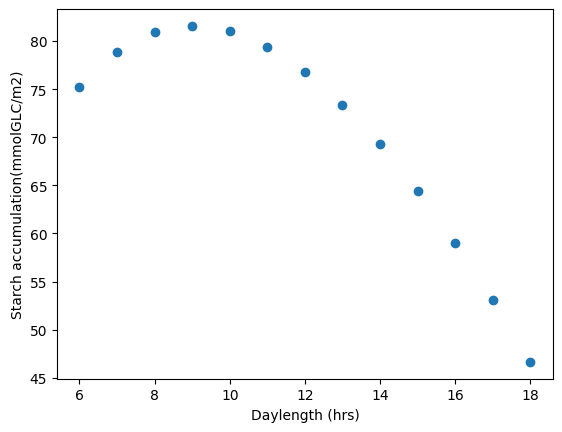

In [ ]:
import matplotlib.pyplot as plt

x = daylengthList #DAYLENGTH lIST
y = starchaccNew2#Starch accumulation
plt.xlabel("Daylength (hrs)")
plt.ylabel("Starch accumulation(mmolGLC/m2)")


plt.scatter(x, y)
plt.show()

In [ ]:
l[20]

'STARCH_p_dielTransferReverse'

Constraining all linker reaction flux 0 other than starch accumulation -pfba-still the maximum starch accumulation obseved for daylength 9 hr

In [ ]:
daylengthList=[6,7,8,9,10,11,12,13,14,15,16,17,18]

In [ ]:
!pip install cobra --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.8/141.8 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 92.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 84.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.2/788.2 kB 37.9 MB/s eta 0:00:00


In [ ]:
from cobra.io import read_sbml_model
C3_dup_model=read_sbml_model('C3_DL_model')

In [ ]:
C3_dup1_model=C3_dup_model.copy()

In [ ]:
from cobra.flux_analysis import pfba
pfba(C3_dup1_model)

,fluxes,reduced_costs
PRO_PROTON_vc_Light,0.000000,-0.666667
Ca_tx_Light,0.000000,0.000000
H2O_xc_Light,14.111768,-2.000000
sCIT_biomass_Light,0.000000,2.000000
ACETYLGLUTKIN_RXN_p_Light,0.001040,-2.000000
...,...,...
SUCROSE_v_dielTransferReverse,0.000000,-1046.802899
PRO_v_dielTransfer,0.000000,1220.334922
CIT_v_dielTransferReverse,-0.099850,2.000000
HIS_v_dielTransfer,0.000000,9184.460919


In [ ]:
l=[]
for rxn in C3_dup1_model.reactions.query('_dielTransfer'):
  print(rxn.id,"\t",rxn,"\t",rxn.flux)
  l.append(rxn.id)

GLY_v_dielTransfer 	 GLY_v_dielTransfer: GLY_v_Light --> GLY_v_Dark 	 0.0
ILE_v_dielTransfer 	 ILE_v_dielTransfer: ILE_v_Light --> ILE_v_Dark 	 6.209094223344533e-13
ARG_v_dielTransfer 	 ARG_v_dielTransfer: ARG_v_Light --> ARG_v_Dark 	 0.0
THR_v_dielTransfer 	 THR_v_dielTransfer: THR_v_Light --> THR_v_Dark 	 0.0
NITRATE_v_dielTransferReverse 	 NITRATE_v_dielTransferReverse: NITRATE_v_Light <=> NITRATE_v_Dark 	 -0.10907111920497407
GLN_v_dielTransfer 	 GLN_v_dielTransfer: GLN_v_Light --> GLN_v_Dark 	 0.0
L_ALPHA_ALANINE_v_dielTransfer 	 L_ALPHA_ALANINE_v_dielTransfer: L_ALPHA_ALANINE_v_Light --> L_ALPHA_ALANINE_v_Dark 	 0.0
TYR_v_dielTransfer 	 TYR_v_dielTransfer: TYR_v_Light --> TYR_v_Dark 	 0.0
MET_v_dielTransfer 	 MET_v_dielTransfer: MET_v_Light --> MET_v_Dark 	 0.00034657269243775586
GLT_v_dielTransfer 	 GLT_v_dielTransfer: GLT_v_Light --> GLT_v_Dark 	 0.0
VAL_v_dielTransfer 	 VAL_v_dielTransfer: VAL_v_Light --> VAL_v_Dark 	 0.0
TRP_v_dielTransfer 	 TRP_v_dielTransfer: TRP_v_Light -

In [ ]:
def linker2o(Org_model,n,dL):
  for i in range(27):


      C3_dup3_model=Org_model.copy()
      for rxn in C3_dup3_model.reactions.query('_dielTransfer'):
          if rxn.id==l[n] :
            continue
          if rxn.id==l[i] :
            continue


          else:
            rxn.bounds=(0,0)
      pfba(C3_dup3_model)

      print(n,i)
      StarchAccumRateList = []
      StarchDegRatesumList=[]
      Starchacc=[]
      Starchdeg=[]
  # Using a for loop simulate for different daylengths
      for daylength in dL:
        StarchAccumRate = calculateTransitoryStarchLevels(C3_dup3_model,daylength)
        StarchAccumRateList.append(StarchAccumRate)
        Starchacc.append(str(StarchAccumRate*daylength*3600/1000))

        StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup3_model,daylength)
        StarchDegRatesumList.append(StarchDegRatesum)
        Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))
      #print(StarchAccumRateList )
      #print(StarchDegRatesumList)
      #print(Starchacc)
      j=Starchacc.index(max(Starchacc))
      print(dL[j])
      if dL[j]!=9:
        print(Starchacc)
      #print(Starchdeg)

In [ ]:
linker2o(C3_dup1_model,20,[6,7,8,9,10,11,12,13,14,15,16,17,18])

20 0
['75.25894449127398', '78.89249191391086', '80.92465244842518', '81.56830126238992', '81.00018395325793', '79.36826953036959', '76.79737788297084', '73.39353636428386', '69.24738819175896', '64.43688499665046', '59.02943299529755', '53.0836179015962', '46.65060199213195']
20 1
['75.25894449127401', '78.89249191391056', '80.92465244842418', '81.5683012623897', '81.00018395325846', '79.3682695303706', '76.79737788297021', '73.39353636428358', '69.24738819175936', '64.43688499664957', '59.02943299529751', '53.08361790159591', '46.65060199213171']
20 2
['75.25894449127388', '78.89249191391042', '80.92465244842502', '81.56830126239207', '81.00018395325753', '79.36826953037027', '76.79737788297032', '73.39353636428389', '69.24738819175955', '64.43688499665035', '59.02943299529747', '53.08361790159624', '46.650601992132074']
20 3
['75.25894449127506', '78.89249191391065', '80.92465244842559', '81.5683012623894', '81.0001839532577', '79.36826953036868', '76.79737788297179', '73.3935363642

In [ ]:
linker2o(C3_dup1_model,24,[6,7,8,9,10,11,12,13,14,15,16,17,18])

24 0
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
6
24 1
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
6
24 2
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
6
24 3
['6.513295798099341e-30', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
6
24 4
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
6
24 5
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
6
24 6
['-2.964310972154161e-16', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
7
24 7
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '-1.9447685709581178e-14', '0.0', '0.0', '0.0', '0.0', '-1.0849269793382015e-14', '0.0']
6
24 8
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
6
24 9
['0.0', '0.0', '0.0', '0.0'

In [ ]:
linker2o(C3_dup1_model,26,[6,7,8,9,10,11,12,13,14,15,16,17,18])

26 0
6
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
26 1
6
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
26 2
13
['5.713003160063162e-14', '0.0', '-5.9578459179273665e-16', '0.0', '0.0', '1.70330011418344e-15', '0.0', '9.66105205913477e-16', '-9.578672855185411e-15', '0.0', '-2.888461725219168e-15', '0.0', '0.0']
26 3
6
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
26 4
6
['8.01464158430112e-14', '-1.6383223337603234e-13', '6.358133850900224e-30', '1.3268477665497175e-29', '0.0', '4.096578072002671e-15', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
26 5
12
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '5.60093348435938e-14', '0.0', '0.0', '0.0', '0.0', '-5.185950961236603e-13', '0.0']
26 6
6
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0']
26 7
6
['0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.0', '0.

In [ ]:
linker2o(C3_dup1_model,0,[6,7,8,9,10,11,12,13,14,15,16,17,18])

Infeasible: None (infeasible).

Since it's coming infeasible if run loop for linker2o, we have to run it individually

In [ ]:
C3_dup3_model=C3_dup1_model.copy()
for rxn in C3_dup3_model.reactions.query('_dielTransfer'):
    if rxn.id==l[0] :
      continue
    if rxn.id==l[25] :
      continue


    else:
      rxn.bounds=(0,0)
pfba(C3_dup3_model)

#print(n,i)
StarchAccumRateList = []
StarchDegRatesumList=[]
Starchacc=[]
Starchdeg=[]
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]
# Using a for loop simulate for different daylengths
for daylength in dL:
  StarchAccumRate = calculateTransitoryStarchLevels(C3_dup3_model,daylength)
  StarchAccumRateList.append(StarchAccumRate)
  Starchacc.append(str(StarchAccumRate*daylength*3600/1000))

  StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup3_model,daylength)
  StarchDegRatesumList.append(StarchDegRatesum)
  Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))
#print(StarchAccumRateList )
#print(StarchDegRatesumList)
#print(Starchacc)
j=Starchacc.index(max(Starchacc))
print(dL[j])
if dL[j]!=9:
  print(Starchacc)


Infeasible: None (infeasible).

Claim : Whenver all reactions in l, for  n=20 and n=24 and n=26 is constrined.Then pfba become infeasible

In [ ]:
C3_dup3_model=C3_dup1_model.copy()
for rxn in C3_dup3_model.reactions.query('_dielTransfer'):

  if rxn.id==l[24]:
    rxn.bounds=(0,0)
  if rxn.id==l[26]:
    rxn.bounds=(0,0)

  else:
    continue
pfba(C3_dup3_model)

,fluxes,reduced_costs
PRO_PROTON_vc_Light,0.000000,-0.666667
Ca_tx_Light,0.000000,0.000000
H2O_xc_Light,13.905306,-2.000000
sCIT_biomass_Light,0.000000,2.000000
ACETYLGLUTKIN_RXN_p_Light,0.001038,-2.000000
...,...,...
SUCROSE_v_dielTransferReverse,0.000000,-1048.248977
PRO_v_dielTransfer,0.000000,2374.549449
CIT_v_dielTransferReverse,0.000000,1159.047132
HIS_v_dielTransfer,0.000000,9239.326752


In [ ]:
for rxn in C3_dup3_model.reactions.query('_dielTransfer'):
  print(rxn.id,"\t",rxn.flux)

GLY_v_dielTransfer 	 0.0
ILE_v_dielTransfer 	 1.2776412621348346e-12
ARG_v_dielTransfer 	 0.0
THR_v_dielTransfer 	 0.0
NITRATE_v_dielTransferReverse 	 -0.10893640498286383
GLN_v_dielTransfer 	 0.0
L_ALPHA_ALANINE_v_dielTransfer 	 0.0
TYR_v_dielTransfer 	 0.0
MET_v_dielTransfer 	 0.0003461446389704498
GLT_v_dielTransfer 	 0.0
VAL_v_dielTransfer 	 0.0
TRP_v_dielTransfer 	 0.0
4_AMINO_BUTYRATE_v_dielTransfer 	 0.0
SER_v_dielTransfer 	 0.0
PHE_v_dielTransfer 	 0.0
CYS_v_dielTransfer 	 0.00034614463897044985
PROTON_v_dielTransferReverse 	 -0.00813650478027138
LEU_v_dielTransfer 	 0.0
L_ASPARTATE_v_dielTransfer 	 0.0
LYS_v_dielTransfer 	 0.0
STARCH_p_dielTransferReverse 	 1.718976727617892
ASN_v_dielTransfer 	 0.0
SUCROSE_v_dielTransferReverse 	 0.0
PRO_v_dielTransfer 	 0.0
CIT_v_dielTransferReverse 	 0.0
HIS_v_dielTransfer 	 0.0
MAL_v_dielTransferReverse 	 0.0


In [ ]:
StarchAccumRateList = []
StarchDegRatesumList=[]
Starchacc=[]
Starchdeg=[]
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]
# Using a for loop simulate for different daylengths
for daylength in dL:
  StarchAccumRate = calculateTransitoryStarchLevels(C3_dup3_model,daylength)
  StarchAccumRateList.append(StarchAccumRate)
  Starchacc.append(str(StarchAccumRate*daylength*3600/1000))

  StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup3_model,daylength)
  StarchDegRatesumList.append(StarchDegRatesum)
  Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))
#print(StarchAccumRateList )
#print(StarchDegRatesumList)
#print(Starchacc)
j=Starchacc.index(max(Starchacc))
print(dL[j])
if dL[j]!=9:
  print(Starchacc)

9


Observation: when contrained rxn 20 in list l ,ie starch diel transfer reverse then starch accumulation obtained is always negligible values for all daylength

case1 printing starch acc for only when max starch acc is not in daylength 9

In [ ]:
def linker3o20(org_model,n,dL):
  for j in range(27):
    print("Section ",j)
    for i in range(27):
      C3_dup3_model=org_model.copy()
      for rxn in C3_dup3_model.reactions.query('diel_Transfer'):
          if rxn.id==l[20]:
            continue
          if rxn.id==l[j]:
            continue
          if rxn.id==l[n]:
            continue
          if rxn.id==l[i]:
            continue

          else:
            rxn.bounds=(0,0)
      pfba(C3_dup3_model)
      print("Constraining all reactions except 20",n,i,j)
      StarchAccumRateList = []
      StarchDegRatesumList=[]
      Starchacc=[]
      Starchdeg=[]
  # Using a for loop simulate for different daylengths
      for daylength in dL:
        StarchAccumRate = calculateTransitoryStarchLevels(C3_dup3_model,daylength)
        StarchAccumRateList.append(StarchAccumRate)
        Starchacc.append(str(StarchAccumRate*daylength*3600/1000))

        StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup3_model,daylength)
        StarchDegRatesumList.append(StarchDegRatesum)
        Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))
      #print(StarchAccumRateList )
      #print(StarchDegRatesumList)
      #print(Starchacc)
      k=Starchacc.index(max(Starchacc))
      print(dL[k])
      if dL[k]!=9:
        print(Starchacc)
      #print(Starchdeg)





In [ ]:
linker3o20(C3_dup1_model,1,[6,7,8,9,10,11,12,13,14,15,16,17,18])

Section  0
Constraining all reactions except 20 1 0 0
9
Constraining all reactions except 20 1 1 0
9
Constraining all reactions except 20 1 2 0
9
Constraining all reactions except 20 1 3 0
9
Constraining all reactions except 20 1 4 0
9
Constraining all reactions except 20 1 5 0
9
Constraining all reactions except 20 1 6 0
9
Constraining all reactions except 20 1 7 0
9
Constraining all reactions except 20 1 8 0
9
Constraining all reactions except 20 1 9 0
9
Constraining all reactions except 20 1 10 0
9
Constraining all reactions except 20 1 11 0
9
Constraining all reactions except 20 1 12 0
9
Constraining all reactions except 20 1 13 0
9
Constraining all reactions except 20 1 14 0
9
Constraining all reactions except 20 1 15 0
9
Constraining all reactions except 20 1 16 0
9
Constraining all reactions except 20 1 17 0
9
Constraining all reactions except 20 1 18 0
9
Constraining all reactions except 20 1 19 0
9
Constraining all reactions except 20 1 20 0
9
Constraining all reactions except

In [ ]:
for m in range(27):
  linker3o20(C3_dup1_model,m,[6,7,8,9,10,11,12,13,14,15,16,17,18])

In [ ]:
l=[]
for rxn in C3_dup1_model.reactions.query('_dielTransfer'):
  print(rxn.id,"\t",rxn,"\t",rxn.flux)
  l.append(rxn.id)

GLY_v_dielTransfer 	 GLY_v_dielTransfer: GLY_v_Light --> GLY_v_Dark 	 0.0
ILE_v_dielTransfer 	 ILE_v_dielTransfer: ILE_v_Light --> ILE_v_Dark 	 0.0
ARG_v_dielTransfer 	 ARG_v_dielTransfer: ARG_v_Light --> ARG_v_Dark 	 0.0
THR_v_dielTransfer 	 THR_v_dielTransfer: THR_v_Light --> THR_v_Dark 	 0.0
NITRATE_v_dielTransferReverse 	 NITRATE_v_dielTransferReverse: NITRATE_v_Light <=> NITRATE_v_Dark 	 -0.10907111920474816
GLN_v_dielTransfer 	 GLN_v_dielTransfer: GLN_v_Light --> GLN_v_Dark 	 0.0
L_ALPHA_ALANINE_v_dielTransfer 	 L_ALPHA_ALANINE_v_dielTransfer: L_ALPHA_ALANINE_v_Light --> L_ALPHA_ALANINE_v_Dark 	 0.0
TYR_v_dielTransfer 	 TYR_v_dielTransfer: TYR_v_Light --> TYR_v_Dark 	 0.0
MET_v_dielTransfer 	 MET_v_dielTransfer: MET_v_Light --> MET_v_Dark 	 0.00034657269243775347
GLT_v_dielTransfer 	 GLT_v_dielTransfer: GLT_v_Light --> GLT_v_Dark 	 0.0
VAL_v_dielTransfer 	 VAL_v_dielTransfer: VAL_v_Light --> VAL_v_Dark 	 0.0
TRP_v_dielTransfer 	 TRP_v_dielTransfer: TRP_v_Light --> TRP_v_Dark 	 0.

In [ ]:
def linker25o20(org_model,(n,n1,n2,n3,n4,n5,n6,n7,n8,n9,n10,n11,n12,n13,n14,n15,n16,n17,n18,n19,n20,n21,n22,n23,n24,n25),dL):
  C3_dup3_model=org_model.copy()
  for rxn in C3_dup3_model.reactions.query('diel_Transfer'):
    if rxn.id==l[20]:
     continue
    if rxn.id==l[n]:
     rxn.bounds=(0,0)
    if rxn.id==l[n1]:
     rxn.bounds=(0,0)
    if rxn.id==l[n2]:
     rxn.bounds=(0,0)
    if rxn.id==l[n3]:
     rxn.bounds=(0,0)
    if rxn.id==l[n4]:
     rxn.bounds=(0,0)
    if rxn.id==l[n5]:
     rxn.bounds=(0,0)
    if rxn.id==l[n6]:
     rxn.bounds=(0,0)
    if rxn.id==l[n7]:
     rxn.bounds=(0,0)
    if rxn.id==l[n8]:
     rxn.bounds=(0,0)
    if rxn.id==l[n9]:
     rxn.bounds=(0,0)
    if rxn.id==l[n10]:
     rxn.bounds=(0,0)
    if rxn.id==l[n11]:
     rxn.bounds=(0,0)
    if rxn.id==l[n12]:
     rxn.bounds=(0,0)
    if rxn.id==l[n13]:
     rxn.bounds=(0,0)
    if rxn.id==l[n14]:
     rxn.bounds=(0,0)
    if rxn.id==l[n15]:
     rxn.bounds=(0,0)
    if rxn.id==l[n16]:
     rxn.bounds=(0,0)
    if rxn.id==l[n17]:
     rxn.bounds=(0,0)
    if rxn.id==l[n18]:
     rxn.bounds=(0,0)
    if rxn.id==l[n19]:
     rxn.bounds=(0,0)
    if rxn.id==l[n20]:
     rxn.bounds=(0,0)
    if rxn.id==l[n21]:
     rxn.bounds=(0,0)
    if rxn.id==l[n22]:
     rxn.bounds=(0,0)
    if rxn.id==l[n23]:
     rxn.bounds=(0,0)
    if rxn.id==l[n24]:
     rxn.bounds=(0,0)
    if rxn.id==l[n25]:
     rxn.bounds=(0,0)

    else:
      continue
  pfba(C3_dup3_model)
  print("Constraining  reactions except 20",n,n1,n2,n3,n4,n5,n6,n7,n8,n9,n10,n11,n12,n13,n14,n15,n16,n17,n18,n19,n20,n21,n22,n23,n24,n25)
  StarchAccumRateList = []
  #StarchDegRatesumList=[]
  Starchacc=[]
  #Starchdeg=[]
  # Using a for loop simulate for different daylengths
  for daylength in dL:
    StarchAccumRate = calculateTransitoryStarchLevels(C3_dup3_model,daylength)
    StarchAccumRateList.append(StarchAccumRate)
    Starchacc.append(str(StarchAccumRate*daylength*3600/1000))

    #StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup3_model,daylength)
    #StarchDegRatesumList.append(StarchDegRatesum)
    #Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))
  #print(StarchAccumRateList )
  #print(StarchDegRatesumList)
  #print(Starchacc)
  k=Starchacc.index(max(Starchacc))
  print(dL[k])
  if dL[k]!=9:
   print(Starchacc)
  #print(Starchdeg)


Due to for loop nesting limit,20 nests

constraining reactions except 1 to 20 many reactions out of 27.
That is constraining27 reactions to 8 reactions out of reaction.
Remaining case constraining upto 7 reactions at a time


In [ ]:
for n in range(27):
  for n1 in range(27):
    for n2 in range(27):
      for n3 in range(27):
        for n4 in range(27):
          for n5 in range(27):
            for n6 in range(27):
              for n7 in range(27):
                for n8 in range(27):
                  for n9 in range(27):
                    for n10 in range(27):
                      for n11 in range(27):
                        for n12 in range(27):
                          for n13 in range(27):
                            for n14 in range(27):
                              for n15 in range(27):
                                for n16 in range(27):
                                  for n17 in range(27):
                                    for n18 in range(27):
                                      for n19 in range(27):
                                        for n20 in range(27):

                                            linker25o20(C3_dup1_model,n,n1,n2,n3,n4,n5,n6,n7,n8,n9,n10,n11,n12,n13,n14,n15,n16,n17,n18,n19,n20,2,2,2,2,2,[6,7,8,9,10,11,12,13,14,15,16,17,18])

Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 3 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 5 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 6 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 7 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 8 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 9 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 10 2 2 2 2 2


KeyboardInterrupt: 

In [ ]:
for n in range(27):
  for n1 in range(27):
    for n2 in range(27):
     for n3 in range(27):
      for n4 in range(27):
          linker25o20(C3_dup1_model,n,n1,n2,n3,n4,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,[6,7,8,9,10,11,12,13,14,15,16,17,18])

Constraining all reactions except 20 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 4 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 5 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 6 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 7 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 8 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 9 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
9
Constraining all reactions except 20 0 0 0 0 10 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2


In [ ]:
def linker3o20(org_model,l3,m,dL):
  C3_dup3_model=org_model.copy()
  for rxn in C3_dup3_model.reactions.query('diel_Transfer'):
    if rxn.id==l[20]:
     continue
    if rxn.id==l[l3[m][0]]:
     rxn.bounds=(0,0)
    if rxn.id==l[l3[m][1]]:
     rxn.bounds=(0,0)
    if rxn.id==l[l3[m][2]]:
     rxn.bounds=(0,0)
    # if rxn.id==l[n3]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n4]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n5]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n6]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n7]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n8]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n9]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n10]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n11]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n12]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n13]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n14]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n15]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n16]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n17]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n18]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n19]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n20]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n21]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n22]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n23]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n24]:
    #  rxn.bounds=(0,0)
    # if rxn.id==l[n25]:
    #  rxn.bounds=(0,0)

    else:
      continue
  pfba(C3_dup3_model)
  print("Constraining  reactions " ,l3[m][0],l3[m][1],l3[m][2])
  StarchAccumRateList = []
  #StarchDegRatesumList=[]
  Starchacc=[]
  #Starchdeg=[]
  # Using a for loop simulate for different daylengths
  for daylength in dL:
    StarchAccumRate = calculateTransitoryStarchLevels(C3_dup3_model,daylength)
    StarchAccumRateList.append(StarchAccumRate)
    Starchacc.append(str(StarchAccumRate*daylength*3600/1000))

    #StarchDegRatesum= calculateTransitoryDegStarchLevels(C3_dup3_model,daylength)
    #StarchDegRatesumList.append(StarchDegRatesum)
    #Starchdeg.append(str(abs(StarchDegRatesum)*(24-daylength)*3600/1000))
  #print(StarchAccumRateList )
  #print(StarchDegRatesumList)
  #print(Starchacc)
  k=Starchacc.index(max(Starchacc))
  print(dL[k])
  if dL[k]!=9:
   print(Starchacc)
  #print(Starchdeg)


In [ ]:
from itertools import combinations
l3=list(combinations([0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,21,22,23,24,25,26],3))#without 20

In [ ]:
print(len(l3))

2600


In [ ]:
for i in range(len(l3)):
  linker3o20(C3_dup1_model,l3,i,[6,7,8,9,10,11,12,13,14,15,16,17,18])

Constraining  reactions  0 1 2
9
Constraining  reactions  0 1 3
9
Constraining  reactions  0 1 4
9
Constraining  reactions  0 1 5
9
Constraining  reactions  0 1 6
9
Constraining  reactions  0 1 7
9
Constraining  reactions  0 1 8
9
Constraining  reactions  0 1 9
9
Constraining  reactions  0 1 10
9
Constraining  reactions  0 1 11
9
Constraining  reactions  0 1 12
9
Constraining  reactions  0 1 13
9
Constraining  reactions  0 1 14
9
Constraining  reactions  0 1 15
9
Constraining  reactions  0 1 16
9
Constraining  reactions  0 1 17
9
Constraining  reactions  0 1 18
9
Constraining  reactions  0 1 19
9
Constraining  reactions  0 1 21
9
Constraining  reactions  0 1 22
9
Constraining  reactions  0 1 23
9
Constraining  reactions  0 1 24
9
Constraining  reactions  0 1 25
9
Constraining  reactions  0 1 26
9
Constraining  reactions  0 2 3
9
Constraining  reactions  0 2 4
9
Constraining  reactions  0 2 5
9
Constraining  reactions  0 2 6
9
Constraining  reactions  0 2 7
9
Constraining  reactions  0 

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipython-input-406499984.py", line 2, in <cell line: 0>
    linker3o20(C3_dup1_model,l3,i,[6,7,8,9,10,11,12,13,14,15,16,17,18])
  File "/tmp/ipython-input-797714283.py", line 69, in linker3o20
    StarchAccumRate = calculateTransitoryStarchLevels(C3_dup3_model,daylength)
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipython-input-3976583541.py", line 2, in calculateTransitoryStarchLevels
    new_model = Orig_model.copy()
                ^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/cobra/core/model.py", line 469, in copy
    new._solver = deepcopy(self.solver)
                  ^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/copy.py", line 151, in deepcopy
    rv = reductor(4)
         ^^^^^^^^^^^
  File "/usr/local

TypeError: object of type 'NoneType' has no len()

 Remaining case constraining upto 7 reactions at a time

Since we are getting for most of combinations of linker reactions constraints max starch acc to be at 9 or all daylength have negligible starch accumulation.And for constraining all reactions except strach linker we got maximum starch accumulation at daylength 9

Constraing the sucrose aminoacid ratio in phloem export reaction

In [ ]:
pfba(C3_dup1_model)

,fluxes,reduced_costs
PRO_PROTON_vc_Light,0.000000,-0.666667
Ca_tx_Light,0.000000,0.000000
H2O_xc_Light,14.111768,-2.000000
sCIT_biomass_Light,0.000000,2.000000
ACETYLGLUTKIN_RXN_p_Light,0.001040,-2.000000
...,...,...
SUCROSE_v_dielTransferReverse,0.000000,-1030.460418
PRO_v_dielTransfer,0.000000,1220.334922
CIT_v_dielTransferReverse,-0.099850,2.000000
HIS_v_dielTransfer,0.000000,9184.460919


In [ ]:
def calculateTransitoryStarchLevels(Orig_model,daylength):
  new_model = Orig_model.copy()

  #update stoichiometry based on daylength
  for rxn in new_model.reactions.query("_dielTransfer"):
    for met in rxn.reactants:
      stoich = rxn.metabolites[met]
      rxn.add_metabolites({met:round((-1*stoich)+(stoich*(24-daylength)/daylength),20)})

  # perform pFBA
  tempsol = pfba(new_model)

  # Starch synthesis reaction is identified
  StarchSynDay = new_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")
  # Number of moles of starch (GLC units) generated by the reaction is noted
  StarchDayStoich = new_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light").metabolites[new_model.metabolites.get_by_id("STARCH_p_Light")]
  # Starch accumulation rate
  Answer = StarchSynDay.flux*StarchDayStoich
  return(Answer)

In [ ]:
print(C3_dup1_model.reactions.Phloem_output_tx_Light.reaction)


0.0022970297 4_AMINO_BUTYRATE_c_Light + 0.0004186704 ARG_c_Light + 0.0015049505 ASN_c_Light + 0.0004186704 CYS_c_Light + 0.0792079208 FRU_c_Light + 0.0693069307 GLC_c_Light + 0.0240792079 GLN_c_Light + 0.0124356436 GLT_c_Light + 0.0007128713 GLY_c_Light + 0.0004186704 HIS_c_Light + 0.0017425743 ILE_c_Light + 0.0020594059 LEU_c_Light + 0.0022178218 LYS_c_Light + 0.0038811881 L_ALPHA_ALANINE_c_Light + 0.006019802 L_ASPARTATE_c_Light + 0.0004186704 MET_c_Light + 0.0057029703 PHE_c_Light + 0.9603960396 PROTON_e_Light + 0.0004186704 PRO_c_Light + 0.003960396 SER_c_Light + 0.0068910891 THR_c_Light + 0.0004186704 TRP_c_Light + 0.0004186704 TYR_c_Light + 0.0027722772 VAL_c_Light + 0.7326732673 sSUCROSE_b_Light --> 0.9603960396 PROTON_c_Light + phloem_transport_Light


In [ ]:
C3_dup5_model=C3_dup1_model.copy()
#constraining the phloem export reaction sucrose aminoacid ratio
Suc=C3_dup5_model.metabolites.sSUCROSE_b_Dark
Proton_e_Suc=C3_dup5_model.metabolites.PROTON_e_Dark
Proton_c_Suc=C3_dup5_model.metabolites.PROTON_c_Dark
phloemout=C3_dup5_model.reactions.Phloem_output_tx_Dark

Sucstoich=phloemout.metabolites[Suc]
phloemout.add_metabolites({Suc:2*Sucstoich})
phloemout.add_metabolites({Proton_e_Suc:2*Sucstoich})
phloemout.add_metabolites({Proton_c_Suc:-2*Sucstoich})



# Suc2=C3_dup5_model.metabolites.sSUCROSE_b_Light
# Proton_e_Suc2=C3_dup5_model.metabolites.PROTON_e_Light
# Proton_c_Suc2=C3_dup5_model.metabolites.PROTON_c_Light
# phloemout2=C3_dup5_model.reactions.Phloem_output_tx_Light

# Sucstoich2=phloemout2.metabolites[Suc2]
# phloemout2.add_metabolites({Suc2:0.3*Sucstoich2})
# phloemout2.add_metabolites({Proton_e_Suc2:0.3*Sucstoich2})
# phloemout2.add_metabolites({Proton_c_Suc2:-0.3*Sucstoich2})
pfba(C3_dup5_model)
print(phloemout)
#print(phloemout2)


Phloem_output_tx_Dark: 0.0022970297 4_AMINO_BUTYRATE_c_Dark + 0.0004186704 ARG_c_Dark + 0.0015049505 ASN_c_Dark + 0.0004186704 CYS_c_Dark + 0.0792079208 FRU_c_Dark + 0.0693069307 GLC_c_Dark + 0.0240792079 GLN_c_Dark + 0.0124356436 GLT_c_Dark + 0.0007128713 GLY_c_Dark + 0.0004186704 HIS_c_Dark + 0.0017425743 ILE_c_Dark + 0.0020594059 LEU_c_Dark + 0.0022178218 LYS_c_Dark + 0.0038811881 L_ALPHA_ALANINE_c_Dark + 0.006019802 L_ASPARTATE_c_Dark + 0.0004186704 MET_c_Dark + 0.0057029703 PHE_c_Dark + 2.4257425742 PROTON_e_Dark + 0.0004186704 PRO_c_Dark + 0.003960396 SER_c_Dark + 0.0068910891 THR_c_Dark + 0.0004186704 TRP_c_Dark + 0.0004186704 TYR_c_Dark + 0.0027722772 VAL_c_Dark + 2.1980198019 sSUCROSE_b_Dark --> 2.4257425742 PROTON_c_Dark + phloem_transport_Dark


In [ ]:
starchacc=[]
for dl in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
 starchacc.append((calculateTransitoryStarchLevels(C3_dup5_model,dl))*dl*3600/1000)
 #print(starchacc)

In [ ]:
I=-1
starchaccNew2=[]
for n in daylengthList:
 I=I+1
 #print(I)
 starchaccNew2.append(float(starchacc[I]))
 #print(float(Starchacc[I]))

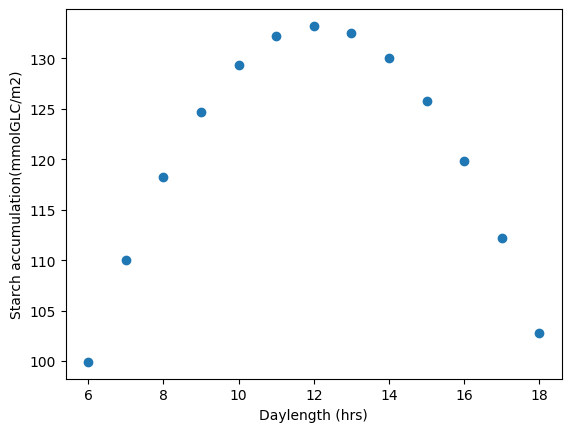

In [ ]:
import matplotlib.pyplot as plt

x = daylengthList #DAYLENGTH lIST
y = starchaccNew2#Starch accumulation
plt.xlabel("Daylength (hrs)")
plt.ylabel("Starch accumulation(mmolGLC/m2)")


plt.scatter(x, y)
plt.show()

In [ ]:
print(starchacc)

[99.91916349110896, 110.01009134151103, 118.2647043680705, 124.69699631402541, 129.3207853570931, 132.14971961153955, 133.19728220893984, 132.47679600799498, 130.0014279687768, 125.78419323117163, 119.83795892507688, 112.17544774199754, 102.80085692776922]


In [ ]:
def phloemoutNcon(org_model,r):
  C3_dup5_model=org_model.copy()
  #constraining the phloem export reaction sucrose aminoacid ratio
  Suc=C3_dup5_model.metabolites.sSUCROSE_b_Dark
  Proton_e_Suc=C3_dup5_model.metabolites.PROTON_e_Dark
  Proton_c_Suc=C3_dup5_model.metabolites.PROTON_c_Dark
  phloemout=C3_dup5_model.reactions.Phloem_output_tx_Dark

  Sucstoich=phloemout.metabolites[Suc]
  phloemout.add_metabolites({Suc:r*Sucstoich})
  phloemout.add_metabolites({Proton_e_Suc:r*Sucstoich})
  phloemout.add_metabolites({Proton_c_Suc:-r*Sucstoich})



  # Suc2=C3_dup5_model.metabolites.sSUCROSE_b_Light
  # Proton_e_Suc2=C3_dup5_model.metabolites.PROTON_e_Light
  # Proton_c_Suc2=C3_dup5_model.metabolites.PROTON_c_Light
  # phloemout2=C3_dup5_model.reactions.Phloem_output_tx_Light

  # Sucstoich2=phloemout2.metabolites[Suc2]
  # phloemout2.add_metabolites({Suc2:0.3*Sucstoich2})
  # phloemout2.add_metabolites({Proton_e_Suc2:0.3*Sucstoich2})
  # phloemout2.add_metabolites({Proton_c_Suc2:-0.3*Sucstoich2})
  pfba(C3_dup5_model)
  #print(phloemout)
  #print(phloemout2)
  starchacc=[]
  for dl in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
   starchacc.append((calculateTransitoryStarchLevels(C3_dup5_model,dl))*dl*3600/1000)
  print(starchacc)

  print(6+starchacc.index(max(starchacc)))

In [ ]:
for r in range(5):
  phloemoutNcon(C3_dup1_model,r)

[75.00092868218816, 78.75894400633584, 80.99452440386267, 81.91963631606136, 81.70846520645415, 80.25262573184554, 77.54705848304363, 73.95827583529119, 69.61076119092847, 64.60572542793348, 59.013161692252446, 52.893502746138196, 46.06755859506131]
9
[91.28433677463828, 98.82314224268245, 104.51351467156172, 108.46196097784959, 110.76688071439132, 111.51932950138266, 110.80369717670453, 108.69831164037302, 105.27597778233574, 100.60445953168114, 94.41301008873609, 86.34218176198019, 76.9904006943428]
11
[99.91916349110896, 110.01009134151103, 118.2647043680705, 124.69699631402541, 129.3207853570931, 132.14971961153955, 133.19728220893984, 132.47679600799498, 130.0014279687768, 125.78419323117163, 119.83795892507688, 112.17544774199754, 102.80085692776922]
12
[105.26946841669618, 117.14406519626937, 127.28683741035545, 135.65252103741375, 142.19425042919994, 146.8634877347867, 149.6099484770229, 150.38152302841155, 149.1241937399446, 145.78194744688514, 140.29668305251857, 132.60811387

In [ ]:
phloemoutNcon(C3_dup1_model,-0.5)

[59.5143265260157, 60.4439966129181, 60.270377153800325, 59.22058761354891, 57.4637046886832, 54.80023008731126, 51.54608159371996, 48.676712065656695, 45.48743007700754, 42.02384229957494, 38.323180833889346, 34.41614810782288, 30.32829405685685]
7


In [ ]:
y0=[59.5143265260157, 60.4439966129181, 60.270377153800325, 59.22058761354891, 57.4637046886832, 54.80023008731126, 51.54608159371996, 48.676712065656695, 45.48743007700754, 42.02384229957494, 38.323180833889346, 34.41614810782288, 30.32829405685685]
y1=[75.00092868218816, 78.75894400633584, 80.99452440386267, 81.91963631606136, 81.70846520645415, 80.25262573184554, 77.54705848304363, 73.95827583529119, 69.61076119092847, 64.60572542793348, 59.013161692252446, 52.893502746138196, 46.06755859506131]
y2=[91.28433677463828, 98.82314224268245, 104.51351467156172, 108.46196097784959, 110.76688071439132, 111.51932950138266, 110.80369717670453, 108.69831164037302, 105.27597778233574, 100.60445953168114, 94.41301008873609, 86.34218176198019, 76.9904006943428]
y3=[99.91916349110896, 110.01009134151103, 118.2647043680705, 124.69699631402541, 129.3207853570931, 132.14971961153955, 133.19728220893984, 132.47679600799498, 130.0014279687768, 125.78419323117163, 119.83795892507688, 112.17544774199754, 102.80085692776922]
y4=[105.26946841669618, 117.14406519626937, 127.28683741035545, 135.65252103741375, 142.19425042919994, 146.8634877347867, 149.6099484770229, 150.38152302841155, 149.1241937399446, 145.78194744688514, 140.29668305251857, 132.60811387285128, 122.65366439774027]
y5=[108.90983432271912, 122.0898256404233, 133.66148194247123, 143.54365102803953, 151.64963028471655, 157.886683681016, 162.15550743721957, 164.34963793023118, 164.3547943705863, 162.0481477377877, 157.29750611102662, 149.96040507736754, 139.88308994330114]
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]


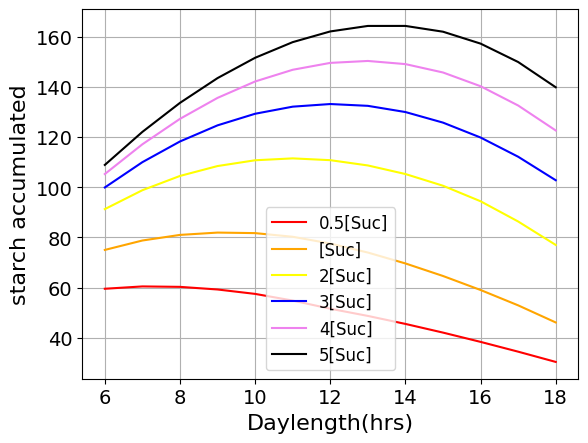

In [ ]:
import matplotlib.pyplot as plt

fig, ax=plt.subplots()
ax.plot(dL,y0,'red',label='0.5[Suc]')
ax.plot(dL,y1,'orange',label='[Suc]')
ax.plot(dL,y2,'yellow',label='2[Suc]')
ax.plot(dL,y3,'blue',label='3[Suc]')
ax.plot(dL,y4,'violet',label='4[Suc]')
ax.plot(dL,y5,'black',label='5[Suc]')


legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel("Daylength(hrs)", fontsize=16)
plt.ylabel("starch accumulated", fontsize=16)
#night only
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(fontsize=12)

plt.grid()
plt.savefig("plot.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
def phloemoutDcon(org_model,r):
  C3_dup5_model=org_model.copy()
  #constraining the phloem export reaction sucrose aminoacid ratio
  # Suc=C3_dup5_model.metabolites.sSUCROSE_b_Dark
  # Proton_e_Suc=C3_dup5_model.metabolites.PROTON_e_Dark
  # Proton_c_Suc=C3_dup5_model.metabolites.PROTON_c_Dark
  # phloemout=C3_dup5_model.reactions.Phloem_output_tx_Dark

  # Sucstoich=phloemout.metabolites[Suc]
  # phloemout.add_metabolites({Suc:r*Sucstoich})
  # phloemout.add_metabolites({Proton_e_Suc:r*Sucstoich})
  # phloemout.add_metabolites({Proton_c_Suc:-r*Sucstoich})



  Suc2=C3_dup5_model.metabolites.sSUCROSE_b_Light
  Proton_e_Suc2=C3_dup5_model.metabolites.PROTON_e_Light
  Proton_c_Suc2=C3_dup5_model.metabolites.PROTON_c_Light
  phloemout2=C3_dup5_model.reactions.Phloem_output_tx_Light

  Sucstoich2=phloemout2.metabolites[Suc2]
  phloemout2.add_metabolites({Suc2:r*Sucstoich2})
  phloemout2.add_metabolites({Proton_e_Suc2:r*Sucstoich2})
  phloemout2.add_metabolites({Proton_c_Suc2:-r*Sucstoich2})
  pfba(C3_dup5_model)
  #print(phloemout)
  #print(phloemout2)
  starchacc=[]
  for dl in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
   starchacc.append((calculateTransitoryStarchLevels(C3_dup5_model,dl))*dl*3600/1000)
  print(starchacc)

  #print(6+starchacc.index(max(starchacc)))

In [ ]:
for r in range(5):
  phloemoutDcon(C3_dup1_model,r)

9
7
7
6
6


In [ ]:
for r in [-0.5,0,1,2,3,4]:
  phloemoutDcon(C3_dup1_model,r)

[90.44910513330719, 97.83619691505326, 103.42206538207911, 107.3250464156966, 109.6531807638299, 110.30687051057319, 108.831449618817, 105.86565361852782, 101.49195668176579, 95.84269474107957, 88.99210628242801, 81.00873593231142, 71.44496776553255]
[75.00092868218816, 78.75894400633584, 80.99452440386267, 81.91963631606136, 81.70846520645415, 80.25262573184554, 77.54705848304363, 73.95827583529119, 69.61076119092847, 64.60572542793348, 59.013161692252446, 52.893502746138196, 46.06755859506131]
[57.96796636575546, 58.96471327882728, 58.96423995333628, 58.173858017380184, 56.74698804927687, 54.500175377968496, 51.74084326048344, 48.560594171899325, 45.05445685500764, 41.270854112378885, 37.249119512882544, 32.94173563309626, 28.575526794243686]
[48.77897572821381, 48.78598045494099, 48.09478507941834, 46.87332697231263, 45.16509349465843, 42.9584688151271, 40.45456885503073, 37.710554967675655, 34.77711327872994, 31.68540348521208, 28.46015078277347, 24.926963717474877, 21.720793685699

In [ ]:
z0=[90.44910513330719, 97.83619691505326, 103.42206538207911, 107.3250464156966, 109.6531807638299, 110.30687051057319, 108.831449618817, 105.86565361852782, 101.49195668176579, 95.84269474107957, 88.99210628242801, 81.00873593231142, 71.44496776553255]
z1=[75.00092868218816, 78.75894400633584, 80.99452440386267, 81.91963631606136, 81.70846520645415, 80.25262573184554, 77.54705848304363, 73.95827583529119, 69.61076119092847, 64.60572542793348, 59.013161692252446, 52.893502746138196, 46.06755859506131]
z2=[57.96796636575546, 58.96471327882728, 58.96423995333628, 58.173858017380184, 56.74698804927687, 54.500175377968496, 51.74084326048344, 48.560594171899325, 45.05445685500764, 41.270854112378885, 37.249119512882544, 32.94173563309626, 28.575526794243686]
z3=[48.77897572821381, 48.78598045494099, 48.09478507941834, 46.87332697231263, 45.16509349465843, 42.9584688151271, 40.45456885503073, 37.710554967675655, 34.77711327872994, 31.68540348521208, 28.46015078277347, 24.926963717474877, 21.720793685699384]
z4=[43.02965870780451, 42.58552846096764, 41.618994139765874, 40.265668884348784, 38.47343769917876, 36.40577092341931, 34.126587285741024, 31.691713505239118, 29.129716144729258, 26.46262145350248, 23.707682641386622, 20.785489370475016, 18.062626390073834]
z5=[39.09316475839825, 38.41231153249036, 37.320749846848415, 35.88082888210989, 34.12537193354205, 32.17618837962368, 30.077939278236354, 27.864867114852395, 25.558755513649935, 23.1762449298496, 20.591421008678353, 18.20103652845371, 15.787820074335615]
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]

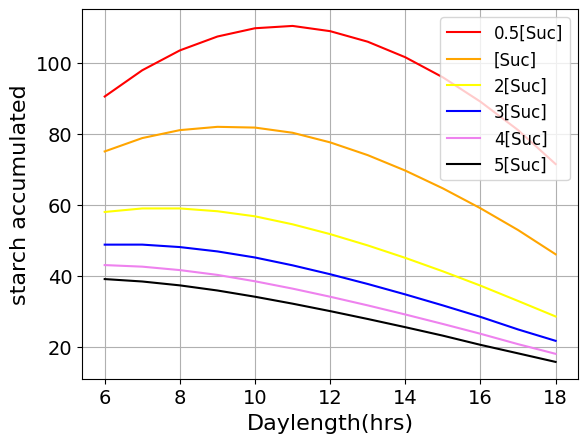

In [ ]:
import matplotlib.pyplot as plt

fig, ax=plt.subplots()
ax.plot(dL,z0,'red',label='0.5[Suc]')
ax.plot(dL,z1,'orange',label='[Suc]')
ax.plot(dL,z2,'yellow',label='2[Suc]')
ax.plot(dL,z3,'blue',label='3[Suc]')
ax.plot(dL,z4,'violet',label='4[Suc]')
ax.plot(dL,z5,'black',label='5[Suc]')


legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel("Daylength(hrs)", fontsize=16)
plt.ylabel("starch accumulated", fontsize=16)


#day only
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(fontsize=12)

plt.grid()
plt.savefig("plot.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
def phloemoutcon(org_model,r):
  C3_dup5_model=org_model.copy()
  #constraining the phloem export reaction sucrose aminoacid ratio
  Suc=C3_dup5_model.metabolites.sSUCROSE_b_Dark
  Proton_e_Suc=C3_dup5_model.metabolites.PROTON_e_Dark
  Proton_c_Suc=C3_dup5_model.metabolites.PROTON_c_Dark
  phloemout=C3_dup5_model.reactions.Phloem_output_tx_Dark

  Sucstoich=phloemout.metabolites[Suc]
  phloemout.add_metabolites({Suc:r*Sucstoich})
  phloemout.add_metabolites({Proton_e_Suc:r*Sucstoich})
  phloemout.add_metabolites({Proton_c_Suc:-r*Sucstoich})



  Suc2=C3_dup5_model.metabolites.sSUCROSE_b_Light
  Proton_e_Suc2=C3_dup5_model.metabolites.PROTON_e_Light
  Proton_c_Suc2=C3_dup5_model.metabolites.PROTON_c_Light
  phloemout2=C3_dup5_model.reactions.Phloem_output_tx_Light

  Sucstoich2=phloemout2.metabolites[Suc2]
  phloemout2.add_metabolites({Suc2:r*Sucstoich2})
  phloemout2.add_metabolites({Proton_e_Suc2:r*Sucstoich2})
  phloemout2.add_metabolites({Proton_c_Suc2:-r*Sucstoich2})
  pfba(C3_dup5_model)
  #print(phloemout)
  #print(phloemout2)
  starchacc=[]
  for dl in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
   starchacc.append((calculateTransitoryStarchLevels(C3_dup5_model,dl))*dl*3600/1000)
  print(starchacc)

  #print(6+starchacc.index(max(starchacc)))

In [ ]:
for r in range(5):
  phloemoutcon(C3_dup1_model,r)

9
9
9
9
9


In [ ]:
for r in [-0.5,1,2,3,4]:
  phloemoutcon(C3_dup1_model,r)

[75.36540562877273, 78.79779771983495, 80.57187803172422, 80.94679502966581, 80.11376431205235, 78.2308379512822, 74.25255428659474, 70.92584506610231, 67.19655468198367, 62.87531097501305, 58.023809150770184, 52.69534099226912, 46.93618693169635]
[74.56895048237288, 78.16044113861656, 80.2085393520459, 80.92747236924235, 80.49347817287736, 79.05287628611322, 76.72816419350566, 73.62268087326942, 69.82421560102618, 65.40783026253887, 60.1450128498111, 54.045750358440856, 47.38737319557186]
[74.411260248269, 77.94186598292536, 79.92138279480184, 80.56486279919211, 80.04929416795287, 78.52167092349875, 76.10509276014456, 72.90343406286092, 69.00495898130337, 64.48515008957779, 59.40894326027778, 53.8325092805893, 47.70266594630541]
[74.32956869223037, 77.82861265796399, 79.77257080982949, 80.37692248990197, 79.81904469594546, 78.24628125132666, 75.78204431663791, 72.53048619871629, 68.58011763765994, 64.00663973210825, 58.87518192918079, 53.242086521049615, 47.15634336318493]
[74.2796031

In [ ]:
phloemoutcon(C3_dup1_model,0)

[75.00092868218816, 78.75894400633584, 80.99452440386267, 81.91963631606136, 81.70846520645415, 80.25262573184554, 77.54705848304363, 73.95827583529119, 69.61076119092847, 64.60572542793348, 59.013161692252446, 52.893502746138196, 46.06755859506131]


In [ ]:
x0=[75.36540562877273, 78.79779771983495, 80.57187803172422, 80.94679502966581, 80.11376431205235, 78.2308379512822, 74.25255428659474, 70.92584506610231, 67.19655468198367, 62.87531097501305, 58.023809150770184, 52.69534099226912, 46.93618693169635]
x1=[75.00092868218816, 78.75894400633584, 80.99452440386267, 81.91963631606136, 81.70846520645415, 80.25262573184554, 77.54705848304363, 73.95827583529119, 69.61076119092847, 64.60572542793348, 59.013161692252446, 52.893502746138196, 46.06755859506131]
x2=[74.56895048237288, 78.16044113861656, 80.2085393520459, 80.92747236924235, 80.49347817287736, 79.05287628611322, 76.72816419350566, 73.62268087326942, 69.82421560102618, 65.40783026253887, 60.1450128498111, 54.045750358440856, 47.38737319557186]
x3=[74.411260248269, 77.94186598292536, 79.92138279480184, 80.56486279919211, 80.04929416795287, 78.52167092349875, 76.10509276014456, 72.90343406286092, 69.00495898130337, 64.48515008957779, 59.40894326027778, 53.8325092805893, 47.70266594630541]
x4=[74.32956869223037, 77.82861265796399, 79.77257080982949, 80.37692248990197, 79.81904469594546, 78.24628125132666, 75.78204431663791, 72.53048619871629, 68.58011763765994, 64.00663973210825, 58.87518192918079, 53.242086521049615, 47.15634336318493]
x5=[74.2796031508272, 77.75933595990658, 79.68153503571651, 80.26194099390347, 79.67816871498184, 78.0777760995903, 75.58436658867626, 72.3022626623259, 68.3201260809829, 63.71379179650963, 58.54850784761874, 52.880721610592026, 46.75951610949635]


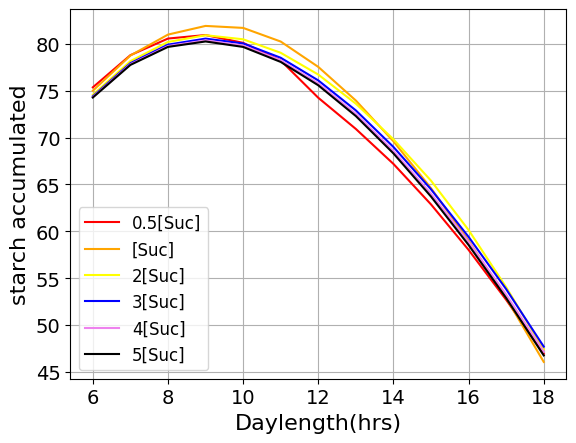

In [ ]:
import matplotlib.pyplot as plt

fig, ax=plt.subplots()
ax.plot(dL,x0,'red',label='0.5[Suc]')
ax.plot(dL,x1,'orange',label='[Suc]')
ax.plot(dL,x2,'yellow',label='2[Suc]')
ax.plot(dL,x3,'blue',label='3[Suc]')
ax.plot(dL,x4,'violet',label='4[Suc]')
ax.plot(dL,x5,'black',label='5[Suc]')


legend=ax.legend(loc="best",shadow=True,fontsize='small')

#plt.title('Starch accumulation vs Daylength (For constraining sucrose phloem export (Day and Night)) ')
plt.xlabel("Daylength(hrs)", fontsize=16)
plt.ylabel("starch accumulated", fontsize=16)


#day only
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(fontsize=12)

plt.grid()
plt.savefig("plot.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
for r in [-0.5,0,4,8,16]:
  phloemoutcon(C3_dup1_model,r)

[75.36540562877273, 78.79779771983495, 80.57187803172422, 80.94679502966581, 80.11376431205235, 78.2308379512822, 74.25255428659474, 70.92584506610231, 67.19655468198367, 62.87531097501305, 58.023809150770184, 52.69534099226912, 46.93618693169635]
[75.00092868218816, 78.75894400633584, 80.99452440386267, 81.91963631606136, 81.70846520645415, 80.25262573184554, 77.54705848304363, 73.95827583529119, 69.61076119092847, 64.60572542793348, 59.013161692252446, 52.893502746138196, 46.06755859506131]
[74.2796031508272, 77.75933595990658, 79.68153503571651, 80.26194099390347, 79.67816871498184, 78.0777760995903, 75.58436658867626, 72.3022626623259, 68.3201260809829, 63.71379179650963, 58.54850784761874, 52.880721610592026, 46.75951610949635]
[74.1889574893232, 77.6336434766831, 79.51634845342696, 80.05328696066843, 79.42250555815025, 77.7719507600758, 75.22557334005843, 71.888004860378, 67.84818143619164, 63.182181235643235, 57.955467812983656, 52.224679547110945, 46.03906882545761]
[74.1345186

In [ ]:
w0=[75.36540562877273, 78.79779771983495, 80.57187803172422, 80.94679502966581, 80.11376431205235, 78.2308379512822, 74.25255428659474, 70.92584506610231, 67.19655468198367, 62.87531097501305, 58.023809150770184, 52.69534099226912, 46.93618693169635]
w1=[75.00092868218816, 78.75894400633584, 80.99452440386267, 81.91963631606136, 81.70846520645415, 80.25262573184554, 77.54705848304363, 73.95827583529119, 69.61076119092847, 64.60572542793348, 59.013161692252446, 52.893502746138196, 46.06755859506131]
w2=[74.2796031508272, 77.75933595990658, 79.68153503571651, 80.26194099390347, 79.67816871498184, 78.0777760995903, 75.58436658867626, 72.3022626623259, 68.3201260809829, 63.71379179650963, 58.54850784761874, 52.880721610592026, 46.75951610949635]
w3=[74.1889574893232, 77.6336434766831, 79.51634845342696, 80.05328696066843, 79.42250555815025, 77.7719507600758, 75.22557334005843, 71.888004860378, 67.84818143619164, 63.182181235643235, 57.955467812983656, 52.224679547110945, 46.03906882545761]
w4=[74.13451860489903, 77.55814839506712, 79.41712234358947, 79.92793957265538, 79.26890596871218, 77.58820158533199, 75.00998598925194, 71.63907659205867, 67.56457451168, 62.862704220466014, 57.59905893914523, 51.830391977900696, 45.60605765174664]


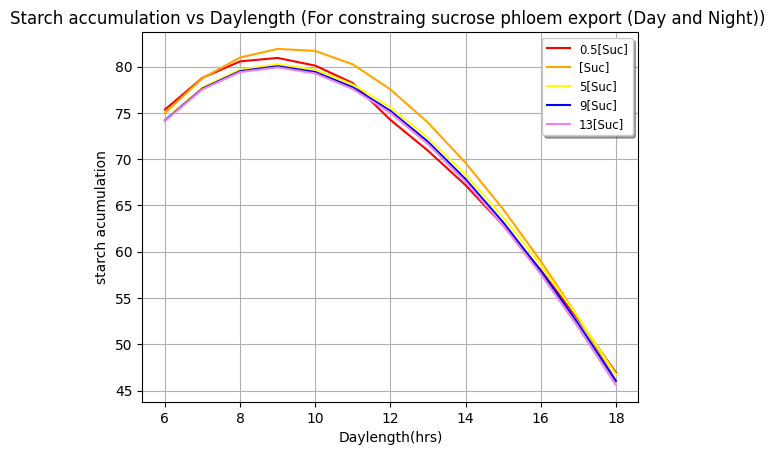

In [ ]:
import matplotlib.pyplot as plt

fig, ax=plt.subplots()
ax.plot(dL,w0,'red',label='0.5[Suc]')
ax.plot(dL,w1,'orange',label='[Suc]')
ax.plot(dL,w2,'yellow',label='5[Suc]')
ax.plot(dL,w3,'blue',label='9[Suc]')
ax.plot(dL,w4,'violet',label='13[Suc]')


legend=ax.legend(loc="best",shadow=True,fontsize='small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch accumulation vs Daylength (For constraing sucrose phloem export (Day and Night)) ')

plt.grid()
plt.show()

Phloem export Day:Night ratio in micromol/m2/s

In [ ]:
C3_dup1_model.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
CARBON_DIOXIDE_e_Light,CO2_tx_Light,35.17,1,100.00%
WATER_e_Light,H2O_tx_Light,31.58,0,0.00%
NITRATE_e_Dark,Nitrate_tx_Dark,0.1091,0,0.00%
NITRATE_e_Light,Nitrate_tx_Light,0.1636,0,0.00%
OXYGEN_MOLECULE_e_Dark,O2_tx_Dark,1.992,0,0.00%
Photon_e_Light,Photon_tx_Light,500,0,0.00%
SULFATE_e_Light,SO4_tx_Light,0.002773,0,0.00%
PROTON_c_Light,unlProtHYPO_c_Light,0.2308,0,0.00%
Metabolite,Reaction,Flux,C-Number,C-Flux
CARBON_DIOXIDE_e_Dark,CO2_tx_Dark,-1.894,1,100.00%


In [ ]:
def phloemlightday(Orig_model,daylength):
  new_model = Orig_model.copy()

  #update stoichiometry of linker reactions based on daylength
  for rxn in new_model.reactions.query('_dielTransfer'):
    for met in rxn.reactants:
      stoich = rxn.metabolites[met]
      rxn.add_metabolites({met:round((-1*stoich)+(stoich*(24-daylength)/daylength),20)})


  # perform pFBA
  tempsol = pfba(new_model)
  print(new_model.reactions.Phloem_output_tx_Light.flux/new_model.reactions.Phloem_output_tx_Dark.flux)
  print((new_model.reactions.Phloem_output_tx_Light.flux*daylength)/(new_model.reactions.Phloem_output_tx_Dark.flux*(24-daylength)))#since the unit conversions are same on both numerator and denominator they just cancel


In [ ]:
for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
  print('For daylength###############################',daylength)
  phloemlightday(C3_dup1_model,daylength)

For daylength############################### 6
2.9999999999999996
0.9999999999999998
For daylength############################### 7
2.999999999999999
1.2352941176470584
For daylength############################### 8
2.999999999999999
1.4999999999999996
For daylength############################### 9
2.999999999999999
1.7999999999999994
For daylength############################### 10
2.999999999999999
2.1428571428571423
For daylength############################### 11
2.9999999999999987
2.5384615384615374
For daylength############################### 12
2.999999999999999
2.999999999999999
For daylength############################### 13
2.9999999999999987
3.5454545454545436
For daylength############################### 14
2.999999999999999
4.199999999999998
For daylength############################### 15
2.999999999999999
4.999999999999999
For daylength############################### 16
2.999999999999999
5.999999999999998
For daylength############################### 17
3.0
7.285714285714286


Phloem export Day:Night ratio in millimol/m2/Day

sucrose mmol per day, sucrose to aminoacid from the model, the pattern they follow from the model
inorganic phosphates increase check

Since we want our model to say the phloem export ratio day:night for sucrose and aminoacid here,so we can't impose the objective reaction constraint of  phloem export ratio day:night in prior to be 3:1.
So for this model what is the objective?

In [ ]:
print(C3_dup_model.reactions.get_by_id('Phloem_output_tx_Light'))
print(C3_dup_model.reactions.get_by_id('Phloem_output_tx_Light').flux)
print(C3_dup_model.reactions.get_by_id('Phloem_output_tx_Dark').flux)

Phloem_output_tx_Light: 0.0022970297 4_AMINO_BUTYRATE_c_Light + 0.0004186704 ARG_c_Light + 0.0015049505 ASN_c_Light + 0.0004186704 CYS_c_Light + 0.0792079208 FRU_c_Light + 0.0693069307 GLC_c_Light + 0.0240792079 GLN_c_Light + 0.0124356436 GLT_c_Light + 0.0007128713 GLY_c_Light + 0.0004186704 HIS_c_Light + 0.0017425743 ILE_c_Light + 0.0020594059 LEU_c_Light + 0.0022178218 LYS_c_Light + 0.0038811881 L_ALPHA_ALANINE_c_Light + 0.006019802 L_ASPARTATE_c_Light + 0.0004186704 MET_c_Light + 0.0057029703 PHE_c_Light + 0.9603960396 PROTON_e_Light + 0.0004186704 PRO_c_Light + 0.003960396 SER_c_Light + 0.0068910891 THR_c_Light + 0.0004186704 TRP_c_Light + 0.0004186704 TYR_c_Light + 0.0027722772 VAL_c_Light + 0.7326732673 sSUCROSE_b_Light --> 0.9603960396 PROTON_c_Light
0.0
0.0


Model 3 all constraints except PPFD and VATPase is given

In [ ]:
from cobra.io import write_sbml_model
Model3=write_sbml_model(C3_dup_model,'Model3')

In [ ]:
def daynightnew1(org1_model,daylength):
  org_model=org1_model.copy()
  #Setting photosythetically active photon flux intensity
  PPFD = ((500*daylength*3600)/10000 )#centimol/m2/day
  org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
  org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
  org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
  org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0



  VATPase = (0.0049*PPFD)+2.7851#From cheung paper
  print(VATPase)
  org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
  pfba(org_model)
  # Starch synthesis reaction is identified
  StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

  # Number of moles of starch (GLC units) generated by the reaction is noted
  StarchDayStoich = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light").metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]

  # Print starch synthesis rate
  #print("Starch synthesis rate (centimol GLC/m2/day) ="+str(StarchSynDay.flux*StarchDayStoich)) #Starch(in centimol) accumulated per m2 in 1 day
  print("Total starch accumulated over "+str(daylength)+"hr photoperiod (centimol GLC/m2) ="+str(StarchSynDay.flux*StarchDayStoich))#starch accumulated (in centimol)
  print("")



  # Starch degradation reactions is identified
  StarchDegNight1 = org_model.reactions.get_by_id("RXN_1827_p_Dark")
  StarchDegNight2 = org_model.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
  StarchDegNight3 = org_model.reactions.get_by_id("RXN_1826_p_Dark")

  # Number of moles of starch (GLC units) generated by the reactions is noted
  StarchNight1Stoich = org_model.reactions.get_by_id("RXN_1827_p_Dark").metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
  StarchNight2Stoich = org_model.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark").metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
  StarchNight3Stoich = org_model.reactions.get_by_id("RXN_1826_p_Dark").metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]

  # Print starch degradation rate (flux is converted to absolute values)
  #print("Starch degradation rate1 by hydrolysis (centimol GLC/m2/day) ="+str((StarchDegNight1.flux*StarchNight1Stoich)))
  # print("Starch degradation rate2 by hydrolysis (centimol GLC/m2/day) ="+str((StarchDegNight2.flux*StarchNight2Stoich)))
  # print("Starch degradation rate3 by hydrolysis (centimol GLC/m2/day) ="+str((StarchDegNight3.flux*StarchNight3Stoich)))
  print("Total starch degraded over "+str(24-daylength)+"hr photoperiod (centimol GLC/m2) ="+str(abs(((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich)))))



In [ ]:
for dl in [6,8,10,12,14,16,18]:
  daynightnew1(C3_dup_model,dl)

8.0771
Total starch accumulated over 6hr photoperiod (centimol GLC/m2) =3.515354201063152

Total starch degraded over 18hr photoperiod (centimol GLC/m2) =3.515354201063152
9.8411
Total starch accumulated over 8hr photoperiod (centimol GLC/m2) =3.5704814274433

Total starch degraded over 16hr photoperiod (centimol GLC/m2) =3.5704814274432994
11.6051
Total starch accumulated over 10hr photoperiod (centimol GLC/m2) =3.625608653814446

Total starch degraded over 14hr photoperiod (centimol GLC/m2) =3.625608653814446
13.3691
Total starch accumulated over 12hr photoperiod (centimol GLC/m2) =3.6807358801868126

Total starch degraded over 12hr photoperiod (centimol GLC/m2) =3.6807358801868126
15.133099999999999
Total starch accumulated over 14hr photoperiod (centimol GLC/m2) =3.735690911712777

Total starch degraded over 10hr photoperiod (centimol GLC/m2) =3.7356909117127763
16.897100000000002
Total starch accumulated over 16hr photoperiod (centimol GLC/m2) =3.7904080908365425

Total starch deg

In [ ]:
def daynightnew3(org1_model,daylength):
  org_model=org1_model.copy()
  #Setting photosythetically active photon flux intensity
  PPFD = (500*daylength*3600)/10000 #centimol/m2/day
  org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
  org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
  org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
  org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0



  VATPase = 0.0049*PPFD+2.7851#From cheung paper
  print(VATPase)
  org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
  pfba(org_model)


  #sucrose exudation in day:night ratio
  sucday=org_model.metabolites.get_by_id('sSUCROSE_b_Light')
  phloemday=org_model.reactions.get_by_id('Phloem_output_tx_Light')
  print("Amount of sucrose exudated during day(centimol Suc/m2/day)=",phloemday.metabolites[sucday]*phloemday.flux)

  sucnight=org_model.metabolites.get_by_id('sSUCROSE_b_Dark')
  phloemnight=org_model.reactions.get_by_id('Phloem_output_tx_Dark')
  print("Amount of sucrose exudated during night(centimol Suc/m2/day)=",phloemnight.metabolites[sucnight]*phloemnight.flux)

  print("sucrose exudation in day:night ratio=",((phloemday.metabolites[sucday]*phloemday.flux)/(phloemnight.metabolites[sucnight]*phloemnight.flux)))


In [ ]:
for dl in [6,8,10,12,14,16,18]:
  daynightnew3(C3_dup_model,dl)

8.0771
Amount of sucrose exudated during day(centimol Suc/m2/day)= -3.6974497148691117
Amount of sucrose exudated during night(centimol Suc/m2/day)= -1.2324832382897042
sucrose exudation in day:night ratio= 2.999999999999999
9.8411
Amount of sucrose exudated during day(centimol Suc/m2/day)= -3.6543753351704282
Amount of sucrose exudated during night(centimol Suc/m2/day)= -1.2181251117234764
sucrose exudation in day:night ratio= 2.999999999999999
11.6051
Amount of sucrose exudated during day(centimol Suc/m2/day)= -3.6113009554717426
Amount of sucrose exudated during night(centimol Suc/m2/day)= -1.203766985157248
sucrose exudation in day:night ratio= 2.999999999999999
13.3691
Amount of sucrose exudated during day(centimol Suc/m2/day)= -3.568226575773063
Amount of sucrose exudated during night(centimol Suc/m2/day)= -1.1894088585910214
sucrose exudation in day:night ratio= 2.999999999999999
15.133099999999999
Amount of sucrose exudated during day(centimol Suc/m2/day)= -3.5251519767743433
A

Another way

In [ ]:
from cobra.flux_analysis import pfba
pfba(C3_dup_model)

,fluxes,reduced_costs
PRO_PROTON_vc_Light,0.000000e+00,416.149386
Ca_tx_Light,7.528019e+01,-2.000000
H2O_xc_Light,3.833784e-13,2.000000
sCIT_biomass_Light,-2.256017e+01,2.000000
ACETYLGLUTKIN_RXN_p_Light,0.000000e+00,-2.000000
...,...,...
SUCROSE_v_dielTransferReverse,-1.270189e+02,2.000000
PRO_v_dielTransfer,0.000000e+00,839.201574
CIT_v_dielTransferReverse,-1.533508e+02,2.000000
HIS_v_dielTransfer,0.000000e+00,4113.339453


In [ ]:
from cobra.io import write_sbml_model
Model4=write_sbml_model(C3_dup_model,'Model4')


Model 4 with only the 2 copy+ acc reactions added

In [ ]:
!pip install cobra --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.8/141.8 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 109.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 60.5 MB/s eta 0:00:00


In [ ]:
from cobra.io import read_sbml_model
C3_dup_model=read_sbml_model('Model4')

Constraining in other ways

phloem export day:night change for different daylength, per s, per day
day:night/ 3:1,2:1,1:1,1:2,1:3

flux per day

In [ ]:
pfba(C3_dup_model)

,fluxes,reduced_costs
PRO_PROTON_vc_Light,0.000000e+00,2.000000
Ca_tx_Light,1.709306e+00,-2.000000
H2O_xc_Light,7.888209e+00,-2.000000
sCIT_biomass_Light,-5.122494e-01,2.000000
ACETYLGLUTKIN_RXN_p_Light,4.830905e-01,-2.000000
...,...,...
SUCROSE_v_dielTransferReverse,0.000000e+00,604.543023
PRO_v_dielTransfer,0.000000e+00,1455.353408
CIT_v_dielTransferReverse,7.459508e-15,2.000000
HIS_v_dielTransfer,0.000000e+00,8977.119848


In [ ]:
C3_dup1_model=C3_dup_model.copy()

Flux flow in model per day




In [ ]:
def phloemdaynight(orggg_model,d,n):
  orgg_model=orggg_model.copy()
  #Setting photosythetically active photon flux intensity
  starchacc=[]

  for daylength in [6,9,12,15,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((n*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(d*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)
      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-d*(daylength),phloem_transport_Dark:-n*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
      Constraint1=org_model.problem.Constraint(((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression)-(3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression),lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)


      nitrateflux=org_model.problem.Constraint((2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression),
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)
      NGAM_constraint=org_model.problem.Constraint((3*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression))-org_model.reactions.ATPase_tx_Light.flux_expression,
                                                  lb=0,ub=0)
      org_model.add_cons_vars(NGAM_constraint)
      NGAM_constraint2=org_model.problem.Constraint((3*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression))-org_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
      org_model.add_cons_vars(NGAM_constraint2)
      atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(daylength*org_model.reactions.ATPase_tx_Dark.flux_expression),
                                            lb=0,ub=0)
      org_model.add_cons_vars(atpdaynightconstraint)
      NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression)-(daylength*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
                                                        lb=0,ub=0)
      org_model.add_cons_vars(NADPHdaynightconstraint)
      from cobra.flux_analysis import pfba
      pfba(org_model)

      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day


      # Starch degradation reactions is identified
      #StarchDegNight1 = org_model.reactions.get_by_id("RXN_1827_p_Dark")
      #StarchDegNight2 = org_model.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
      #StarchDegNight3 = org_model.reactions.get_by_id("RXN_1826_p_Dark")

      # Number of moles of starch (GLC units) generated by the reactions is noted
      #StarchNight1Stoich =  StarchDegNight1.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
      #StarchNight2Stoich =  StarchDegNight2.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
      #StarchNight3Stoich =  StarchDegNight3.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]


      #starchdeg.append(abs((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich)))
  print(starchacc)


In [ ]:
for d in [3,2,1]:
  print("For ratio =",d,":1")
  phloemdaynight(C3_dup_model,d,1)

For ratio = 3 :1
[0.07503821948323033, 0.08221495305782558, 0.07733052707043153, 0.06442704237614565, 0.045941981207871546]
For ratio = 2 :1
[0.0856411295092406, 0.09896109905143584, 0.09893593988968893, 0.08612775184302736, 0.0638720023118125]
For ratio = 1 :1
[0.1014538850060643, 0.1280835322302794, 0.13844372441910235, 0.1323727725385397, 0.10782244410419024]


In [ ]:
for n in [2,3]:
  print("For ratio = 1:",n)
  phloemdaynight(C3_dup_model,1,n)

For ratio = 1: 2
[0.11268165061096691, 0.15254510145157973, 0.17764132933231436, 0.1837938770883191, 0.16508809995048762]
For ratio = 1: 3
[0.1171571692924361, 0.16336397843858788, 0.19712495372079727, 0.21299029956184937, 0.20178809011791263]


In [ ]:
#For ratio = 3 :1
h1=[0.07503821948323033, 0.08221495305782558, 0.07733052707043153, 0.06442704237614565, 0.045941981207871546]
#For ratio = 2 :1
h2=[0.0856411295092406, 0.09896109905143584, 0.09893593988968893, 0.08612775184302736, 0.0638720023118125]
#For ratio = 1 :1
h3=[0.1014538850060643, 0.1280835322302794, 0.13844372441910235, 0.1323727725385397, 0.10782244410419024]
#For ratio = 1: 2
h4=[0.11268165061096691, 0.15254510145157973, 0.17764132933231436, 0.1837938770883191, 0.16508809995048762]
#For ratio = 1: 3
h5=[0.1171571692924361, 0.16336397843858788, 0.19712495372079727, 0.21299029956184937, 0.20178809011791263]


In [ ]:
import pandas as pd
import numpy as np
phm={"daylength":dL,"3":h1,"2":h2,"1":h3,"0.5":h4,"0.333":h5}
df0=pd.DataFrame(phm)
print(df0)
df0 = df0.set_index("daylength")

   daylength         3         2         1       0.5     0.333
0          6  0.075038  0.085641  0.101454  0.112682  0.117157
1          9  0.082215  0.098961  0.128084  0.152545  0.163364
2         12  0.077331  0.098936  0.138444  0.177641  0.197125
3         15  0.064427  0.086128  0.132373  0.183794  0.212990
4         18  0.045942  0.063872  0.107822  0.165088  0.201788


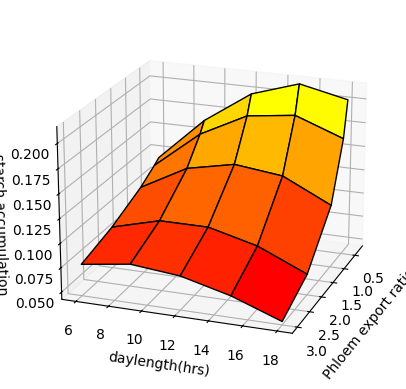

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(df0.columns.astype(float),df0.index)
z = df0.values.astype(float)



fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('Phloem export ratio')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('starch accumulation')


ax.plot_surface(x, y, z, cmap='autumn', edgecolor='black')
ax.view_init(elev=20, azim=20)
plt.show()

In [ ]:
#For ratio = 3 :1
q1=[0.07503821948323033, 0.07887104274875083, 0.08119319629164272, 0.08221495305782558, 0.08178874460331403, 0.08002767659852558, 0.07733052707043153, 0.07375237006483713, 0.06941762106191655, 0.06442704237614565, 0.05885043465482886, 0.052748066070505854, 0.045941981207871546]
#For ratio = 2 :1
q2=[0.0856411295092406, 0.09179267108843293, 0.09618139135049142, 0.09896109905143584, 0.10026810494262701, 0.10022365008955243, 0.09893593988968893, 0.09592530995850101, 0.09155824880016335, 0.08612775184302736, 0.07961556613429084, 0.07217323126909343, 0.0638720023118125]
#For ratio = 1 :1
q3=[0.1014538850060643, 0.11212832908196461, 0.12100682602305378, 0.1280835322302794, 0.13335255369081528, 0.13680794770489377, 0.13844372441910235, 0.1382538481905668, 0.13623223880137056, 0.1323727725385397, 0.1266692831564788, 0.11863779652527097, 0.10782244410419024]
#For ratio = 1: 2
q4=[0.11268165061096691, 0.1274041887421985, 0.14072904279605417, 0.15254510145157973, 0.16272954761582872, 0.1711457406353197, 0.17764132933231436, 0.182045955288957, 0.18416851032185222, 0.1837938770883191, 0.18067903547901432, 0.17454838598552655, 0.16508809995048762]
#For ratio = 1: 3
q5=[0.1171571692924361, 0.13370007159108713, 0.1491437508934195, 0.16336397843858788, 0.1762170922632197, 0.1875358839611526, 0.19712495372079727, 0.20475435763923883, 0.21015138904319247, 0.21299029956184937, 0.21287874251905575, 0.20933983469037942, 0.20178809011791263]

dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]

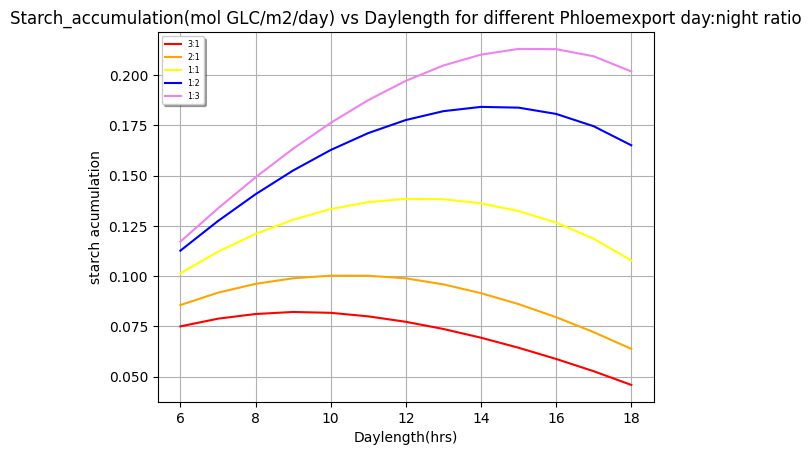

In [ ]:
import matplotlib.pyplot as plt

fig, ax=plt.subplots()
ax.plot(dL,q1,'red',label='3:1')
ax.plot(dL,q2,'orange',label='2:1')
ax.plot(dL,q3,'yellow',label='1:1')
ax.plot(dL,q4,'blue',label='1:2')
ax.plot(dL,q5,'violet',label='1:3')


legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch_accumulation(mol GLC/m2/day) vs Daylength for different Phloemexport day:night ratio')

plt.grid()
plt.show()

 for flux per s

In [ ]:
pfba(C3_dup_model)

,fluxes,reduced_costs
PRO_PROTON_vc_Light,0.000000,2.000000
Ca_tx_Light,1.297182,-2.000000
H2O_xc_Light,11.640577,-2.000000
sCIT_biomass_Light,-0.388743,2.000000
ACETYLGLUTKIN_RXN_p_Light,0.366614,-2.000000
...,...,...
SUCROSE_v_dielTransferReverse,0.000000,385.171429
PRO_v_dielTransfer,0.000000,1269.461429
CIT_v_dielTransferReverse,0.948340,-2.000000
HIS_v_dielTransfer,0.000000,5337.298571


In [ ]:
from cobra.io import write_sbml_model
C3_dup7_model=write_sbml_model(C3_dup_model,'phloemDNs_model')

Flux flow in model per s

In [ ]:
def sphloemdaynight(orggg_model,d,n):
  orgg_model=orggg_model.copy()
  Phloem_biomass=orgg_model.problem.Constraint(
    n*orgg_model.reactions.Phloem_output_tx_Light.flux_expression-d*orgg_model.reactions.Phloem_output_tx_Dark.flux_expression,
    lb=0,ub=0)
  orgg_model.add_cons_vars(Phloem_biomass)
    #Making the objective reaction
  from cobra import Reaction,Metabolite
  #Making new metabolites and adding it to existing phloem transport reaction
  phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
  orgg_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
  phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
  orgg_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
  #Making new reaction
  rxn = Reaction('diel_biomass')
  rxn.add_metabolites({phloem_transport_Light:-d,phloem_transport_Dark:-n})
  rxn.lower_bound=0
  rxn.upper_bound=1000
  orgg_model.add_reactions([rxn])
  orgg_model.objective='diel_biomass'
  orgg_model.optimize()


  from cobra.flux_analysis import pfba
  pfba(orgg_model)
  Starchacc=[]
  #Starchdeg=[]
  StarchAccumRateList=[]
  #StarchDegRatesumList=[]

  for daylength in [6,9,12,15,18]:
    org_model=orgg_model.copy()
    StarchAccumRate = calculateTransitoryStarchLevels(org_model,daylength)
    StarchAccumRateList.append(StarchAccumRate)
    Starchacc.append(round((StarchAccumRate*daylength*3600/1000),6))

    #StarchDegRatesum= calculateTransitoryDegStarchLevels(org_model,daylength)
    #StarchDegRatesumList.append(StarchDegRatesum)
    #Starchdeg.append(round((abs(StarchDegRatesum)*(24-daylength)*3600/1000),0))


  print(Starchacc)
  #print(Starchdeg)

In [ ]:
for d in [3,2,1]:
  print("For ratio =",d,":1")
  sphloemdaynight(C3_dup_model,d,1)

For ratio = 3 :1
[75.000929, 81.919636, 77.547058, 64.605725, 46.067559]
For ratio = 2 :1
[85.698573, 98.809531, 98.469774, 86.37729, 64.055324]
For ratio = 1 :1
[101.653744, 128.1842, 138.312154, 131.876398, 108.147453]


In [ ]:
for n in [2,3]:
  print("For ratio =1:",n)
  sphloemdaynight(C3_dup_model,1,n)

For ratio =1: 2
[112.983456, 152.859843, 177.845494, 183.730729, 164.554621]
For ratio =1: 3
[117.499803, 163.774045, 197.497396, 213.175387, 201.561948]


In [ ]:
for d in [3,2,1]:
  print("For ratio =",d,":1")
  sphloemdaynight(C3_dup_model,d,1)


For ratio = 3 :1
[75.0, 82.0, 78.0, 65.0, 46.0]
For ratio = 2 :1
[86.0, 99.0, 98.0, 86.0, 64.0]
For ratio = 1 :1
[102.0, 128.0, 138.0, 132.0, 108.0]


In [ ]:
for n in [2,3]:
  print("For ratio =1:",n)
  sphloemdaynight(C3_dup_model,1,n)

For ratio =1: 2
[113.0, 153.0, 178.0, 184.0, 165.0]
For ratio =1: 3
[117.0, 164.0, 197.0, 213.0, 202.0]


In [ ]:
#For ratio = 3 :1
x1=[75.000929, 81.919636, 77.547058, 64.605725, 46.067559]
#For ratio = 2 :1
x2=[85.698573, 98.809531, 98.469774, 86.37729, 64.055324]
#For ratio = 1 :1
x3=[101.653744, 128.1842, 138.312154, 131.876398, 108.147453]
#For ratio =1: 2
x4=[112.983456, 152.859843, 177.845494, 183.730729, 164.554621]
#For ratio =1: 3
x5=[117.499803, 163.774045, 197.497396, 213.175387, 201.561948]
dL=[6,9,12,15,18]

In [ ]:
import pandas as pd
import numpy as np
phlms={"daylength":dL,"3":x1,"2":x2,"1":x3,"0.5":x4,"0.333":x5}
DF0=pd.DataFrame(phlms)
print(DF0)
DF0=DF0.set_index("daylength")

   daylength          3          2           1         0.5       0.333
0          6  75.000929  85.698573  101.653744  112.983456  117.499803
1          9  81.919636  98.809531  128.184200  152.859843  163.774045
2         12  77.547058  98.469774  138.312154  177.845494  197.497396
3         15  64.605725  86.377290  131.876398  183.730729  213.175387
4         18  46.067559  64.055324  108.147453  164.554621  201.561948


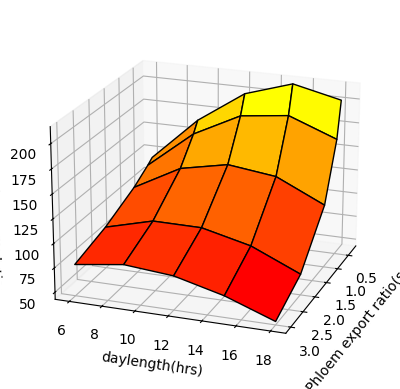

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(DF0.columns.astype(float),DF0.index)
z = DF0.values.astype(float)



fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('Phloem export ratio(sec)')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('starch accumulation')


ax.plot_surface(x, y, z, cmap='autumn', edgecolor='black')
ax.view_init(elev=20, azim=20)
plt.show()

In [ ]:
z3_1=[75.0, 79.0, 81.0, 82.0, 82.0, 80.0, 78.0, 74.0, 70.0, 65.0, 59.0, 53.0, 46.0]
z2_1=[86.0, 92.0, 96.0, 99.0, 100.0, 100.0, 98.0, 96.0, 92.0, 86.0, 80.0, 72.0, 64.0]
z1_1=[102.0, 112.0, 121.0, 128.0, 133.0, 137.0, 138.0, 138.0, 136.0, 132.0, 126.0, 118.0, 108.0]
z1_3=[117.0, 134.0, 150.0, 164.0, 177.0, 188.0, 197.0, 205.0, 210.0, 213.0, 213.0, 209.0, 202.0]
z1_2=[113.0, 128.0, 141.0, 153.0, 163.0, 171.0, 178.0, 182.0, 184.0, 184.0, 180.0, 174.0, 165.0]
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]

In [ ]:
print(6+z3_1.index(max(z3_1)))
print(6+z2_1.index(max(z2_1)))
print(6+z1_1.index(max(z1_1)))
print(6+z1_2.index(max(z1_2)))
print(6+z1_3.index(max(z1_3)))

9
10
12
14
15


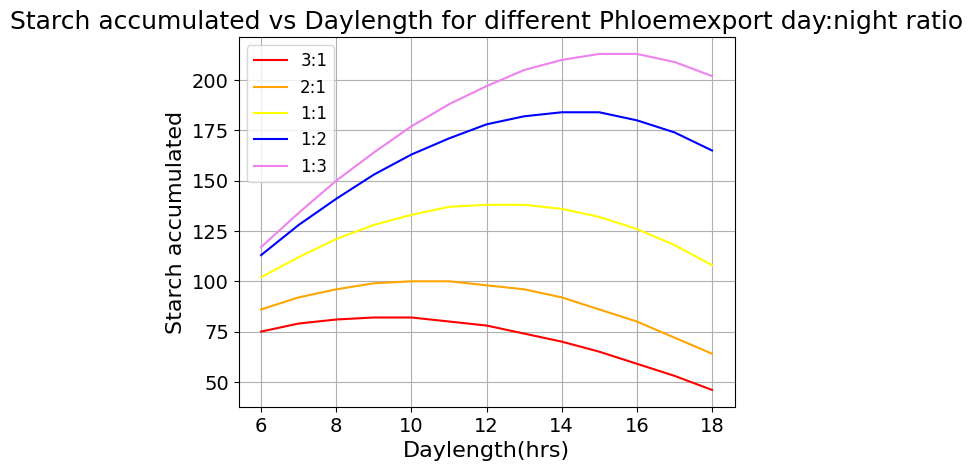

In [ ]:
import matplotlib.pyplot as plt

fig, ax=plt.subplots()
ax.plot(dL,z3_1,'red',label='3:1')
ax.plot(dL,z2_1,'orange',label='2:1')
ax.plot(dL,z1_1,'yellow',label='1:1')
ax.plot(dL,z1_2,'blue',label='1:2')
ax.plot(dL,z1_3,'violet',label='1:3')


legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')

plt.title('Starch accumulated vs Daylength for different Phloemexport day:night ratio')
plt.xlabel("Daylength(hrs)", fontsize=16)
plt.ylabel("Starch accumulated", fontsize=16)

plt.title('Starch accumulated vs Daylength for different Phloemexport day:night ratio',fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(fontsize=12)
plt.grid()
plt.show()

per day

In [ ]:
C3_dup2_model=C3_dup_model.copy()

In [ ]:
C3_dup2back_model=C3_dup_model.copy()

In [ ]:
Model=read_sbml_model('Without3atpppfdconst')

In [ ]:
def AtpNADPH(orggg_model,m):
  orgg_model=orggg_model.copy()

  NGAM_constraint=orgg_model.problem.Constraint(m*(orgg_model.reactions.NADPHoxc_tx_Light.flux_expression+orgg_model.reactions.NADPHoxm_tx_Light.flux_expression+orgg_model.reactions.NADPHoxp_tx_Light.flux_expression)-orgg_model.reactions.ATPase_tx_Light.flux_expression,
                                                  lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint)
  NGAM_constraint2=orgg_model.problem.Constraint(m*(orgg_model.reactions.NADPHoxc_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxm_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxp_tx_Dark.flux_expression)-orgg_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint2)
  from cobra.flux_analysis import pfba
  pfba(orgg_model)
  #Setting photosythetically active photon flux intensity
  starchacc=[]
  for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((1*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)
      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-3*(daylength),phloem_transport_Dark:-1*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
      Constraint1=org_model.problem.Constraint((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression-3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression,lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)

      nitrateflux=org_model.problem.Constraint((2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression),
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)
      atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(daylength*org_model.reactions.ATPase_tx_Dark.flux_expression),
                                            lb=0,ub=0)
      org_model.add_cons_vars(atpdaynightconstraint)
      NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression))-(daylength*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
                                                        lb=0,ub=0)
      org_model.add_cons_vars(NADPHdaynightconstraint)
      from cobra.flux_analysis import pfba
      pfba(org_model)


      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day


  #     # Starch degradation reactions is identified
  #     StarchDegNight1 = org_model.reactions.get_by_id("RXN_1827_p_Dark")
  #     StarchDegNight2 = org_model.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
  #     StarchDegNight3 = org_model.reactions.get_by_id("RXN_1826_p_Dark")

  #     # Number of moles of starch (GLC units) generated by the reactions is noted
  #     StarchNight1Stoich =  StarchDegNight1.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
  #     StarchNight2Stoich =  StarchDegNight2.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
  #     StarchNight3Stoich =  StarchDegNight3.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]


  #     starchdeg.append(abs((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich)))
  print(starchacc)


In [ ]:
for m in [0.5,0.75,1.5,3,4.5]:
  print(m,":1 is the ATP:NADPH ratio")
  AtpNADPH(C3_dup_model,m)

0.5 :1 is the ATP:NADPH ratio
[0.09470734506621666, 0.10304272624413881, 0.09811291740590479, 0.08424597161728227, 0.061867157987095155]
0.75 :1 is the ATP:NADPH ratio
[0.08682477851255915, 0.09459349027287595, 0.09024037379909289, 0.07754272494642274, 0.05563997361004542]
1.5 :1 is the ATP:NADPH ratio
[0.07894221195895684, 0.08614425430201667, 0.08236783019244509, 0.0689720201783456, 0.049412789232752975]
3 :1 is the ATP:NADPH ratio
[0.0750009286821615, 0.08191963631616687, 0.07754705848303596, 0.06460572542659351, 0.04606755859516038]
4.5 :1 is the ATP:NADPH ratio
[0.07368716758991375, 0.08051143032084127, 0.07579304884058842, 0.06315029384434893, 0.04526653314641294]


In [ ]:
#0.5 :1 is the ATP:NADPH ratio
e1=[0.09470734506621666, 0.10304272624413881, 0.09811291740590479, 0.08424597161728227, 0.061867157987095155]
#0.75 :1 is the ATP:NADPH ratio
e2=[0.08682477851255915, 0.09459349027287595, 0.09024037379909289, 0.07754272494642274, 0.05563997361004542]
#1.5 :1 is the ATP:NADPH ratio
e3=[0.07894221195895684, 0.08614425430201667, 0.08236783019244509, 0.0689720201783456, 0.049412789232752975]
#3 :1 is the ATP:NADPH ratio
e4=[0.0750009286821615, 0.08191963631616687, 0.07754705848303596, 0.06460572542659351, 0.04606755859516038]
#4.5 :1 is the ATP:NADPH ratio
e5=[0.07368716758991375, 0.08051143032084127, 0.07579304884058842, 0.06315029384434893, 0.04526653314641294]


In [ ]:
import pandas as pd
import numpy as np
atpdn={"daylength":dL,"0.5":e1,"0.75":e2,"1.5":e3,"3":e4,"4.5":e5}
df1=pd.DataFrame(atpdn)
print(df1)
df1 = df1.set_index("daylength")

   daylength       0.5      0.75       1.5         3       4.5
0          6  0.094707  0.086825  0.078942  0.075001  0.073687
1          9  0.103043  0.094593  0.086144  0.081920  0.080511
2         12  0.098113  0.090240  0.082368  0.077547  0.075793
3         15  0.084246  0.077543  0.068972  0.064606  0.063150
4         18  0.061867  0.055640  0.049413  0.046068  0.045267


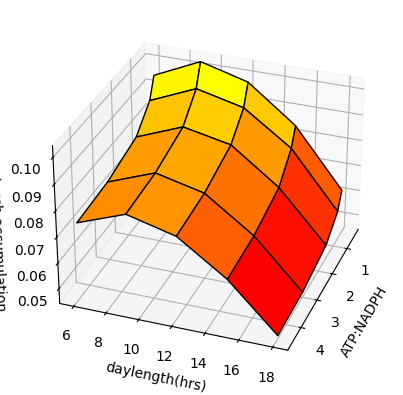

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(df1.columns.astype(float),df1.index)
z = df1.values.astype(float)



fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('ATP:NADPH')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('starch accumulation')

ax.plot_surface(x, y, z, cmap='autumn', edgecolor='black')
ax.view_init(elev=30, azim=20)
plt.show()

In [ ]:
#0.5 :1 is the ATP:NADPH ratio
s1=[0.09470734506621666, 0.09933677281393946, 0.10202506193185167, 0.10304272624413881, 0.10261204651323216, 0.10091737726022297, 0.09811291740590479, 0.09432864478694857, 0.08967490087235352, 0.08424597161728227, 0.07812291150727926, 0.07057780473166385, 0.061867157987095155]

#0.75 :1 is the ATP:NADPH ratio
s2=[0.08682477851255915, 0.09110564129091345, 0.0936128469204467, 0.09459349027287595, 0.09425061399060983, 0.09275262147010244, 0.09024037379909289, 0.08683260943249238, 0.08263013166306295, 0.07754272494642274, 0.07091144194262011, 0.06356931986910028, 0.05563997361004542]

#1.5 :1 is the ATP:NADPH ratio
s3=[0.07894221195895684, 0.08287450976788915, 0.08520063190882558, 0.08614425430201667, 0.085889181467643, 0.08458786570833865, 0.08236783019244509, 0.07890439145594987, 0.07433061789258491, 0.0689720201783456, 0.06299030584484107, 0.056452108454078526, 0.049412789232752975]

#3 :1 is the ATP:NADPH ratio
s4=[0.0750009286821615, 0.07875894400637037, 0.08099452440385593, 0.08191963631616687, 0.08170846520620957, 0.0802526257320844, 0.07754705848303596, 0.0739582758349368, 0.06961076119137012, 0.06460572542659351, 0.05901316169213044, 0.05289350274605893, 0.04606755859516038]

#4.5 :1 is the ATP:NADPH ratio
s5=[0.07368716758991375, 0.07738708875249238, 0.07959248856874424, 0.08051143032084127, 0.08016998152902342, 0.0784594965439203, 0.07579304884058842, 0.07227744879604389, 0.06803652714196197, 0.06315029384434893, 0.05768744697510722, 0.05124726695485656, 0.04526653314641294]

#6 :1 is the ATP:NADPH ratio
s6=[0.07303028704378225, 0.07670116112560017, 0.07889147065109764, 0.07980732732329944, 0.07924515914243023, 0.07756293194992381, 0.07490619754411189, 0.07143703527618238, 0.06724941012000743, 0.062422578052582944, 0.057024589615702184, 0.050666694097157024, 0.04486602042184028]




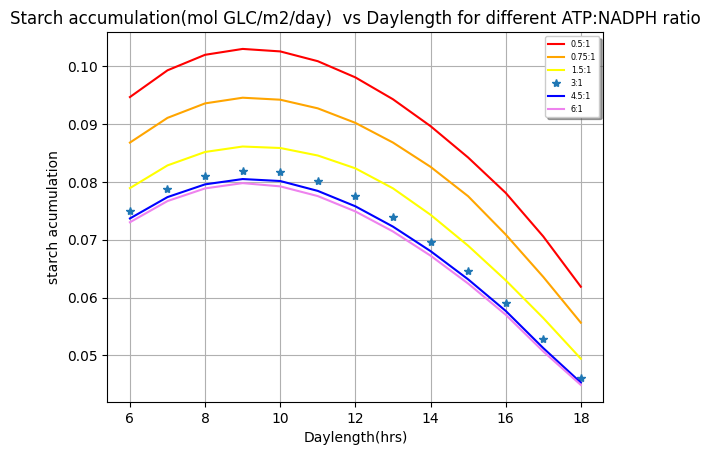

In [ ]:
import matplotlib.pyplot as plt

fig, ax=plt.subplots()
ax.plot(dL,s1,'red',label='0.5:1')
ax.plot(dL,s2,'orange',label='0.75:1')
ax.plot(dL,s3,'yellow',label='1.5:1')
ax.plot(dL,s4,'*',label='3:1')
ax.plot(dL,s5,'blue',label='4.5:1')
ax.plot(dL,s6,'violet',label='6:1')




legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch accumulation(mol GLC/m2/day)  vs Daylength for different ATP:NADPH ratio')

plt.grid()
plt.show()

Keeping ATP:NADPH (Light) 3:1 fixed, ATP:NADPH (NIGHT) ratios varying , with ATP day-night ratios 1:1

In [ ]:
def AtpNADPH(orggg_model,m):
  orgg_model=orggg_model.copy()

  NGAM_constraint=orgg_model.problem.Constraint(3*(orgg_model.reactions.NADPHoxc_tx_Light.flux_expression+orgg_model.reactions.NADPHoxm_tx_Light.flux_expression+orgg_model.reactions.NADPHoxp_tx_Light.flux_expression)-orgg_model.reactions.ATPase_tx_Light.flux_expression,
                                                  lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint)
  NGAM_constraint2=orgg_model.problem.Constraint(m*(orgg_model.reactions.NADPHoxc_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxm_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxp_tx_Dark.flux_expression)-orgg_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint2)
  from cobra.flux_analysis import pfba
  pfba(orgg_model)
  #Setting photosythetically active photon flux intensity
  starchacc=[]
  starchdeg=[]
  for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((1*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)
      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-3*(daylength),phloem_transport_Dark:-1*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
      Constraint1=org_model.problem.Constraint((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression-3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression,lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)

      nitrateflux=org_model.problem.Constraint((2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression),
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)
      atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(daylength*org_model.reactions.ATPase_tx_Dark.flux_expression),
                                            lb=0,ub=0)
      org_model.add_cons_vars(atpdaynightconstraint)
      #NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression))-(daylength*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
      #                                                 lb=0,ub=0)
      #org_model.add_cons_vars(NADPHdaynightconstraint)
      from cobra.flux_analysis import pfba
      pfba(org_model)

      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day


      # Starch degradation reactions is identified
      #StarchDegNight1 = org_model.reactions.get_by_id("RXN_1827_p_Dark")
      #StarchDegNight2 = org_model.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
      #StarchDegNight3 = org_model.reactions.get_by_id("RXN_1826_p_Dark")

      # Number of moles of starch (GLC units) generated by the reactions is noted
      #StarchNight1Stoich =  StarchDegNight1.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
      #StarchNight2Stoich =  StarchDegNight2.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
      #StarchNight3Stoich =  StarchDegNight3.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]


      #starchdeg.append(abs((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich)))
  print(starchacc)
  #print(org_model.reactions.AraCore_Biomass_tx_Light.flux,"\t",org_model.reactions.AraCore_Biomass_tx_Dark.flux)

In [ ]:
for m in [0.5,0.75,1.5,3,4.5,6]:
  AtpNADPH(C3_dup_model,m)

[0.09801090278664296, 0.10280800740820735, 0.10559726086942924, 0.10665846062103211, 0.10622151664230699, 0.10447711168826024, 0.10158473856594917, 0.09767883788350079, 0.09287354030518359, 0.08726637005921141, 0.08094116588564369, 0.07294018998248297, 0.06391639170373224]
[0.08880691314490763, 0.09318838204705321, 0.09575616628319773, 0.09676293089913902, 0.09641629606791029, 0.09488846214393312, 0.09232346649511548, 0.088842725291153, 0.08454931532257222, 0.07926765866919898, 0.07248948939865214, 0.06497495988838811, 0.05686951383982084]
[0.0796029235030507, 0.08356875668679774, 0.08591507169694919, 0.08686740117715486, 0.08661107549362702, 0.0852998125994642, 0.0830621944244404, 0.07956138650181428, 0.07494945764559105, 0.06954505040303842, 0.06351340003839437, 0.05692065512671191, 0.04982263597560335]
[0.07500092868212209, 0.07875894400632359, 0.08099452440389726, 0.08191963631614273, 0.08170846520643678, 0.08025262573205763, 0.07754705848307274, 0.07395827583480244, 0.069610761191

In [ ]:
d1=[0.09801090278664296, 0.10280800740820735, 0.10559726086942924, 0.10665846062103211, 0.10622151664230699, 0.10447711168826024, 0.10158473856594917, 0.09767883788350079, 0.09287354030518359, 0.08726637005921141, 0.08094116588564369, 0.07294018998248297, 0.06391639170373224]
d2=[0.08880691314490763, 0.09318838204705321, 0.09575616628319773, 0.09676293089913902, 0.09641629606791029, 0.09488846214393312, 0.09232346649511548, 0.088842725291153, 0.08454931532257222, 0.07926765866919898, 0.07248948939865214, 0.06497495988838811, 0.05686951383982084]
d3=[0.0796029235030507, 0.08356875668679774, 0.08591507169694919, 0.08686740117715486, 0.08661107549362702, 0.0852998125994642, 0.0830621944244404, 0.07956138650181428, 0.07494945764559105, 0.06954505040303842, 0.06351340003839437, 0.05692065512671191, 0.04982263597560335]
d4=[0.07500092868212209, 0.07875894400632359, 0.08099452440389726, 0.08191963631614273, 0.08170846520643678, 0.08025262573205763, 0.07754705848307274, 0.07395827583480244, 0.06961076119106013, 0.0646057254277585, 0.05901316169167776, 0.05289350274634901, 0.04606755859490058]
d5=[0.07346693040851535, 0.0771556731129217, 0.07935434197284855, 0.0802703813623886, 0.07992680536243353, 0.07822174965393912, 0.07556323420375628, 0.07205849273689637, 0.06783058521117373, 0.06295928376921364, 0.057513082242911594, 0.05108664586386159, 0.04513139880441169]
d6=[0.07269993127172, 0.07635403766619248, 0.07853425075728725, 0.07944575388560222, 0.078880394892426, 0.07720631161463101, 0.07456147558898242, 0.07110860116835828, 0.06694049722119602, 0.06213606293983728, 0.056763042519070654, 0.050437992992421216, 0.04466331890950268]


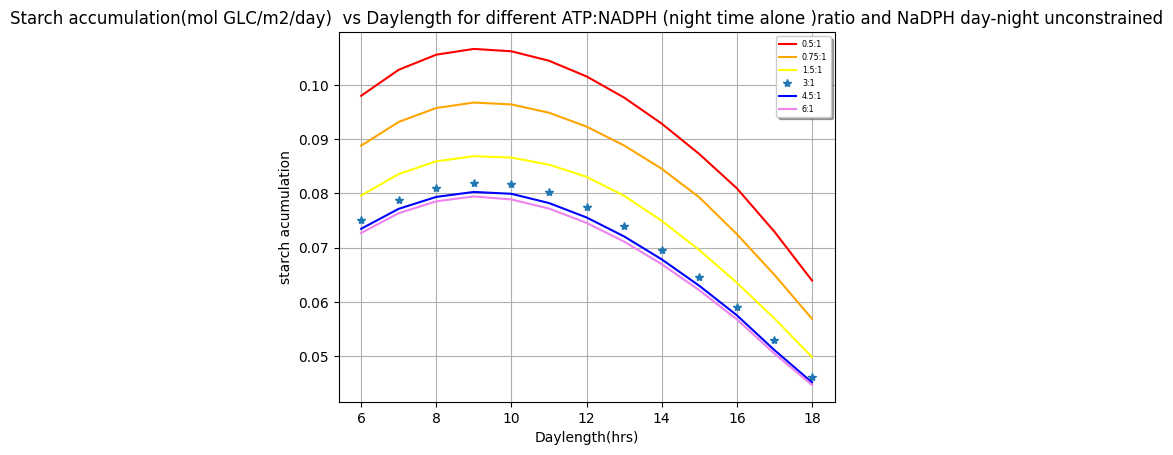

In [ ]:
import matplotlib.pyplot as plt
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]
fig, ax=plt.subplots()
ax.plot(dL,d1,'red',label='0.5:1')
ax.plot(dL,d2,'orange',label='0.75:1')
ax.plot(dL,d3,'yellow',label='1.5:1')
ax.plot(dL,d4,'*',label='3:1')
ax.plot(dL,d5,'blue',label='4.5:1')
ax.plot(dL,d6,'violet',label='6:1')




legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch accumulation(mol GLC/m2/day)  vs Daylength for different ATP:NADPH (night time alone )ratio and NaDPH day-night unconstrained')

plt.grid()
plt.show()

In [ ]:
def AtpNADPH(orggg_model,m):
  orgg_model=orggg_model.copy()

  NGAM_constraint=orgg_model.problem.Constraint(3*(orgg_model.reactions.NADPHoxc_tx_Light.flux_expression+orgg_model.reactions.NADPHoxm_tx_Light.flux_expression+orgg_model.reactions.NADPHoxp_tx_Light.flux_expression)-orgg_model.reactions.ATPase_tx_Light.flux_expression,
                                                  lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint)
  NGAM_constraint2=orgg_model.problem.Constraint(m*(orgg_model.reactions.NADPHoxc_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxm_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxp_tx_Dark.flux_expression)-orgg_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint2)
  from cobra.flux_analysis import pfba
  pfba(orgg_model)
  #Setting photosythetically active photon flux intensity
  starchacc=[]
  starchdeg=[]
  for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((1*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)
      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-3*(daylength),phloem_transport_Dark:-1*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
      Constraint1=org_model.problem.Constraint((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression-3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression,lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)

      nitrateflux=org_model.problem.Constraint((2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression),
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)
      # atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(daylength*org_model.reactions.ATPase_tx_Dark.flux_expression),
      #                                       lb=0,ub=0)
      # org_model.add_cons_vars(atpdaynightconstraint)
      NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression))-(daylength*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
                                                       lb=0,ub=0)
      org_model.add_cons_vars(NADPHdaynightconstraint)
      from cobra.flux_analysis import pfba
      pfba(org_model)

      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day


      # Starch degradation reactions is identified
      #StarchDegNight1 = org_model.reactions.get_by_id("RXN_1827_p_Dark")
      #StarchDegNight2 = org_model.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
      #StarchDegNight3 = org_model.reactions.get_by_id("RXN_1826_p_Dark")

      # Number of moles of starch (GLC units) generated by the reactions is noted
      #StarchNight1Stoich =  StarchDegNight1.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
      #StarchNight2Stoich =  StarchDegNight2.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
      #StarchNight3Stoich =  StarchDegNight3.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]


      #starchdeg.append(abs((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich)))
  print(starchacc)
  #print(org_model.reactions.AraCore_Biomass_tx_Light.flux,"\t",org_model.reactions.AraCore_Biomass_tx_Dark.flux)

In [ ]:
for m in [0.5,0.75,1.5,3,4.5,6]:
  AtpNADPH(C3_dup_model,m)

[0.07157682539280812, 0.07518021433349144, 0.07733340290601787, 0.0782382636516596, 0.0780606896948712, 0.0769382818956569, 0.07498614467213076, 0.07188920929730591, 0.06769940072657882, 0.06279442027721459, 0.05732130064874099, 0.051346435521504766, 0.04331350256462494]
[0.07191923572175798, 0.07553808730071224, 0.07769951505577402, 0.07860640091809674, 0.07842546724603945, 0.07729500248878898, 0.07533068604328326, 0.07210172141610778, 0.06789850812130246, 0.06297555079214442, 0.05749048675187963, 0.051501142244066114, 0.045057703092282006]
[0.07294646670856143, 0.07661170620269936, 0.07879785150511308, 0.07971081271743148, 0.07951979989947247, 0.07836516426845205, 0.07624770662174118, 0.0727392577732267, 0.06846925914402145, 0.06351894233745542, 0.057998045066068045, 0.05196526241204301, 0.04547153440626281]
[0.07500092868213931, 0.07875894400650396, 0.08099452440397523, 0.08191963631611315, 0.08170846520628512, 0.08025262573162112, 0.07754705848323779, 0.07395827583547844, 0.0696107

In [ ]:
e1=[0.07157682539280812, 0.07518021433349144, 0.07733340290601787, 0.0782382636516596, 0.0780606896948712, 0.0769382818956569, 0.07498614467213076, 0.07188920929730591, 0.06769940072657882, 0.06279442027721459, 0.05732130064874099, 0.051346435521504766, 0.04331350256462494]
e2=[0.07191923572175798, 0.07553808730071224, 0.07769951505577402, 0.07860640091809674, 0.07842546724603945, 0.07729500248878898, 0.07533068604328326, 0.07210172141610778, 0.06789850812130246, 0.06297555079214442, 0.05749048675187963, 0.051501142244066114, 0.045057703092282006]
e3=[0.07294646670856143, 0.07661170620269936, 0.07879785150511308, 0.07971081271743148, 0.07951979989947247, 0.07836516426845205, 0.07624770662174118, 0.0727392577732267, 0.06846925914402145, 0.06351894233745542, 0.057998045066068045, 0.05196526241204301, 0.04547153440626281]
e4=[0.07500092868213931, 0.07875894400650396, 0.08099452440397523, 0.08191963631611315, 0.08170846520628512, 0.08025262573162112, 0.07754705848323779, 0.07395827583547844, 0.0696107611903983, 0.06460572542740776, 0.05901316169199501, 0.052893502745544295, 0.04606755859524212]
e5=[0.0770553906557486, 0.08090618181015091, 0.0831911973026382, 0.08393180166774002, 0.08329295776450078, 0.08152280330746571, 0.07875846935011345, 0.07513553716296704, 0.07075226323665205, 0.06569250851836275, 0.0600282783183799, 0.0535113833890749, 0.047359803704441525]
e6=[0.07782349212601541, 0.08214534245072774, 0.08436494412867106, 0.08506769005915686, 0.08445791807884634, 0.08270493041608658, 0.0799501872670494, 0.07631279848996952, 0.07189376528341755, 0.0662013555331667, 0.06085080113999951, 0.05498425418637778, 0.04865204881304691]


In [ ]:
for m in [e1,e2,e3,e4,e5,e6]:
 print(m.index(max(m))+6)

9
9
9
9
9
9


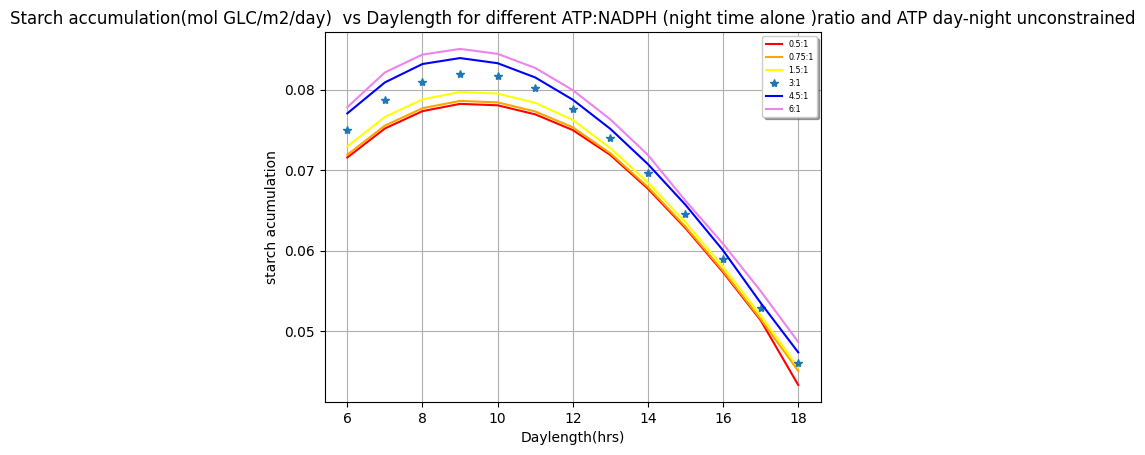

In [ ]:
import matplotlib.pyplot as plt
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]
fig, ax=plt.subplots()
ax.plot(dL,e1,'red',label='0.5:1')
ax.plot(dL,e2,'orange',label='0.75:1')
ax.plot(dL,e3,'yellow',label='1.5:1')
ax.plot(dL,e4,'*',label='3:1')
ax.plot(dL,e5,'blue',label='4.5:1')
ax.plot(dL,e6,'violet',label='6:1')




legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch accumulation(mol GLC/m2/day)  vs Daylength for different ATP:NADPH (night time alone )ratio and ATP day-night unconstrained')

plt.grid()
plt.show()

Attaching phloem export rates

In [ ]:
#To be deleted
def AtpNADPH(orggg_model,m):
  orgg_model=orggg_model.copy()

  NGAM_constraint=orgg_model.problem.Constraint(m*(orgg_model.reactions.NADPHoxc_tx_Light.flux_expression+orgg_model.reactions.NADPHoxm_tx_Light.flux_expression+orgg_model.reactions.NADPHoxp_tx_Light.flux_expression)-orgg_model.reactions.ATPase_tx_Light.flux_expression,
                                                  lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint)
  NGAM_constraint2=orgg_model.problem.Constraint(m*(orgg_model.reactions.NADPHoxc_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxm_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxp_tx_Dark.flux_expression)-orgg_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint2)
  from cobra.flux_analysis import pfba
  pfba(orgg_model)
  #Setting photosythetically active photon flux intensity
  perLight3=[]
  starchacc=[]

  for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((1*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)
      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-3*(daylength),phloem_transport_Dark:-1*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
      Constraint1=org_model.problem.Constraint((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression-3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression,lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)

      nitrateflux=org_model.problem.Constraint((2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression),
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)
      atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(daylength*org_model.reactions.ATPase_tx_Dark.flux_expression),
                                            lb=0,ub=0)
      org_model.add_cons_vars(atpdaynightconstraint)
      NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression))-(daylength*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
                                                      lb=0,ub=0)
      org_model.add_cons_vars(NADPHdaynightconstraint)
      from cobra.flux_analysis import pfba
      pfba(org_model)
      Phloem_exp= org_model.reactions.get_by_id("diel_biomass")
      Phloem_expStoich=Phloem_exp.metabolites[org_model.metabolites.get_by_id("phloem_transport_Dark")]
      phloemexrate.append(Phloem_exp.flux*Phloem_expStoich)
      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day

  print(starchacc)
  print(phloemexrate)
  print("##########")
  #print(org_model.reactions.AraCore_Biomass_tx_Light.flux,"\t",org_model.reactions.AraCore_Biomass_tx_Dark.flux)

In [ ]:
#To be deleted
for m in [0.5,0.75,1.5,3,4.5,6]:
  AtpNADPH(C3_dup_model,m)

[0.0947073450661779, 0.09933677281394919, 0.1020250619319617, 0.10304272624409865, 0.10261204651315015, 0.10091737723193493, 0.09811291740602396, 0.09432864478559663, 0.08967490087230665, 0.08424597161761416, 0.07812291151936084, 0.07057780473265023, 0.0618671579864444]
[-0.01628232839732096, -0.020831425461821783, -0.024236910647032685, -0.026658875456810442, -0.028228819495600334, -0.029055764008272835, -0.029230860806482024, -0.02883091161076575, -0.027921086958889552, -0.02655704933526986, -0.02478662747998037, -0.022650924747172646, -0.020185996987133005]
##########
[0.08682477851258497, 0.09110564129092913, 0.09361284692072436, 0.09459349027290101, 0.0942506139904701, 0.09275262147006841, 0.0902403737990752, 0.08683260943233645, 0.08263013166295419, 0.07754272494599622, 0.07091144194278111, 0.06356931986970941, 0.055639973610179146]
[-0.022584148297000187, -0.026311337096429747, -0.028993925266119654, -0.03077812697341632, -0.03178404405207627, -0.03211124927012941, -0.0318429954

In [ ]:
s1=[0.0947073450661779, 0.09933677281394919, 0.1020250619319617, 0.10304272624409865, 0.10261204651315015, 0.10091737723193493, 0.09811291740602396, 0.09432864478559663, 0.08967490087230665, 0.08424597161761416, 0.07812291151936084, 0.07057780473265023, 0.0618671579864444]
e1=[-0.01628232839732096, -0.020831425461821783, -0.024236910647032685, -0.026658875456810442, -0.028228819495600334, -0.029055764008272835, -0.029230860806482024, -0.02883091161076575, -0.027921086958889552, -0.02655704933526986, -0.02478662747998037, -0.022650924747172646, -0.020185996987133005]
##########
s2=[0.08682477851258497, 0.09110564129092913, 0.09361284692072436, 0.09459349027290101, 0.0942506139904701, 0.09275262147006841, 0.0902403737990752, 0.08683260943233645, 0.08263013166295419, 0.07754272494599622, 0.07091144194278111, 0.06356931986970941, 0.055639973610179146]
e2=[-0.022584148297000187, -0.026311337096429747, -0.028993925266119654, -0.03077812697341632, -0.03178404405207627, -0.03211124927012941, -0.031842995498894765, -0.031049429810563592, -0.029790076572563662, -0.02811570815230659, -0.026069796277024052, -0.0236904433121034, -0.021010461571019424]
##########
s3=[0.0789422119589845, 0.08287450976792253, 0.08520063190944491, 0.0861442543016664, 0.08588918146760707, 0.08458786570829352, 0.0823678301923764, 0.07890439145575431, 0.07433061789272616, 0.06897202017794068, 0.06299030584538562, 0.05645210845414347, 0.04941278923294648]
e3=[-0.028885968196678942, -0.031791248731036795, -0.03375093988520671, -0.03489737849002215, -0.03533926860855076, -0.03516673453198652, -0.034455130191308046, -0.03326772745469962, -0.031658505996769316, -0.029673643843656457, -0.02735272936271277, -0.02472993134744765, -0.021834926154905572]
##########
s4=[0.07500092868212209, 0.07875894400632359, 0.08099452440389726, 0.08191963631614273, 0.08170846520643678, 0.08025262573205763, 0.07754705848307274, 0.07395827583480244, 0.06961076119106013, 0.0646057254277585, 0.05901316169167776, 0.05289350274634901, 0.04606755859490058]
e4=[-0.03203687814651847, -0.03453120454834045, -0.03612944719475065, -0.03695700424832529, -0.03711688088678933, -0.03669431169800848, -0.035760685047978524, -0.03437637512954155, -0.03259246618382923, -0.03045258034645782, -0.027994190399904938, -0.0252496753651197, -0.022246280316874523]
##########
s5=[0.07368716758989591, 0.07738708875254037, 0.07959248856868718, 0.08051143032086576, 0.08016998152914304, 0.07845949654396485, 0.07579304884031102, 0.07227744879566815, 0.06803652714204078, 0.06315029384422699, 0.05768744697446271, 0.05124726695500503, 0.045266533146233086]
e5=[-0.03308718146313157, -0.035444523154108426, -0.03692228296459858, -0.037643546167759376, -0.037709311660321494, -0.03720327633436647, -0.036195784777013115, -0.03474590796176124, -0.032903785822726024, -0.03071222584739097, -0.028208010745636437, -0.02542279419700428, -0.022382969052627582]
##########
s6=[0.0730302870438178, 0.07670116112562836, 0.07889147065137624, 0.07980732732329038, 0.07924515914245808, 0.0775629319506687, 0.07490619754417248, 0.07143703527598923, 0.06724941011745093, 0.062422578052372814, 0.05702458961556111, 0.050666694097243996, 0.04486602042189]
e6=[-0.033612333121438485, -0.035901182456992316, -0.03731870084952427, -0.0379868171274768, -0.03800541254236407, -0.03745775865254673, -0.036413328936367985, -0.0349306743778713, -0.033059445642174536, -0.030842048597857687, -0.028314920918501775, -0.02550899207246881, -0.022451313420503896]
##########


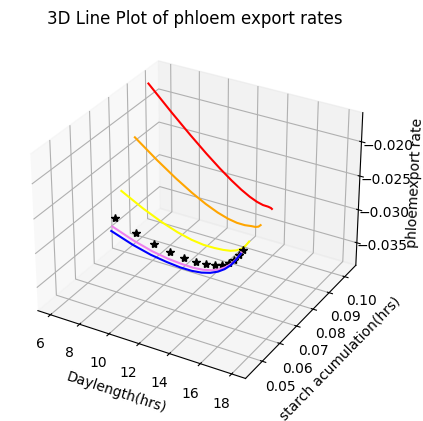

In [ ]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]
fig = plt.figure()
ax = plt.axes(projection='3d')

z1 = e1
x1 =dL
y1 = s1

ax.plot3D(x1, y1, z1, 'red')
z2 = e2
x2 =dL
y2 = s2

ax.plot3D(x2, y2, z2, 'orange')
z3 = e3
x3 =dL
y3 = s3

ax.plot3D(x3, y3, z3, 'yellow')
z4 = e4
x4 =dL
y4 = s4

ax.plot3D(x4, y4, z4, 'k*')

z5 = e5
x5 =dL
y5 = s5

ax.plot3D(x5, y5, z5, 'violet')
z6 = e6
x6 =dL
y6 = s6

ax.plot3D(x6, y6, z6, 'blue')

ax.set_title('3D Line Plot of phloem export rates')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation(hrs)')
ax.set_zlabel('phloemexport rate')
plt.show()

In [ ]:
def AtpDN(orggg_model,h):
  orgg_model=orggg_model.copy()
  NGAM_constraint=orgg_model.problem.Constraint(3*(orgg_model.reactions.NADPHoxc_tx_Light.flux_expression+orgg_model.reactions.NADPHoxm_tx_Light.flux_expression+orgg_model.reactions.NADPHoxp_tx_Light.flux_expression)-orgg_model.reactions.ATPase_tx_Light.flux_expression,
                                                lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint)
      #Night
  NGAM_constraint2=orgg_model.problem.Constraint(3*(orgg_model.reactions.NADPHoxc_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxm_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxp_tx_Dark.flux_expression)-orgg_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint2)
  from cobra.flux_analysis import pfba
  pfba(orgg_model)
  #Setting photosythetically active photon flux intensity
  starchacc=[]
  for daylength in [6,9,12,15,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((1*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)

      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-3*(daylength),phloem_transport_Dark:-1*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
      Constraint1=org_model.problem.Constraint((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression-3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression,lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)
      atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(h*(daylength)*(org_model.reactions.ATPase_tx_Dark.flux_expression)),
                                              lb=0,ub=0)
      org_model.add_cons_vars(atpdaynightconstraint)
      NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression))-(h*(daylength)*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
                                                        lb=0,ub=0)
      org_model.add_cons_vars(NADPHdaynightconstraint)

      nitrateflux=org_model.problem.Constraint(2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression-3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression,
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)

      from cobra.flux_analysis import pfba
      pfba(org_model)

      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day


  #     # Starch degradation reactions is identified
  #     StarchDegNight1 = org_model.reactions.get_by_id("RXN_1827_p_Dark")
  #     StarchDegNight2 = org_model.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
  #     StarchDegNight3 = org_model.reactions.get_by_id("RXN_1826_p_Dark")

  #     # Number of moles of starch (GLC units) generated by the reactions is noted
  #     StarchNight1Stoich =  StarchDegNight1.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
  #     StarchNight2Stoich =  StarchDegNight2.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
  #     StarchNight3Stoich =  StarchDegNight3.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]


  #     starchdeg.append(abs((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich)))

   print(starchacc)
  print(org_model.reactions.AraCore_Biomass_tx_Light.flux,"\t",org_model.reactions.AraCore_Biomass_tx_Dark.flux)
  #print(starchdeg)

In [ ]:
for m in [0.25,0.3,0.5,1,2]:
  print(m,":1 is the  Day:Night ratio of ATP and NADPH")
  AtpDN(C3_dup_model,m)

0.25 :1 is the  Day:Night ratio of ATP and NADPH
[0.10022921231130338, 0.10915071550603198, 0.10274871399876882, 0.08594439889644845, 0.06224646736231095]
0.0 	 0.0
0.3 :1 is the  Day:Night ratio of ATP and NADPH
[0.0948824720382492, 0.10331332764890497, 0.09715272231792542, 0.08120247145847637, 0.05865115430296742]
0.0 	 0.0
0.5 :1 is the  Day:Night ratio of ATP and NADPH
[0.08371184745031668, 0.09128504837436685, 0.08596073895505643, 0.07171861658297031, 0.05146052818417453]
0.0 	 0.0
1 :1 is the  Day:Night ratio of ATP and NADPH
[0.0750009286821615, 0.08191963631616997, 0.07754705848289856, 0.06460572542659351, 0.04606755859516038]
0.0 	 0.0
2 :1 is the  Day:Night ratio of ATP and NADPH
[0.07064546929810088, 0.07723693028687242, 0.0733244855288693, 0.06104927984942984, 0.04337107380063898]
0.0 	 0.0


In [ ]:
#0.25 :1 is the  Day:Night ratio of ATP and NADPH
d1=[0.10022921231130338, 0.10915071550603198, 0.10274871399876882, 0.08594439889644845, 0.06224646736231095]

#0.3 :1 is the  Day:Night ratio of ATP and NADPH
d2=[0.0948824720382492, 0.10331332764890497, 0.09715272231792542, 0.08120247145847637, 0.05865115430296742]

#0.5 :1 is the  Day:Night ratio of ATP and NADPH
d3=[0.08371184745031668, 0.09128504837436685, 0.08596073895505643, 0.07171861658297031, 0.05146052818417453]

#1 :1 is the  Day:Night ratio of ATP and NADPH
d4=[0.0750009286821615, 0.08191963631616997, 0.07754705848289856, 0.06460572542659351, 0.04606755859516038]

#2 :1 is the  Day:Night ratio of ATP and NADPH
d5=[0.07064546929810088, 0.07723693028687242, 0.0733244855288693, 0.06104927984942984, 0.04337107380063898]



In [ ]:
import pandas as pd
import numpy as np
atpdn={"daylength":dL,"0.25":d1,"0.3":d2,"0.5":d3,"1":d4,"2":d5}
df2=pd.DataFrame(atpdn)
print(df2)
df2 = df2.set_index("daylength")

   daylength      0.25       0.3       0.5         1         2
0          6  0.100229  0.094882  0.083712  0.075001  0.070645
1          9  0.109151  0.103313  0.091285  0.081920  0.077237
2         12  0.102749  0.097153  0.085961  0.077547  0.073324
3         15  0.085944  0.081202  0.071719  0.064606  0.061049
4         18  0.062246  0.058651  0.051461  0.046068  0.043371


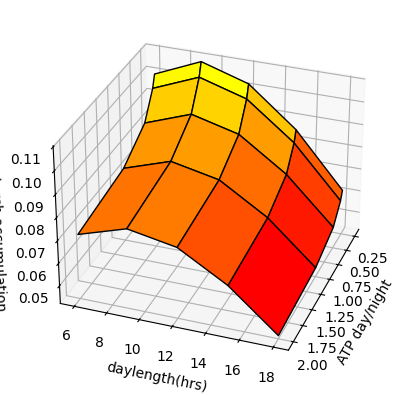

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(df2.columns.astype(float),df2.index)
z = df2.values.astype(float)



fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('ATP day/night')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('starch accumulation')

ax.plot_surface(x, y, z, cmap='autumn', edgecolor='black')
ax.view_init(elev=30, azim=20)
plt.show()

In [ ]:
#0.25 :1 is the  Day:Night ratio of ATP and NADPH
p1=[0.10022921231130338, 0.1049684916719491, 0.10817413354693194, 0.10915071550603198, 0.10843230559055171, 0.10623743769519896, 0.10274871399876882, 0.09811989179949375, 0.09248135728679177, 0.08594439889644845, 0.0781119062947059, 0.07047885497247629, 0.06224646736231095]

#0.3 :1 is the  Day:Night ratio of ATP and NADPH
p2=[0.0948824720382492, 0.09973634933453525, 0.10243666472788703, 0.10331332764890497, 0.10259566274079679, 0.10048260180744954, 0.09715272231792542, 0.09275064380729896, 0.08739900259877692, 0.08120247145847637, 0.07410737599203335, 0.06638100111039417, 0.05865115430296742]

#0.5 :1 is the  Day:Night ratio of ATP and NADPH
p3=[0.08371184745031668, 0.08786323229422222, 0.09030841749432374, 0.09128504837436685, 0.09084475204683064, 0.08894492911606902, 0.08596073895505643, 0.08201214782292515, 0.07723429322333532, 0.07171861658297031, 0.06554363329035988, 0.05841100364732838, 0.05146052818417453]

#1 :1 is the  Day:Night ratio of ATP and NADPH
p4=[0.0750009286821615, 0.07875894400642983, 0.0809945244038472, 0.08191963631616997, 0.08170846520614855, 0.0802526257319768, 0.07754705848289856, 0.0739582758349368, 0.06961076119137012, 0.06460572542659351, 0.05901316169213044, 0.0528935027463499, 0.04606755859516038]

#2 :1 is the  Day:Night ratio of ATP and NADPH
p5=[0.07064546929810088, 0.0742067998623876, 0.07633757785864702, 0.07723693028687242, 0.07706849475602343, 0.07590647403992455, 0.0733244855288693, 0.06993133984149764, 0.065798995174508, 0.06104927984942984, 0.05574792589346199, 0.04995168622100949, 0.04337107380063898]

#3 :1 is the  Day:Night ratio of ATP and NADPH
p6=[0.06919364950343043, 0.07268941848120943, 0.07478526234330543, 0.07567602827718335, 0.07552183793911027, 0.07445550656737875, 0.07191696121068365, 0.06858902784363892, 0.06452840650272515, 0.059863797989710074, 0.05465951396022591, 0.04897108071237256, 0.04247224553559585]

#4 :1 is the  Day:Night ratio of ATP and NADPH
p7=[0.06846773960608549, 0.07193072779045215, 0.07400910458596482, 0.07489557727251973, 0.07474850953031255, 0.07369925890979981, 0.07121319905170276, 0.0679178718443379, 0.06389311216695932, 0.059271057060575026, 0.0541153079940068, 0.048480777958419236, 0.04202283140293468]

#5 :1 is the  Day:Night ratio of ATP and NADPH
p8=[0.06803219366817989, 0.07147551337425481, 0.07354340993138361, 0.07442730666947515, 0.07428451248577247, 0.07324551031545648, 0.07079094175651937, 0.0675151782448716, 0.06351193556496973, 0.05891541250266346, 0.05378878441336859, 0.04818659630639765, 0.041366149318633486]



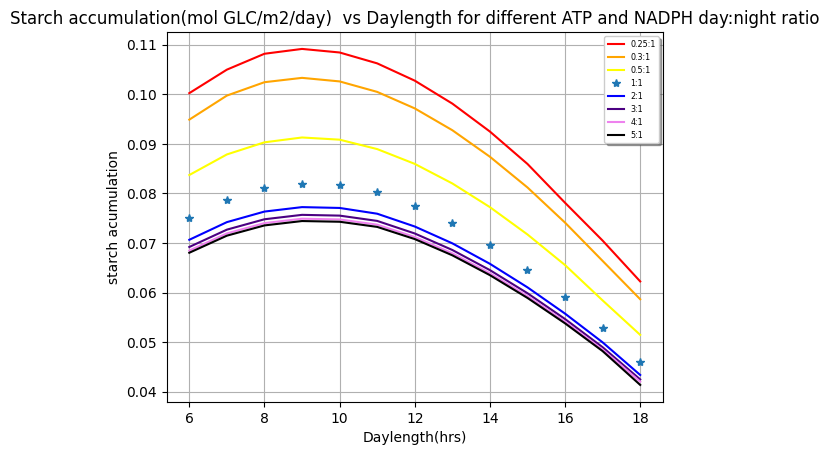

In [ ]:
import matplotlib.pyplot as plt

fig, ax=plt.subplots()
ax.plot(dL,p1,'red',label='0.25:1')
ax.plot(dL,p2,'orange',label='0.3:1')
ax.plot(dL,p3,'yellow',label='0.5:1')
ax.plot(dL,p4,'*',label='1:1')
ax.plot(dL,p5,'blue',label='2:1')
ax.plot(dL,p6,'indigo',label='3:1')
ax.plot(dL,p7,'violet',label='4:1')
ax.plot(dL,p8,'black',label='5:1')



legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch accumulation(mol GLC/m2/day)  vs Daylength for different ATP and NADPH day:night ratio')

plt.grid()
plt.show()

In [ ]:
def MNC(orggg_model,n):
  orgg_model=orggg_model.copy()

  #Setting photosythetically active photon flux intensity
  starchacc=[]
  starchdeg=[]
  for daylength in [6,9,12,15,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((1*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)

      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-3*(daylength),phloem_transport_Dark:-1*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (n*VATPase,n*VATPase)

      Constraint1=org_model.problem.Constraint(((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression)-(3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression),lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)
      nitrateflux=org_model.problem.Constraint((2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression),
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)
      NGAM_constraint=org_model.problem.Constraint(3*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression)-org_model.reactions.ATPase_tx_Light.flux_expression,
                                                lb=0,ub=0)
      org_model.add_cons_vars(NGAM_constraint)
      #Night
      NGAM_constraint2=org_model.problem.Constraint(3*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression)-org_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
      org_model.add_cons_vars(NGAM_constraint2)
      atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(daylength*org_model.reactions.ATPase_tx_Dark.flux_expression),
                                            lb=0,ub=0)
      org_model.add_cons_vars(atpdaynightconstraint)
      NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression))-(daylength*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
                                                        lb=0,ub=0)
      org_model.add_cons_vars(NADPHdaynightconstraint)

      from cobra.flux_analysis import pfba
      pfba(org_model)

      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day


      # Starch degradation reactions is identified
      StarchDegNight1 = org_model.reactions.get_by_id("RXN_1827_p_Dark")
      StarchDegNight2 = org_model.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
      StarchDegNight3 = org_model.reactions.get_by_id("RXN_1826_p_Dark")

      # Number of moles of starch (GLC units) generated by the reactions is noted
      StarchNight1Stoich =  StarchDegNight1.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
      StarchNight2Stoich =  StarchDegNight2.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
      StarchNight3Stoich =  StarchDegNight3.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]


      starchdeg.append(abs((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich)))
  print(starchacc)
  print(org_model.reactions.AraCore_Biomass_tx_Light.flux,"\t",org_model.reactions.AraCore_Biomass_tx_Dark.flux)

In [ ]:
for n in [0,0.5,1,1.5,2]:
  MNC(C3_dup_model,n)

[0.06763356698802786, 0.07402746551793583, 0.07063056249134005, 0.05872079545026773, 0.040619016256505464]
0.0 	 0.0
[0.07130618084225161, 0.07796007716230825, 0.07401322326413788, 0.061622310074713256, 0.043776476824799626]
0.0 	 0.0
[0.07500092868219962, 0.08191963631607203, 0.0775470584830039, 0.06460572542838897, 0.046067558594739516]
0.0 	 0.0
[0.07869567652212206, 0.08587919546983871, 0.08107430128381868, 0.06758914078094874, 0.04835864036539517]
0.0 	 0.0
[0.08239042436212733, 0.0898387546235516, 0.08458185113429403, 0.07057255613290211, 0.05064972213547316]
0.0 	 0.0


In [ ]:
q30=[0.06763356698802786, 0.07402746551793583, 0.07063056249134005, 0.05872079545026773, 0.040619016256505464]

q31=[0.07130618084225161, 0.07796007716230825, 0.07401322326413788, 0.061622310074713256, 0.043776476824799626]

q32=[0.07500092868219962, 0.08191963631607203, 0.0775470584830039, 0.06460572542838897, 0.046067558594739516]

q33=[0.07869567652212206, 0.08587919546983871, 0.08107430128381868, 0.06758914078094874, 0.04835864036539517]

q34=[0.08239042436212733, 0.0898387546235516, 0.08458185113429403, 0.07057255613290211, 0.05064972213547316]

dL=[6,9,12,15,18]


In [ ]:
import pandas as pd
import numpy as np
mnc={"daylength":dL,"0":q30,"0.5":q31,"1":q32,"1.5":q33,"2":q34}
dfM=pd.DataFrame(mnc)
print(dfM)
dfM = dfM.set_index("daylength")

   daylength         0       0.5         1       1.5         2
0          6  0.067634  0.071306  0.075001  0.078696  0.082390
1          9  0.074027  0.077960  0.081920  0.085879  0.089839
2         12  0.070631  0.074013  0.077547  0.081074  0.084582
3         15  0.058721  0.061622  0.064606  0.067589  0.070573
4         18  0.040619  0.043776  0.046068  0.048359  0.050650


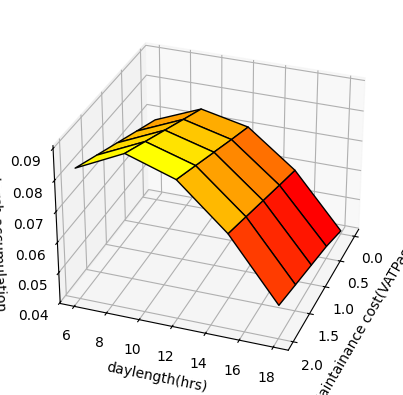

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

x,y = np.meshgrid(dfM.columns.astype(float),dfM.index)
z = dfM.values.astype(float)



fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))

plt.xlabel('Maintainance cost(VATPase)')
plt.ylabel('daylength(hrs)')
ax.set_zlabel('starch accumulation')

ax.plot_surface(x, y, z, cmap='autumn', edgecolor='black')
ax.view_init(elev=30, azim=20)
plt.show()

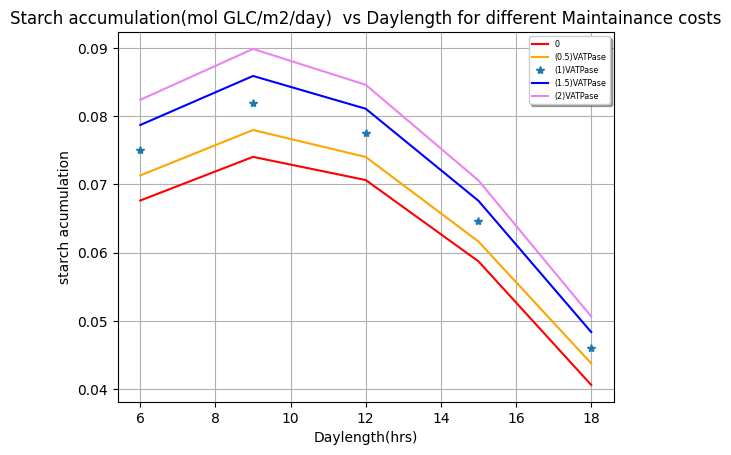

In [ ]:
import matplotlib.pyplot as plt

fig, ax=plt.subplots()
ax.plot(dL,q30,'red',label='0')
ax.plot(dL,q31,'orange',label='(0.5)VATPase')
ax.plot(dL,q32,'*',label='(1)VATPase')
ax.plot(dL,q33,'blue',label='(1.5)VATPase')
ax.plot(dL,q34,'violet',label='(2)VATPase')



legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch accumulation(mol GLC/m2/day)  vs Daylength for different Maintainance costs')

plt.grid()
plt.show()

In [ ]:
q0=[0.06763356698802786, 0.0710678607319944, 0.07313583892335856, 0.07402746551793583, 0.07389887649053306, 0.07287960221026064, 0.07063056249134005, 0.06735944393627599, 0.06333713430757774, 0.05872079545026773, 0.051654257890194885, 0.046266468716014766, 0.040619016256505464]

q12=[0.07130618084225161, 0.07490104678131415, 0.07705201764608414, 0.07796007716230825, 0.07779038878205402, 0.07661971470966134, 0.07401322326413788, 0.07058820805579238, 0.06641682096682569, 0.061622310074713256, 0.056271020086596416, 0.050420232893890214, 0.043776476824799626]

q1=[0.07500092868219962, 0.07875894400638697, 0.08099452440374717, 0.08191963631607203, 0.08170846520693502, 0.08025262573189362, 0.0775470584830039, 0.07395827583519483, 0.06961076118991585, 0.06460572542838897, 0.05901316169184682, 0.05289350274606308, 0.046067558594739516]

q32=[0.07869567652212206, 0.08261684123153042, 0.08493703116174971, 0.08587919546983871, 0.08562654163087317, 0.08388553675409004, 0.08107430128381868, 0.07732834361523219, 0.0728047014139286, 0.06758914078094874, 0.06175530329853065, 0.055366772598465216, 0.04835864036539517]

q2=[0.08239042436212733, 0.0864747384565365, 0.08887953791939353, 0.0898387546235516, 0.08938569504742519, 0.08751844777640402, 0.08458185113429403, 0.08069841139495103, 0.07599864163816027, 0.07057255613290211, 0.06449744490472609, 0.057447277101759675, 0.05064972213547316]



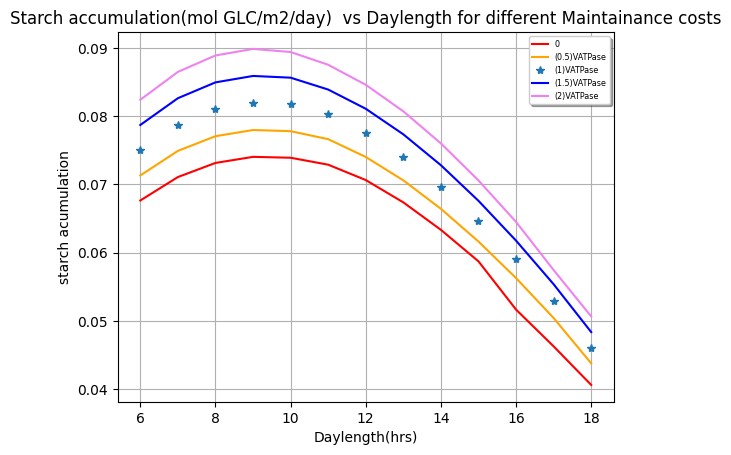

In [ ]:
import matplotlib.pyplot as plt

fig, ax=plt.subplots()
ax.plot(dL,q0,'red',label='0')
ax.plot(dL,q12,'orange',label='(0.5)VATPase')
ax.plot(dL,q1,'*',label='(1)VATPase')
ax.plot(dL,q32,'blue',label='(1.5)VATPase')
ax.plot(dL,q2,'violet',label='(2)VATPase')



legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation')
plt.title('Starch accumulation(mol GLC/m2/day)  vs Daylength for different Maintainance costs')

plt.grid()
plt.show()

With phloem export rates

In [ ]:
!pip install cobra --quiet
from cobra.io import read_sbml_model
plant_model=read_sbml_model('PlantCoreMetabolism_v2_1_0.xml')

In [ ]:
backup=plant_model.copy()#This one is unmodified throughout the code
plant_model1=plant_model.copy()
plant_model2=plant_model.copy()
#Renaming all reactions
for rxn in plant_model1.reactions:
  rxn.id=rxn.id+"_Light"
  print(rxn.id)#just to see the change
for rxn in plant_model2.reactions:
  rxn.id=rxn.id+"_Dark"
  print(rxn.id)

#Renaming all metabolites
for met in plant_model1.metabolites:
  met.id=met.id+"_Light"
  print(met.id)
for met in plant_model2.metabolites:
  met.id=met.id+"_Dark"
  print(met.id)

  #Renaming compartments
for i in plant_model1.metabolites:
   if i.compartment==i.compartment +"_Light":
    break
   else:
    i.compartment=i.compartment+"_Light"
    print(i.compartment)
for j in plant_model2.metabolites:
   if j.compartment==j.compartment +"_Dark":
    break
   else:
    j.compartment=j.compartment+"_Dark"
    print(j.compartment)
C3_dup_model=plant_model1.merge(plant_model2)
from cobra import Reaction#The reason why most diel transfer reactions are in v(vacuole) because in plants accumulation of metabolites happen in vacuoles(cover 90% of plant cell)
r1=Reaction('GLY_v_dielTransfer')
r1.name='GLY_v_dielTransfer'
r1.lower_bound=0
r1.upper_bound=1000
r1.add_metabolites({C3_dup_model.metabolites.get_by_id("GLY_v_Light"):-1,C3_dup_model.metabolites.get_by_id("GLY_v_Dark"): 1})
C3_dup_model.add_reactions([r1])

r2=Reaction('ILE_v_dielTransfer')
r2.name='ILE_v_diel_Transfer'
r2.lower_bound=0
r2.upper_bound=1000
r2.add_metabolites({C3_dup_model.metabolites.get_by_id("ILE_v_Light"):-1,C3_dup_model.metabolites.get_by_id("ILE_v_Dark"):1})
C3_dup_model.add_reactions([r2])

r3=Reaction('ARG_v_dielTransfer')
r3.name='ARG_v_dielTransfer'
r3.lower_bound=0
r3.upper_bound=1000
r3.add_metabolites({C3_dup_model.metabolites.get_by_id("ARG_v_Light"):-1,C3_dup_model.metabolites.get_by_id("ARG_v_Dark"):1})
C3_dup_model.add_reactions([r3])

r4=Reaction('THR_v_dielTransfer')
r4.name='THR_v_dielTransfer'
r4.lower_bound=0
r4.upper_bound=1000
r4.add_metabolites({C3_dup_model.metabolites.get_by_id("THR_v_Light"):-1,C3_dup_model.metabolites.get_by_id("THR_v_Dark"):1})
C3_dup_model.add_reactions([r4])

r5=Reaction('NITRATE_v_dielTransferReverse')
r5.name='NITRATE_v_dielTransfer_reversible'
r5.lower_bound=-1000
r5.upper_bound=1000
r5.add_metabolites({C3_dup_model.metabolites.get_by_id('NITRATE_v_Light'):-1,C3_dup_model.metabolites.get_by_id('NITRATE_v_Dark'):1})
C3_dup_model.add_reactions([r5])

r6=Reaction('GLN_v_dielTransfer')
r6.name='GLN_v_dielTransfer'
r6.lower_bound=0
r6.upper_bound=1000
r6.add_metabolites({C3_dup_model.metabolites.get_by_id('GLN_v_Light'):-1,C3_dup_model.metabolites.get_by_id('GLN_v_Dark'):1})
C3_dup_model.add_reactions([r6])

r7=Reaction('L_ALPHA_ALANINE_v_dielTransfer')
r7.name='L_ALPHA_ALANINE_v_dielTransfer'
r7.lower_bound=0
r7.upper_bound=1000
r7.add_metabolites({C3_dup_model.metabolites.get_by_id('L_ALPHA_ALANINE_v_Light'):-1,C3_dup_model.metabolites.get_by_id("L_ALPHA_ALANINE_v_Dark"):1})
C3_dup_model.add_reactions([r7])

r8=Reaction('TYR_v_dielTransfer')
r8.name='TYR_v_dielTransfer'
r8.lower_bound=0
r8.upper_bound=1000
r8.add_metabolites({C3_dup_model.metabolites.get_by_id('TYR_v_Light'):-1,C3_dup_model.metabolites.get_by_id("TYR_v_Dark"):1})
C3_dup_model.add_reactions([r8])

r9=Reaction('MET_v_dielTransfer')
r9.name='MET_v_dielTransfer'
r9.lower_bound=0
r9.upper_bound=1000
r9.add_metabolites({C3_dup_model.metabolites.get_by_id('MET_v_Light'):-1,C3_dup_model.metabolites.get_by_id("MET_v_Dark"):1})
C3_dup_model.add_reactions([r9])

r10=Reaction('GLT_v_dielTransfer')
r10.name='GLT_v_dielTransfer'
r10.lower_bound=0
r10.upper_bound=1000
r10.add_metabolites({C3_dup_model.metabolites.get_by_id('GLT_v_Light'):-1,C3_dup_model.metabolites.get_by_id("GLT_v_Dark"):1})
C3_dup_model.add_reactions([r10])

r11=Reaction('VAL_v_dielTransfer')
r11.name='VAL_v_dielTransfer'
r11.lower_bound=0
r11.upper_bound=1000
r11.add_metabolites({C3_dup_model.metabolites.get_by_id('VAL_v_Light'):-1,C3_dup_model.metabolites.get_by_id("VAL_v_Dark"):1})
C3_dup_model.add_reactions([r11])

r12=Reaction('TRP_v_dielTransfer')
r12.name='TRP_v_dielTransfer'
r12.lower_bound=0
r12.upper_bound=1000
r12.add_metabolites({C3_dup_model.metabolites.get_by_id('TRP_v_Light'):-1,C3_dup_model.metabolites.get_by_id("TRP_v_Dark"):1})
C3_dup_model.add_reactions([r12])

r13=Reaction('4_AMINO_BUTYRATE_v_dielTransfer')
r13.name='4_AMINO_BUTYRATE_v_dielTransfer'
r13.lower_bound=0
r13.upper_bound=1000
r13.add_metabolites({C3_dup_model.metabolites.get_by_id('4_AMINO_BUTYRATE_v_Light'):-1,C3_dup_model.metabolites.get_by_id("4_AMINO_BUTYRATE_v_Dark"):1})
C3_dup_model.add_reactions([r13])

r14=Reaction('SER_v_dielTransfer')
r14.name='SER_v_dielTransfer'
r14.lower_bound=0
r14.upper_bound=1000
r14.add_metabolites({C3_dup_model.metabolites.get_by_id('SER_v_Light'):-1,C3_dup_model.metabolites.get_by_id("SER_v_Dark"):1})
C3_dup_model.add_reactions([r14])

r15=Reaction('PHE_v_dielTransfer')
r15.name='PHE_v_dielTransfer'
r15.lower_bound=0
r15.upper_bound=1000
r15.add_metabolites({C3_dup_model.metabolites.get_by_id('PHE_v_Light'):-1,C3_dup_model.metabolites.get_by_id("PHE_v_Dark"):1})
C3_dup_model.add_reactions([r15])

r16=Reaction('CYS_v_dielTransfer')
r16.name='CYS_v_dielTransfer'
r16.lower_bound=0
r16.upper_bound=1000
r16.add_metabolites({C3_dup_model.metabolites.get_by_id('CYS_v_Light'):-1,C3_dup_model.metabolites.get_by_id("CYS_v_Dark"):1})
C3_dup_model.add_reactions([r16])

r17=Reaction('PROTON_v_dielTransferReverse')
r17.name='PROTON_v_dielTransfer_reversible'
r17.lower_bound=-1000
r17.upper_bound=1000
r17.add_metabolites({C3_dup_model.metabolites.get_by_id('PROTON_v_Light'):-1,C3_dup_model.metabolites.get_by_id("PROTON_v_Dark"):1})
C3_dup_model.add_reactions([r17])

r18=Reaction('LEU_v_dielTransfer')
r18.name='LEU_v_dielTransfer'
r18.lower_bound=0
r18.upper_bound=1000
r18.add_metabolites({C3_dup_model.metabolites.get_by_id('LEU_v_Light'):-1,C3_dup_model.metabolites.get_by_id("LEU_v_Dark"):1})
C3_dup_model.add_reactions([r18])

r19=Reaction('L_ASPARTATE_v_dielTransfer')
r19.name='L_ASPARTATE_v_dielTransfer'
r19.lower_bound=0
r19.upper_bound=1000
r19.add_metabolites({C3_dup_model.metabolites.get_by_id('L_ASPARTATE_v_Light'):-1,C3_dup_model.metabolites.get_by_id("L_ASPARTATE_v_Dark"):1})
C3_dup_model.add_reactions([r19])

r20=Reaction('LYS_v_dielTransfer')
r20.name='LYS_v_dielTransfer'
r20.lower_bound=0
r20.upper_bound=1000
r20.add_metabolites({C3_dup_model.metabolites.get_by_id('LYS_v_Light'):-1,C3_dup_model.metabolites.get_by_id("LYS_v_Dark"):1})
C3_dup_model.add_reactions([r20])

r21=Reaction('STARCH_p_dielTransferReverse')
r21.name='STARCH_p_dielTransfer_reversible'
r21.lower_bound=-1000
r21.upper_bound=1000
r21.add_metabolites({C3_dup_model.metabolites.get_by_id('STARCH_p_Light'):-1,C3_dup_model.metabolites.get_by_id("STARCH_p_Dark"):1})
C3_dup_model.add_reactions([r21])

r22=Reaction('ASN_v_dielTransfer')
r22.name='ASN_v_dielTransfer'
r22.lower_bound=0
r22.upper_bound=1000
r22.add_metabolites({C3_dup_model.metabolites.get_by_id("ASN_v_Light"):-1,C3_dup_model.metabolites.get_by_id("ASN_v_Dark"):1})
C3_dup_model.add_reactions([r22])

r23=Reaction('SUCROSE_v_dielTransferReverse')
r23.name='SUCROSE_v_dielTransfer_reversible'
r23.lower_bound=-1000
r23.upper_bound=1000
r23.add_metabolites({C3_dup_model.metabolites.get_by_id("SUCROSE_v_Light"):-1,C3_dup_model.metabolites.get_by_id("SUCROSE_v_Dark"):1})
C3_dup_model.add_reactions([r23])

r24=Reaction('PRO_v_dielTransfer')
r24.name='PRO_v_dielTransfer'
r24.lower_bound=0
r24.upper_bound=1000
r24.add_metabolites({C3_dup_model.metabolites.get_by_id("PRO_v_Light"):-1,C3_dup_model.metabolites.get_by_id("PRO_v_Dark"):1})
C3_dup_model.add_reactions([r24])

r25=Reaction('CIT_v_dielTransferReverse')
r25.name='CIT_v_dielTransfer_reversible'
r25.lower_bound=-1000
r25.upper_bound=1000
r25.add_metabolites({C3_dup_model.metabolites.get_by_id("CIT_v_Light"):-0.5,C3_dup_model.metabolites.get_by_id("aCIT_v_Light"):-0.5,C3_dup_model.metabolites.get_by_id("CIT_v_Dark"):0.5,C3_dup_model.metabolites.get_by_id("aCIT_v_Dark"):0.5})
C3_dup_model.add_reactions([r25])

r26=Reaction('HIS_v_dielTransfer')
r26.name='HIS_v_dielTransfer'
r26.lower_bound=0
r26.upper_bound=1000
r26.add_metabolites({C3_dup_model.metabolites.get_by_id("bHIS_v_Light"):-1,C3_dup_model.metabolites.get_by_id("bHIS_v_Dark"):1})
C3_dup_model.add_reactions([r26])

r27=Reaction('MAL_v_dielTransferReverse')
r27.name='MAL_v_dielTransfer_reversible'
r27.lower_bound=-1000
r27.upper_bound=1000
r27.add_metabolites({C3_dup_model.metabolites.get_by_id("MAL_v_Light"):-0.7,C3_dup_model.metabolites.get_by_id("aMAL_v_Light"):-0.3,C3_dup_model.metabolites.get_by_id("MAL_v_Dark"):0.7,C3_dup_model.metabolites.get_by_id("aMAL_v_Dark"):0.3})
C3_dup_model.add_reactions([r27])

# We want no sucrose uptake to happen during day as well as night
C3_dup_model.reactions.get_by_id("Sucrose_tx_Dark").bounds = (0,0)
C3_dup_model.reactions.get_by_id("Sucrose_tx_Light").bounds = (0,0)

# We want no Glucose uptake to happen during day as well as night
C3_dup_model.reactions.get_by_id("GLC_tx_Dark").bounds = (0,0)
C3_dup_model.reactions.get_by_id("GLC_tx_Light").bounds = (0,0)

met=C3_dup_model.metabolites.get_by_id('S_ALLANTOIN_r_Light')
for rxn in met.reactions:
  rxn.bounds=(0,0)
C3_dup_model.reactions.get_by_id('NH4_tx_Light').bounds=(0,0)

Rubisco_constraint=C3_dup_model.problem.Constraint(3*C3_dup_model.reactions.RXN_961_p_Light.flux_expression-C3_dup_model.reactions.RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p_Light.flux_expression,
                                                   lb=0,ub=0)
C3_dup_model.add_cons_vars(Rubisco_constraint)

#Switching off GPT(Glucose 6P FROM plastid to cytosol) Transport in both Day and Night
C3_dup_model.reactions.get_by_id("G6P_Pi_pc_Light").lower_bound= 0
C3_dup_model.reactions.get_by_id("G6P_Pi_pc_Light").upper_bound= 0
C3_dup_model.reactions.get_by_id("G6P_Pi_pc_Dark").lower_bound= 0
C3_dup_model.reactions.get_by_id("G6P_Pi_pc_Dark").upper_bound= 0

#Restricting the activity of plastoquinol oxidase

C3_dup_model.reactions.Plastoquinol_Oxidase_p_Light.bounds=(0,0)
C3_dup_model.reactions.Plastoquinol_Oxidase_p_Dark.bounds=(0,0)
#Restricting the activity of plastidic enolase
C3_dup_model.reactions.get_by_id("2PGADEHYDRAT_RXN_p_Light").bounds=(0,0)
C3_dup_model.reactions.get_by_id("2PGADEHYDRAT_RXN_p_Dark").bounds=(0,0)
#Restricting the activity of NADPH dehydrogenase
C3_dup_model.reactions.NADPH_Dehydrogenase_p_Light.bounds=(0,0)
C3_dup_model.reactions.NADPH_Dehydrogenase_p_Dark.bounds=(0,0)
#Restricting the activity of plastidic nucleotide transporter
C3_dup_model.reactions.ATP_pc_Light.bounds=(0,0)
C3_dup_model.reactions.ATP_pc_Dark.bounds=(0,0)
#Switching off Sucrose accumulation
C3_dup_model.reactions.get_by_id("SUCROSE_v_dielTransferReverse").bounds = (0,0)
#Switching off Starch phosphorylation(one way of starch degradation)#only seen in cam plants that'swhy
C3_dup_model.reactions.get_by_id("RXN_1826_p_Light").lower_bound= 0
C3_dup_model.reactions.get_by_id("RXN_1826_p_Light").upper_bound= 0
C3_dup_model.reactions.get_by_id("RXN_1826_p_Dark").lower_bound= 0
C3_dup_model.reactions.get_by_id("RXN_1826_p_Dark").upper_bound= 0

from cobra.flux_analysis import pfba
C3_sol10=pfba(C3_dup_model)
print(C3_sol10)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.8/141.8 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 16.1 MB/s eta 0:00:00


In [ ]:
def phloemdaynight(orggg_model,d,n):
  orgg_model=orggg_model.copy()
  #Setting photosythetically active photon flux intensity
  starchacc=[]
  perLight=[]
  perDark=[]
  for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((n*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(d*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)
      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-d*(daylength),phloem_transport_Dark:-n*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
      Constraint1=org_model.problem.Constraint(((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression)-(3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression),lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)


      nitrateflux=org_model.problem.Constraint((2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression),
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)
      NGAM_constraint=org_model.problem.Constraint((3*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression))-org_model.reactions.ATPase_tx_Light.flux_expression,
                                                  lb=0,ub=0)
      org_model.add_cons_vars(NGAM_constraint)
      NGAM_constraint2=org_model.problem.Constraint((3*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression))-org_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
      org_model.add_cons_vars(NGAM_constraint2)
      atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(daylength*org_model.reactions.ATPase_tx_Dark.flux_expression),
                                            lb=0,ub=0)
      org_model.add_cons_vars(atpdaynightconstraint)
      NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression)-(daylength*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
                                                        lb=0,ub=0)
      org_model.add_cons_vars(NADPHdaynightconstraint)
      from cobra.flux_analysis import pfba
      pfba(org_model)
      DL= org_model.reactions.get_by_id("diel_biomass")
      perLightstoich=DL.metabolites[org_model.metabolites.get_by_id("phloem_transport_Light")]
      perDarkstoich=DL.metabolites[org_model.metabolites.get_by_id("phloem_transport_Dark")]
      perLight.append(DL.flux*perLightstoich)
      perDark.append(DL.flux*perDarkstoich)
      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day


      # Starch degradation reactions is identified
      #StarchDegNight1 = org_model.reactions.get_by_id("RXN_1827_p_Dark")
      #StarchDegNight2 = org_model.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
      #StarchDegNight3 = org_model.reactions.get_by_id("RXN_1826_p_Dark")

      # Number of moles of starch (GLC units) generated by the reactions is noted
      #StarchNight1Stoich =  StarchDegNight1.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
      #StarchNight2Stoich =  StarchDegNight2.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
      #StarchNight3Stoich =  StarchDegNight3.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]


      #starchdeg.append(abs((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich)))
  print(starchacc)
  print(perLight)
  print(perDark)

In [ ]:
for d in [3,2,1]:
  print("For ratio =",d,":1")
  phloemdaynight(C3_dup_model,d,1)

For ratio = 3 :1
[0.07503821948323033, 0.07887104274875083, 0.08119319629164272, 0.08221495305782558, 0.08178874460331403, 0.08002767659852558, 0.07733052707043153, 0.07375237006483713, 0.06941762106191655, 0.06442704237614565, 0.05885043465482886, 0.052748066070505854, 0.045941981207871546]
[-0.031917455773543206, -0.0425028309908525, -0.05400458025990484, -0.0662948535995828, -0.07926809776747908, -0.09283706364619634, -0.10692929940513199, -0.12148330682767142, -0.13644701758801447, -0.15177594275246387, -0.1674318134829814, -0.18338155198478753, -0.19958852056429138]
[-0.031917455773543206, -0.03440705365926155, -0.036003053506603225, -0.03683047422199044, -0.036991778958156904, -0.03657217658789553, -0.03564309980171067, -0.03426452243857399, -0.03248738514000345, -0.03035518855049277, -0.027905302247163564, -0.025170016939088484, -0.022176502284921264]
For ratio = 2 :1
[0.0856411295092406, 0.09179267108843293, 0.09618139135049142, 0.09896109905143584, 0.10026810494262701, 0.10022

In [ ]:
for n in [2,3]:
  print("For ratio = 1:",n)
  phloemdaynight(C3_dup_model,1,n)

For ratio = 1: 2
[0.11268165061096691, 0.1274041887421985, 0.14072904279605417, 0.15254510145157973, 0.16272954761582872, 0.1711457406353197, 0.17764132933231436, 0.182045955288957, 0.18416851032185222, 0.1837938770883191, 0.18067903547901432, 0.17454838598552655, 0.16508809995048762]
[-0.00904438957742657, -0.013015180074007444, -0.017834613439966975, -0.023569891482750672, -0.0302955640469065, -0.03809449503042984, -0.047059063848778726, -0.05729257495322602, -0.06891092121149084, -0.0820445608275461, -0.09684087897754494, -0.11346702442542317, -0.1321133364257564]
[-0.05426633746455942, -0.0632165889308933, -0.0713384537598679, -0.07856630494250225, -0.0848275793313382, -0.09004153370828871, -0.09411812769755745, -0.0969566653054594, -0.09844417315927263, -0.09845347299305533, -0.09684087897754494, -0.09344343187976026, -0.08807555761717094]
For ratio = 1: 3
[0.1171571692924361, 0.13370007159108713, 0.1491437508934195, 0.16336397843858788, 0.1762170922632197, 0.1875358839611526, 0.1

In [ ]:
#For ratio = 3 :1
s1=[0.07503821948323033, 0.07887104274875083, 0.08119319629164272, 0.08221495305782558, 0.08178874460331403, 0.08002767659852558, 0.07733052707043153, 0.07375237006483713, 0.06941762106191655, 0.06442704237614565, 0.05885043465482886, 0.052748066070505854, 0.045941981207871546]
peL1=[-0.031917455773543206, -0.0425028309908525, -0.05400458025990484, -0.0662948535995828, -0.07926809776747908, -0.09283706364619634, -0.10692929940513199, -0.12148330682767142, -0.13644701758801447, -0.15177594275246387, -0.1674318134829814, -0.18338155198478753, -0.19958852056429138]
peD1=[-0.031917455773543206, -0.03440705365926155, -0.036003053506603225, -0.03683047422199044, -0.036991778958156904, -0.03657217658789553, -0.03564309980171067, -0.03426452243857399, -0.03248738514000345, -0.03035518855049277, -0.027905302247163564, -0.025170016939088484, -0.022176502284921264]
#For ratio = 2 :1
s2=[0.0856411295092406, 0.09179267108843293, 0.09618139135049142, 0.09896109905143584, 0.10026810494262701, 0.10022365008955243, 0.09893593988968893, 0.09592530995850101, 0.09155824880016335, 0.08612775184302736, 0.07961556613429084, 0.07217323126909343, 0.0638720023118125]
peL2=[-0.025474930084412817, -0.03465197675789653, -0.04489876752611702, -0.05612171349511702, -0.06823788972881584, -0.08117355396311994, -0.09486290597646821, -0.10924610518111706, -0.12427060064141442, -0.1398890884961369, -0.1560583918037733, -0.17273972274449684, -0.18989777128143065]
peD2=[-0.038212395126619225, -0.04207740034887436, -0.04489876752611702, -0.04676809457926419, -0.04776652281017109, -0.04796619097820724, -0.047431452988234105, -0.04621950603816491, -0.04438235737193372, -0.041966726548841066, -0.03901459795094332, -0.035564060565043465, -0.03164962854690511]
#For ratio = 1 :1
s3=[0.1014538850060643, 0.11212832908196461, 0.12100682602305378, 0.1280835322302794, 0.13335255369081528, 0.13680794770489377, 0.13844372441910235, 0.1382538481905668, 0.13623223880137056, 0.1323727725385397, 0.1266692831564788, 0.11863779652527097, 0.10782244410419024]
peL3=[-0.015866805214608915, -0.02229654581362498, -0.029816513907482516, -0.03843008504366667, -0.04814067654116554, -0.05895174548485516, -0.07086678693261253, -0.083889332310659, -0.09802294797582359, -0.11327123392607934, -0.1296378226431556, -0.14712559428446292, -0.1657373200270683]
peD3=[-0.04760041564382675, -0.05414875411880352, -0.05963302781496503, -0.06405014173944444, -0.06739694715763175, -0.06967024466391974, -0.07086678693261253, -0.07098328118594223, -0.07001639141130256, -0.0679627403556476, -0.0648189113215778, -0.06058112705830826, -0.0552457733423561]
#For ratio = 1: 2
s4=[0.11268165061096691, 0.1274041887421985, 0.14072904279605417, 0.15254510145157973, 0.16272954761582872, 0.1711457406353197, 0.17764132933231436, 0.182045955288957, 0.18416851032185222, 0.1837938770883191, 0.18067903547901432, 0.17454838598552655, 0.16508809995048762]
peL4=[-0.00904438957742657, -0.013015180074007444, -0.017834613439966975, -0.023569891482750672, -0.0302955640469065, -0.03809449503042984, -0.047059063848778726, -0.05729257495322602, -0.06891092121149084, -0.0820445608275461, -0.09684087897754494, -0.11346702442542317, -0.1321133364257564]
peD4=[-0.05426633746455942, -0.0632165889308933, -0.0713384537598679, -0.07856630494250225, -0.0848275793313382, -0.09004153370828871, -0.09411812769755745, -0.0969566653054594, -0.09844417315927263, -0.09845347299305533, -0.09684087897754494, -0.09344343187976026, -0.08807555761717094]
#For ratio = 1: 3
s5=[0.1171571692924361, 0.13370007159108713, 0.1491437508934195, 0.16336397843858788, 0.1762170922632197, 0.1875358839611526, 0.19712495372079727, 0.20475435763923883, 0.21015138904319247, 0.21299029956184937, 0.21287874251905575, 0.20933983469037942, 0.20178809011791263]
peL5=[-0.006324828197478443, -0.00918974608206597, -0.012722119138307555, -0.016997305592383362, -0.022102457341987104, -0.028138895233270483, -0.035225158814556644, -0.04350082325858959, -0.05313134059833617, -0.0643143477522918, -0.07728789211069619, -0.09234131574977711, -0.10982985787268557]
peD5=[-0.05692345377730598, -0.06695386431219492, -0.07633271482984533, -0.0849865279619168, -0.09283032083634585, -0.09976517400886807, -0.10567547644366992, -0.1104251667333428, -0.11385287271072037, -0.11576582595412525, -0.11593183816604427, -0.11406868416148938, -0.10982985787268557]


In [ ]:
for m in [s1,s2,s3,s4,s5]:
 print(m.index(max(m))+6)

9
10
12
14
15


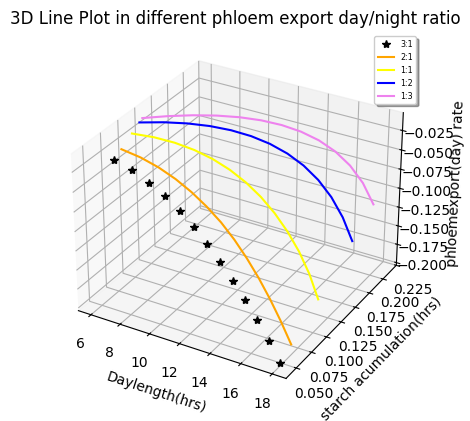

In [ ]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]
fig = plt.figure()
ax = plt.axes(projection='3d')

z1 = peL1
x1 =dL
y1 = s1

ax.plot3D(x1, y1, z1, 'k*',label="3:1")
z2 = peL2
x2 =dL
y2 = s2

ax.plot3D(x2, y2, z2, 'orange',label="2:1")
z3 = peL3
x3 =dL
y3 = s3

ax.plot3D(x3, y3, z3, 'yellow',label="1:1")
z4 = peL4
x4 =dL
y4 = s4

ax.plot3D(x4, y4, z4, 'blue',label="1:2")

z5 = peL5
x5 =dL
y5 = s5

ax.plot3D(x5, y5, z5, 'violet',label="1:3")


ax.set_title('3D Line Plot in different phloem export day/night ratio')
legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation(hrs)')
ax.set_zlabel('phloemexport(day) rate')
plt.show()

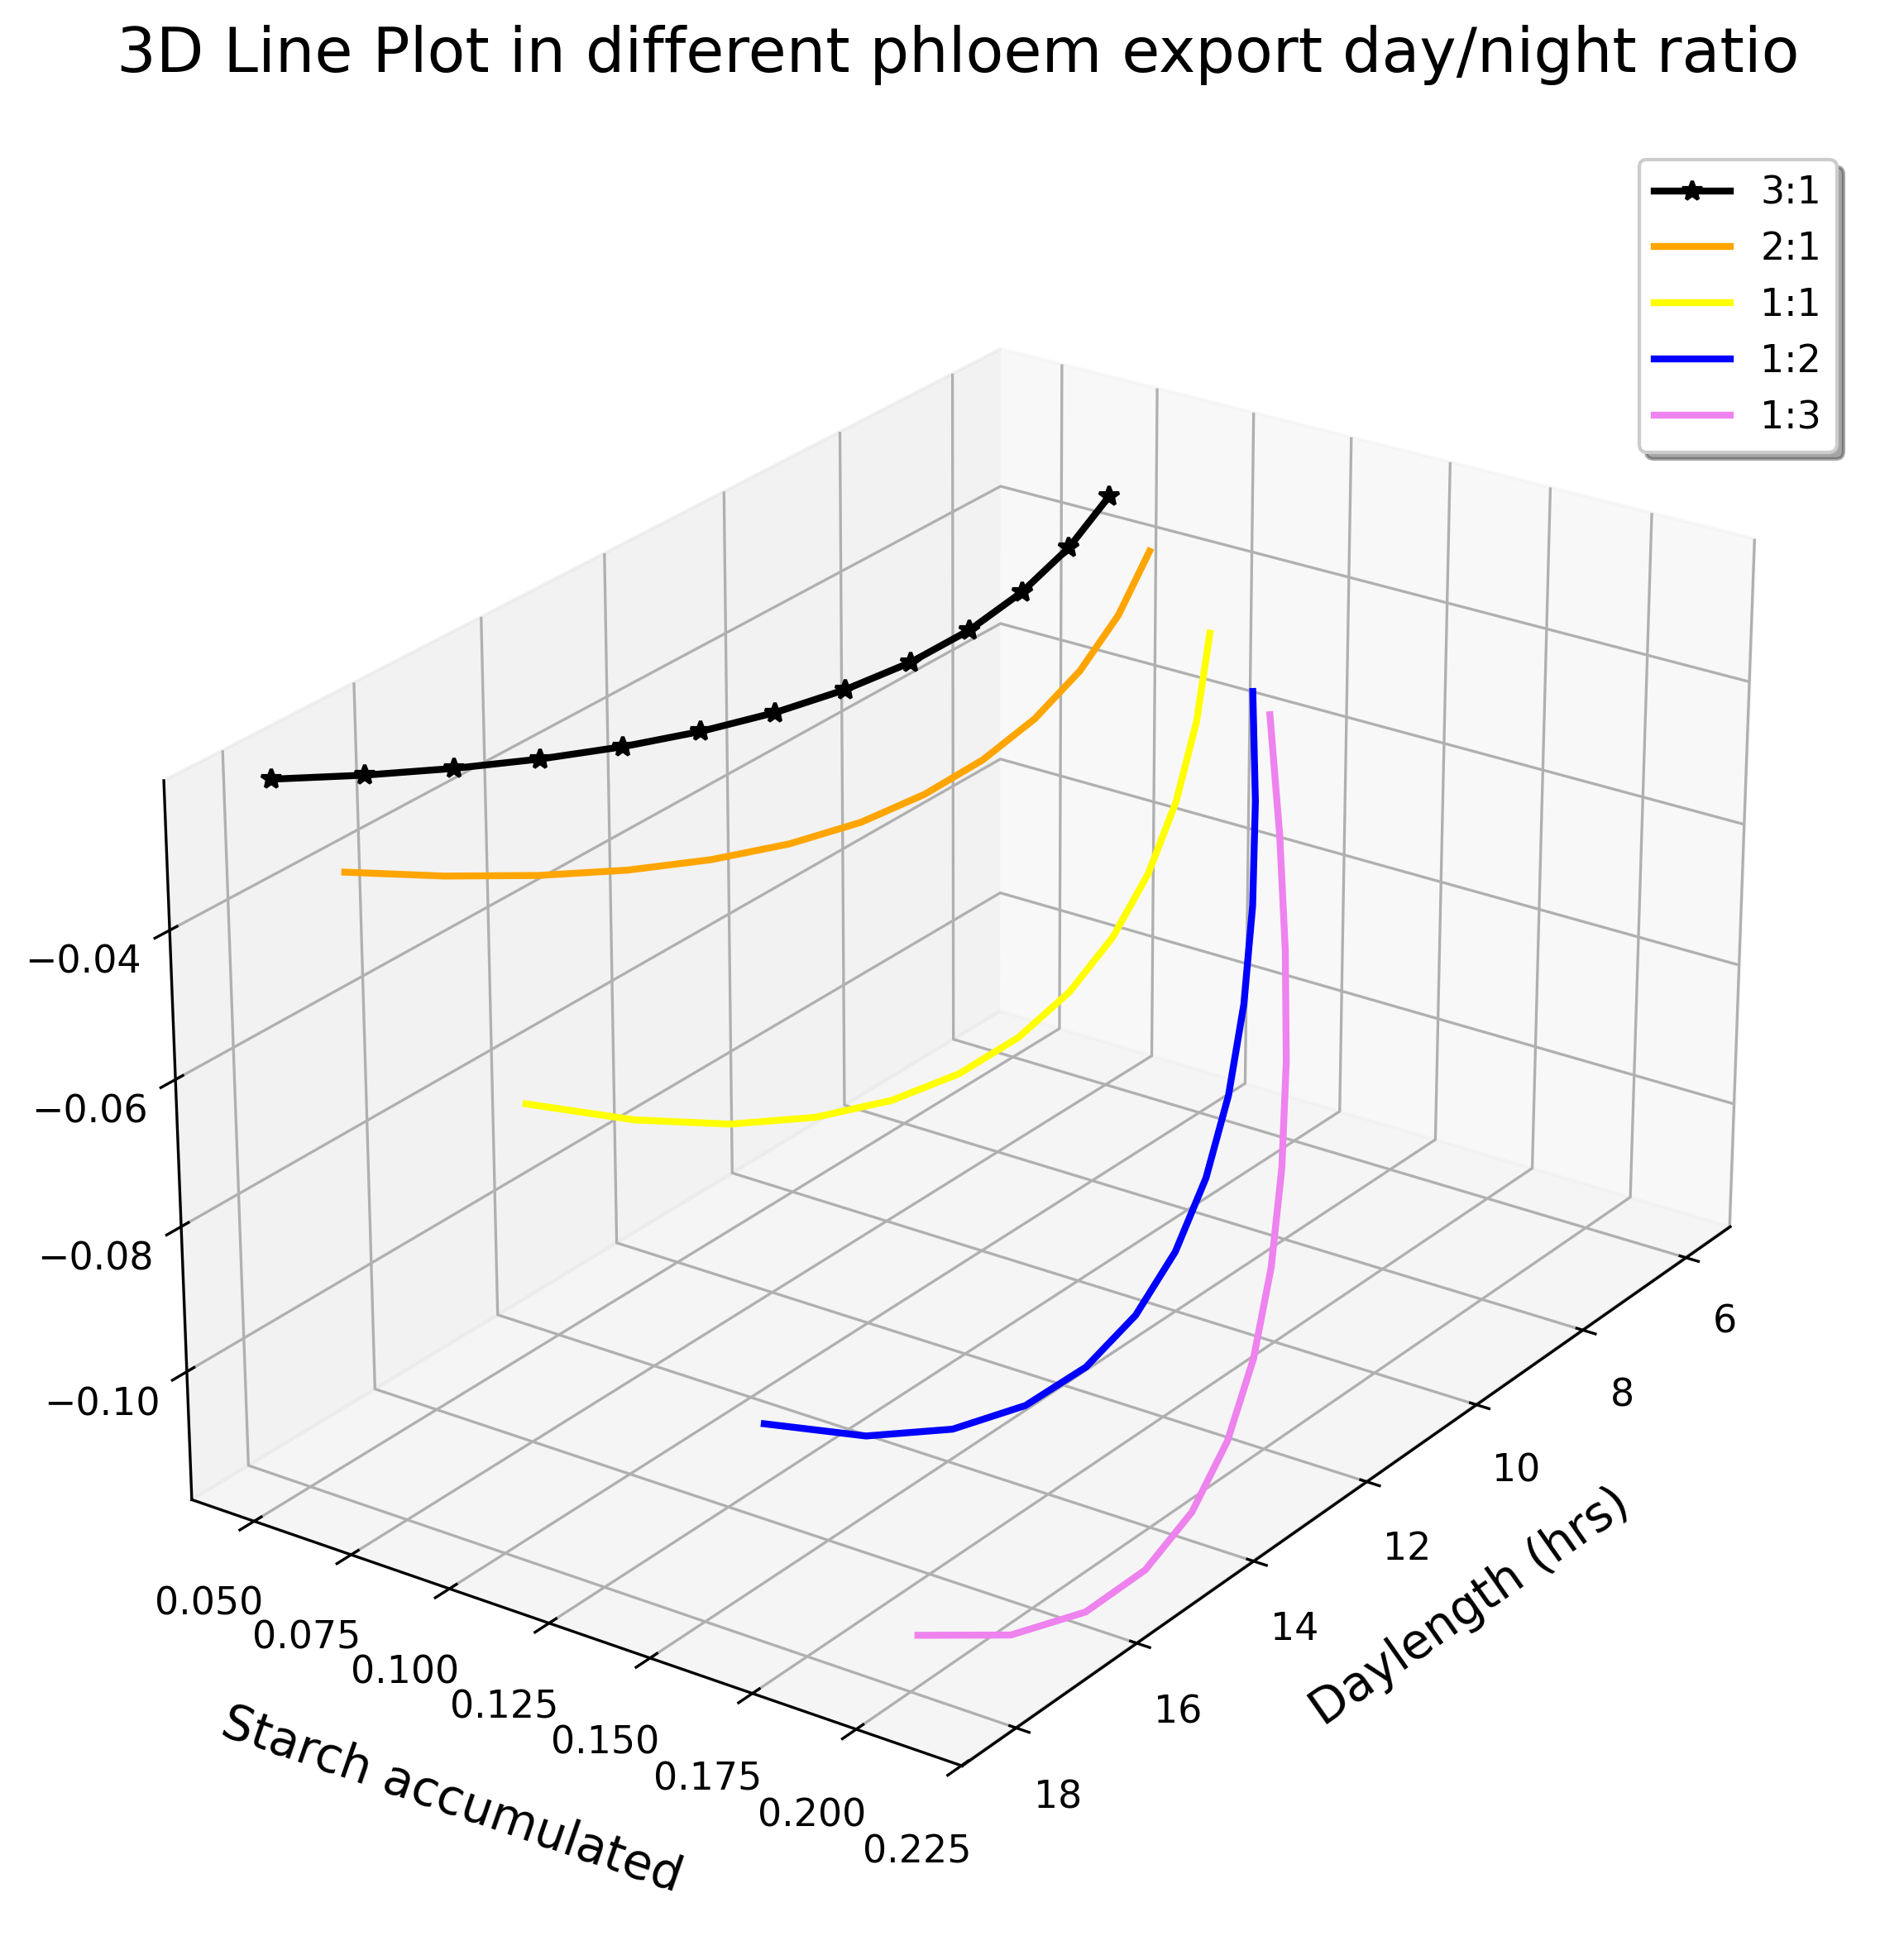

In [ ]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt

# Daylength
dL = [6,7,8,9,10,11,12,13,14,15,16,17,18]

# Create figure
fig = plt.figure(figsize=(10,8), dpi=300)
ax = plt.axes(projection='3d')

# ---------- Plot 1 ----------
z1 = peD1
x1 = dL
y1 = s1

ax.plot3D(x1, y1, z1,
          'k-*',
          linewidth=2,
          markersize=6,
          label="3:1")

# ---------- Plot 2 ----------
z2 = peD2
x2 = dL
y2 = s2

ax.plot3D(x2, y2, z2,
          color='orange',
          linewidth=2,
          label="2:1")

# ---------- Plot 3 ----------
z3 = peD3
x3 = dL
y3 = s3

ax.plot3D(x3, y3, z3,
          color='yellow',
          linewidth=2,
          label="1:1")

# ---------- Plot 4 ----------
z4 = peD4
x4 = dL
y4 = s4

ax.plot3D(x4, y4, z4,
          color='blue',
          linewidth=2,
          label="1:2")

# ---------- Plot 5 ----------
z5 = peD5
x5 = dL
y5 = s5

ax.plot3D(x5, y5, z5,
          color='violet',
          linewidth=2,
          label="1:3")

# ---------------- Labels ----------------
ax.set_title(
    '3D Line Plot in different phloem export day/night ratio',
    fontsize=18,
    pad=20
)

ax.set_xlabel(
    'Daylength (hrs)',
    fontsize=14,
    labelpad=15
)

ax.set_ylabel(
    'Starch accumulated',
    fontsize=14,
    labelpad=15
)

ax.zaxis.set_rotate_label(False)

ax.set_zlabel(
    'Phloem export (night) rate',
    fontsize=14,
    rotation=90,
    labelpad=20
)

# ---------------- Tick settings ----------------
ax.tick_params(axis='x', labelsize=11, pad=6)
ax.tick_params(axis='y', labelsize=11, pad=6)
ax.tick_params(axis='z', labelsize=11, pad=6)

# Reduce x-axis crowding
ax.set_xticks([6,8,10,12,14,16,18])

# Stretch x-axis for better clarity
ax.set_box_aspect((1.8,1.2,1))

# Better viewing angle
ax.view_init(elev=25, azim=35)

# Legend
legend = ax.legend(
    loc="best",
    fontsize=11,
    shadow=True
)

plt.tight_layout()

# Save high-quality image
plt.savefig("3D_plot.png",
            dpi=300,
            bbox_inches='tight')

plt.show()

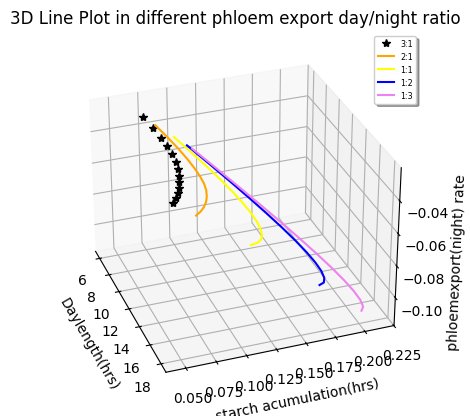

In [ ]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]
fig = plt.figure()
ax = plt.axes(projection='3d')

z1 = peD1
x1 =dL
y1 = s1

ax.plot3D(x1, y1, z1, 'k*',label="3:1")
z2 = peD2
x2 =dL
y2 = s2

ax.plot3D(x2, y2, z2, 'orange',label="2:1")
z3 = peD3
x3 =dL
y3 = s3

ax.plot3D(x3, y3, z3, 'yellow',label="1:1")
z4 = peD4
x4 =dL
y4 = s4

ax.plot3D(x4, y4, z4, 'blue',label="1:2")

z5 = peD5
x5 =dL
y5 = s5

ax.plot3D(x5, y5, z5, 'violet',label="1:3")


ax.set_title('3D Line Plot in different phloem export day/night ratio')
legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation(hrs)')
ax.set_zlabel('phloemexport(night) rate')
ax.view_init(elev=30, azim=20)
plt.show()

In [ ]:
def AtpNADPHPR(orggg_model,m):
  orgg_model=orggg_model.copy()

  NGAM_constraint=orgg_model.problem.Constraint(m*(orgg_model.reactions.NADPHoxc_tx_Light.flux_expression+orgg_model.reactions.NADPHoxm_tx_Light.flux_expression+orgg_model.reactions.NADPHoxp_tx_Light.flux_expression)-orgg_model.reactions.ATPase_tx_Light.flux_expression,
                                                  lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint)
  NGAM_constraint2=orgg_model.problem.Constraint(m*(orgg_model.reactions.NADPHoxc_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxm_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxp_tx_Dark.flux_expression)-orgg_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint2)
  from cobra.flux_analysis import pfba
  pfba(orgg_model)
  #Setting photosythetically active photon flux intensity
  perLight2=[]
  perDark2=[]
  starchacc=[]

  for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((1*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)
      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-3*(daylength),phloem_transport_Dark:-1*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
      Constraint1=org_model.problem.Constraint((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression-3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression,lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)

      nitrateflux=org_model.problem.Constraint((2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression),
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)
      atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(daylength*org_model.reactions.ATPase_tx_Dark.flux_expression),
                                            lb=0,ub=0)
      org_model.add_cons_vars(atpdaynightconstraint)
      NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression))-(daylength*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
                                                      lb=0,ub=0)
      org_model.add_cons_vars(NADPHdaynightconstraint)
      from cobra.flux_analysis import pfba
      pfba(org_model)
      DL=org_model.reactions.get_by_id("diel_biomass")
      perLightstoich=DL.metabolites[org_model.metabolites.get_by_id("phloem_transport_Light")]
      perDarkstoich=DL.metabolites[org_model.metabolites.get_by_id("phloem_transport_Dark")]
      perLight2.append(DL.flux*perLightstoich)
      perDark2.append(DL.flux*perDarkstoich)
      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day

  print(starchacc)
  print(perLight2)
  print(perDark2)

  #print(org_model.reactions.AraCore_Biomass_tx_Light.flux,"\t",org_model.reactions.AraCore_Biomass_tx_Dark.flux)

In [ ]:
for m in [0.5,0.75,1.5,3,4.5,6]:
  print("For ratio",m,":1")
  AtpNADPHPR(C3_dup_model,m)

For ratio 0.5 :1
[0.09470734506621666, 0.09933677281393946, 0.10202506193185167, 0.10304272624413881, 0.10261204651323216, 0.10091737726022297, 0.09811291740590479, 0.09432864478694857, 0.08967490087235352, 0.08424597161728227, 0.07812291150727926, 0.07057780473166385, 0.061867157987095155]
[-0.016282328397321078, -0.025732937335191705, -0.03635536597054823, -0.04798597582225946, -0.060490327490572246, -0.07375693940588109, -0.08769258241944566, -0.10221868662000132, -0.11726856522733614, -0.13278524667634745, -0.1487197648797897, -0.165028166015111, -0.18167397288420026]
[-0.016282328397321078, -0.020831425461821856, -0.024236910647032154, -0.026658875456810813, -0.028228819495600382, -0.029055764008377394, -0.029230860806481886, -0.028830911610769602, -0.027921086958889556, -0.02655704933526949, -0.02478662747996495, -0.022650924747172098, -0.020185996987133362]
For ratio 0.75 :1
[0.08682477851255915, 0.09110564129091345, 0.0936128469204467, 0.09459349027287595, 0.09425061399060983, 

In [ ]:
#For ratio 0.5 :1
A1=[0.09470734506621666, 0.09933677281393946, 0.10202506193185167, 0.10304272624413881, 0.10261204651323216, 0.10091737726022297, 0.09811291740590479, 0.09432864478694857, 0.08967490087235352, 0.08424597161728227, 0.07812291150727926, 0.07057780473166385, 0.061867157987095155]
PhmExpL1=[-0.016282328397321078, -0.025732937335191705, -0.03635536597054823, -0.04798597582225946, -0.060490327490572246, -0.07375693940588109, -0.08769258241944566, -0.10221868662000132, -0.11726856522733614, -0.13278524667634745, -0.1487197648797897, -0.165028166015111, -0.18167397288420026]
PhmExpD1=[-0.016282328397321078, -0.020831425461821856, -0.024236910647032154, -0.026658875456810813, -0.028228819495600382, -0.029055764008377394, -0.029230860806481886, -0.028830911610769602, -0.027921086958889556, -0.02655704933526949, -0.02478662747996495, -0.022650924747172098, -0.020185996987133362]
#For ratio 0.75 :1
A2=[0.08682477851255915, 0.09110564129091345, 0.0936128469204467, 0.09459349027287595, 0.09425061399060983, 0.09275262147010244, 0.09024037379909289, 0.08683260943249238, 0.08263013166306295, 0.07754272494642274, 0.07091144194262011, 0.06356931986910028, 0.05563997361004542]
PhmExpL2=[-0.022584148296999947, -0.03250223994264827, -0.043490887899178404, -0.05540062855214899, -0.06810866582587716, -0.081513171224175, -0.09552898649668462, -0.1100843420556355, -0.1251183216047671, -0.1405785407615348, -0.1564187776621458, -0.17260180127389424, -0.18909415413917482]
PhmExpD2=[-0.022584148296999947, -0.026311337096429552, -0.028993925266118936, -0.030778126973416104, -0.03178404405207601, -0.032111249270129545, -0.031842995498894876, -0.03104942981056386, -0.029790076572563596, -0.028115708152306962, -0.0260697962770243, -0.02369044331210313, -0.021010461571019424]
#For ratio 1.5 :1
A3=[0.07894221195895684, 0.08287450976788915, 0.08520063190882558, 0.08614425430201667, 0.085889181467643, 0.08458786570833865, 0.08236783019244509, 0.07890439145594987, 0.07433061789258491, 0.0689720201783456, 0.06299030584484107, 0.056452108454078526, 0.049412789232752975]
PhmExpL3=[-0.02888596819667883, -0.03927154255010429, -0.05062640982780415, -0.06281528128204311, -0.07572700416118047, -0.08926940304273515, -0.10336539057392516, -0.11794921552120863, -0.13296572518643066, -0.14836821921828422, -0.16411637617627367, -0.18017521410283335, -0.19651433539414873]
PhmExpD3=[-0.02888596819667883, -0.0317912487310368, -0.033750939885202766, -0.03489737849002395, -0.03533926860855089, -0.03516673453198658, -0.034455130191308386, -0.03326772745469987, -0.031658505996769205, -0.029673643843656845, -0.027352729362712276, -0.024729931347447713, -0.021834926154905416]
#For ratio 3 :1
A4=[0.0750009286821615, 0.07875894400637037, 0.08099452440385593, 0.08191963631616687, 0.08170846520620957, 0.0802526257320844, 0.07754705848303596, 0.0739582758349368, 0.06961076119137012, 0.06460572542659351, 0.05901316169213044, 0.05289350274605893, 0.04606755859516038]
PhmExpL4=[-0.03203687814651873, -0.042656193853832236, -0.05419417079212577, -0.06652260764698602, -0.07953617332883356, -0.09314709892571167, -0.1072820551439352, -0.12187987545928246, -0.13688835797208593, -0.1522629017322797, -0.1679651423994321, -0.1839619205172996, -0.20021652285187583]
PhmExpD4=[-0.03203687814651873, -0.03453120454834038, -0.03612944719475051, -0.03695700424832556, -0.037116880886788994, -0.03669431169800763, -0.0357606850479784, -0.034376375129541205, -0.03259246618382998, -0.030452580346455937, -0.02799419039990535, -0.025249675365119552, -0.02224628031687509]
#For ratio 4.5 :1
A5=[0.07368716758991375, 0.07738708875249238, 0.07959248856874424, 0.08051143032084127, 0.08016998152902342, 0.0784594965439203, 0.07579304884058842, 0.07227744879604389, 0.06803652714196197, 0.06315029384434893, 0.05768744697510722, 0.05124726695485656, 0.04526653314641294]
PhmExpL5=[-0.033087181463131755, -0.04378441095507486, -0.05538342444689828, -0.06775838310196668, -0.08080566784354606, -0.09443908607954477, -0.10858735433103944, -0.12319003731897836, -0.1381959004554483, -0.15356112923695603, -0.16924806447382024, -0.18522321486388835, -0.20144672147364828]
PhmExpD5=[-0.033087181463131755, -0.035444523154108225, -0.03692228296459885, -0.037643546167759265, -0.0377093116603215, -0.03720327633436612, -0.03619578477701315, -0.03474590796176313, -0.03290378582272578, -0.03071222584739121, -0.028208010745636707, -0.025422794197004283, -0.022382969052627585]
#For ratio 6 :1
A6=[0.07303028704378225, 0.07670116112560017, 0.07889147065109764, 0.07980732732329944, 0.07924515914243023, 0.07756293194992381, 0.07490619754411189, 0.07143703527618238, 0.06724941012000743, 0.062422578052582944, 0.057024589615702184, 0.050666694097157024, 0.04486602042184028]
PhmExpL6=[-0.03361233312143839, -0.044348519505696404, -0.05597805127428364, -0.06837627082945807, -0.08144016973363674, -0.09508507965646079, -0.10923998680910382, -0.12384511824881707, -0.13884967169714785, -0.15421024298929029, -0.16988952551101205, -0.1858512279565588, -0.20206182078453516]
PhmExpD6=[-0.03361233312143839, -0.03590118245699232, -0.03731870084952243, -0.03798681712747671, -0.038005412542363816, -0.03745775865254516, -0.036413328936367936, -0.03493067437787148, -0.033059445642178054, -0.030842048597858055, -0.02831492091850201, -0.025508992072468855, -0.022451313420503907]


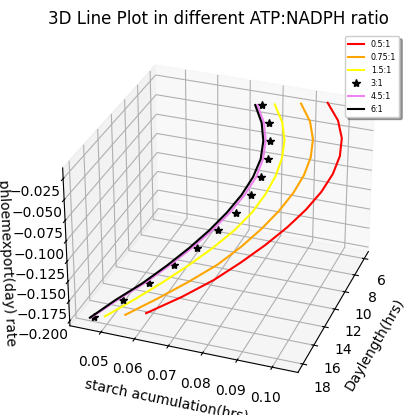

In [ ]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]
fig = plt.figure()
ax = plt.axes(projection='3d')

z1 = PhmExpL1
x1 =dL
y1 = A1

ax.plot3D(x1, y1, z1, 'red',label="0.5:1")
z2 = PhmExpL2
x2 =dL
y2 = A2

ax.plot3D(x2, y2, z2, 'orange',label="0.75:1")
z3 = PhmExpL3
x3 =dL
y3 = A3

ax.plot3D(x3, y3, z3, 'yellow',label="1.5:1")
z4 = PhmExpL4
x4 =dL
y4 = A4

ax.plot3D(x4, y4, z4, 'k*',label="3:1")

z5 = PhmExpL5
x5 =dL
y5 = A5

ax.plot3D(x5, y5, z5, 'violet',label="4.5:1")

z6 = PhmExpL6
x6 =dL
y6 = A6

ax.plot3D(x6, y6, z6, 'black',label="6:1")

ax.set_title('3D Line Plot in different ATP:NADPH ratio')
legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation(hrs)')
ax.set_zlabel('phloemexport(day) rate')
ax.view_init(elev=30, azim=20)
plt.show()

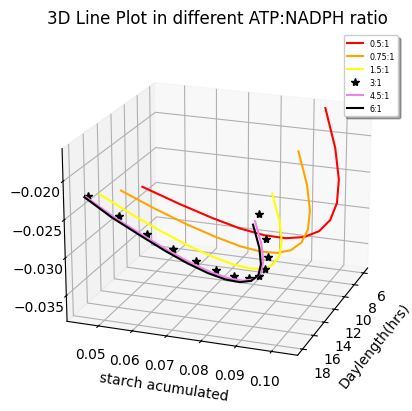

In [ ]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]
fig = plt.figure()
ax = plt.axes(projection='3d')

z1 = PhmExpD1
x1 =dL
y1 = A1

ax.plot3D(x1, y1, z1, 'red',label="0.5:1")
z2 = PhmExpD2
x2 =dL
y2 = A2

ax.plot3D(x2, y2, z2, 'orange',label="0.75:1")
z3 = PhmExpD3
x3 =dL
y3 = A3

ax.plot3D(x3, y3, z3, 'yellow',label="1.5:1")
z4 = PhmExpD4
x4 =dL
y4 = A4

ax.plot3D(x4, y4, z4, 'k*',label="3:1")

z5 = PhmExpD5
x5 =dL
y5 = A5

ax.plot3D(x5, y5, z5, 'violet',label="4.5:1")

z6 = PhmExpD6
x6 =dL
y6 = A6

ax.plot3D(x6, y6, z6, 'black',label="6:1")

ax.set_title('3D Line Plot in different ATP:NADPH ratio')
legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulated')
# Save high-quality image
plt.savefig("3D_plot.png",
            dpi=300,
            bbox_inches='tight')
ax.view_init(elev=20, azim=20)
plt.show()

In [ ]:
def AtpDNPR(orggg_model,h):
  orgg_model=orggg_model.copy()
  NGAM_constraint=orgg_model.problem.Constraint(3*(orgg_model.reactions.NADPHoxc_tx_Light.flux_expression+orgg_model.reactions.NADPHoxm_tx_Light.flux_expression+orgg_model.reactions.NADPHoxp_tx_Light.flux_expression)-orgg_model.reactions.ATPase_tx_Light.flux_expression,
                                                lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint)
      #Night
  NGAM_constraint2=orgg_model.problem.Constraint(3*(orgg_model.reactions.NADPHoxc_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxm_tx_Dark.flux_expression+orgg_model.reactions.NADPHoxp_tx_Dark.flux_expression)-orgg_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
  orgg_model.add_cons_vars(NGAM_constraint2)
  from cobra.flux_analysis import pfba
  pfba(orgg_model)
  #Setting photosythetically active photon flux intensity
  starchacc=[]
  perLight3=[]
  perDark3=[]
  for daylength in [6,9,12,15,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((1*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)

      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-3*(daylength),phloem_transport_Dark:-1*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (VATPase,VATPase)
      Constraint1=org_model.problem.Constraint((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression-3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression,lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)
      atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(h*(daylength)*(org_model.reactions.ATPase_tx_Dark.flux_expression)),
                                              lb=0,ub=0)
      org_model.add_cons_vars(atpdaynightconstraint)
      NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression))-(h*(daylength)*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
                                                        lb=0,ub=0)
      org_model.add_cons_vars(NADPHdaynightconstraint)

      nitrateflux=org_model.problem.Constraint(2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression-3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression,
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)

      from cobra.flux_analysis import pfba
      pfba(org_model)
      DL=org_model.reactions.get_by_id("diel_biomass")
      perLightstoich=DL.metabolites[org_model.metabolites.get_by_id("phloem_transport_Light")]
      perDarkstoich=DL.metabolites[org_model.metabolites.get_by_id("phloem_transport_Dark")]
      perLight3.append(DL.flux*perLightstoich)
      perDark3.append(DL.flux*perDarkstoich)
      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day


  #     # Starch degradation reactions is identified
  #     StarchDegNight1 = org_model.reactions.get_by_id("RXN_1827_p_Dark")
  #     StarchDegNight2 = org_model.reactions.get_by_id("MALTODEXGLUCOSID_RXN_p_Dark")
  #     StarchDegNight3 = org_model.reactions.get_by_id("RXN_1826_p_Dark")

  #     # Number of moles of starch (GLC units) generated by the reactions is noted
  #     StarchNight1Stoich =  StarchDegNight1.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
  #     StarchNight2Stoich =  StarchDegNight2.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]
  #     StarchNight3Stoich =  StarchDegNight3.metabolites[org_model.metabolites.get_by_id("STARCH_p_Dark")]


  #     starchdeg.append(abs((StarchDegNight1.flux*StarchNight1Stoich)+(StarchDegNight2.flux*StarchNight2Stoich)+(StarchDegNight3.flux*StarchNight3Stoich)))

  print(starchacc)
  print(perLight3)
  print(perDark3)

In [ ]:
for h in [0.25,0.3,0.5,1,2,3,4,5]:
  print("For ratio",h,":1")
  AtpDNPR(C3_dup_model,h)

For ratio 0.25 :1
[0.10022921231130338, 0.10915071550603198, 0.10274871399876882, 0.08594439889644845, 0.06224646736231095]
[-0.016241767577723904, -0.049554170965521074, -0.09140198481843934, -0.13900167732212662, -0.19063521736866773]
[-0.016241767577723904, -0.027530094980845042, -0.03046732827281311, -0.027800335464425324, -0.021181690818740856]
For ratio 0.3 :1
[0.0948824720382492, 0.10331332764890497, 0.09715272231792542, 0.08120247145847637, 0.05865115430296742]
[-0.01976171361073404, -0.053325252480125214, -0.0949308969421035, -0.14194861607994422, -0.19276439636493703]
[-0.01976171361073404, -0.02962514026673623, -0.0316436323140345, -0.02838972321598884, -0.02141826626277078]
For ratio 0.5 :1
[0.08371184745031668, 0.09128504837436685, 0.08596073895505643, 0.07171861658297031, 0.05146052818417453]
[-0.02677631226787952, -0.06086689043685172, -0.10198872118941922, -0.14784249359556456, -0.197022754357474]
[-0.02677631226787952, -0.03381493913158429, -0.033996240396473074, -0.02

In [ ]:
#For ratio 0.25 :1
SA1=[0.10022921231130338, 0.10915071550603198, 0.10274871399876882, 0.08594439889644845, 0.06224646736231095]
PhloemExpL1=[-0.016241767577723904, -0.049554170965521074, -0.09140198481843934, -0.13900167732212662, -0.19063521736866773]
PhloemExpD1=[-0.016241767577723904, -0.027530094980845042, -0.03046732827281311, -0.027800335464425324, -0.021181690818740856]
#For ratio 0.3 :1
SA2=[0.0948824720382492, 0.10331332764890497, 0.09715272231792542, 0.08120247145847637, 0.05865115430296742]
PhloemExpL2=[-0.01976171361073404, -0.053325252480125214, -0.0949308969421035, -0.14194861607994422, -0.19276439636493703]
PhloemExpD2=[-0.01976171361073404, -0.02962514026673623, -0.0316436323140345, -0.02838972321598884, -0.02141826626277078]
#For ratio 0.5 :1
SA3=[0.08371184745031668, 0.09128504837436685, 0.08596073895505643, 0.07171861658297031, 0.05146052818417453]
PhloemExpL3=[-0.02677631226787952, -0.06086689043685172, -0.10198872118941922, -0.14784249359556456, -0.197022754357474]
PhloemExpD3=[-0.02677631226787952, -0.03381493913158429, -0.033996240396473074, -0.029568498719112914, -0.02189141715083044]
#For ratio 1 :1
SA4=[0.0750009286821615, 0.08191963631616997, 0.07754705848289856, 0.06460572542659351, 0.04606755859516038]
PhloemExpL4=[-0.03203687814651873, -0.06652260764698602, -0.10728205514393437, -0.1522629017322797, -0.20021652285187583]
PhloemExpD4=[-0.03203687814651873, -0.03695700424832556, -0.03576068504797812, -0.030452580346455937, -0.02224628031687509]
#For ratio 2 :1
SA5=[0.07064546929810088, 0.07723693028687242, 0.0733244855288693, 0.06104927984942984, 0.04337107380063898]
PhloemExpL5=[-0.03466716108583802, -0.06935046625205227, -0.10992869477403604, -0.15447310580064422, -0.20181340709907702]
PhloemExpD5=[-0.03466716108583802, -0.038528036806695705, -0.03664289825801201, -0.03089462116012884, -0.022423711899897447]
#For ratio 3 :1
SA6=[0.06919364950343043, 0.07567602827718335, 0.07191696121068365, 0.059863797989710074, 0.04247224553559585]
PhloemExpL6=[-0.035543922065611536, -0.0702930857870743, -0.11081090798406419, -0.1552098404900945, -0.20234570184814252]
PhloemExpD6=[-0.035543922065611536, -0.03905171432615239, -0.036936969328021395, -0.0310419680980189, -0.022482855760904724]
#For ratio 4 :1
SA7=[0.06846773960608549, 0.07489557727251973, 0.07121319905170276, 0.059271057060575026, 0.04202283140293468]
PhloemExpL7=[-0.03598230255549755, -0.07076439555458607, -0.11125201458908224, -0.15557820783482731, -0.20261184922267236]
PhloemExpD7=[-0.03598230255549755, -0.03931355308588115, -0.03708400486302742, -0.031115641566965464, -0.02251242769140804]
#For ratio 5 :1
SA8=[0.06803219366817989, 0.07442730666947515, 0.07079094175651937, 0.05891541250266346, 0.041366149318633486]
PhloemExpL8=[-0.03624533084943012, -0.07104718141509178, -0.11151667855209269, -0.1557992282416595, -0.20276509674750817]
PhloemExpD8=[-0.03624533084943012, -0.03947065634171766, -0.03717222618403089, -0.031159845648331904, -0.022529455194167575]


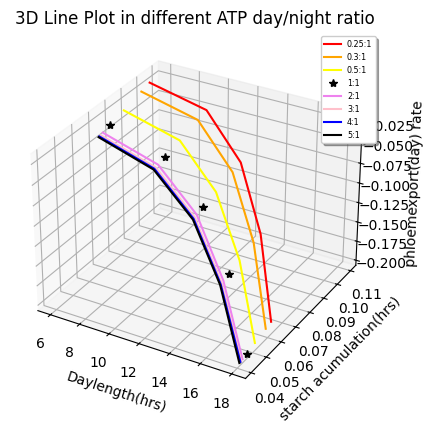

In [ ]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt
dL=[6,9,12,15,18]
fig = plt.figure()
ax = plt.axes(projection='3d')

z1 = PhloemExpL1
x1 =dL
y1 = SA1

ax.plot3D(x1, y1, z1, 'red',label="0.25:1")
z2 = PhloemExpL2
x2 =dL
y2 = SA2

ax.plot3D(x2, y2, z2, 'orange',label="0.3:1")
z3 = PhloemExpL3
x3 =dL
y3 = SA3

ax.plot3D(x3, y3, z3, 'yellow',label="0.5:1")
z4 = PhloemExpL4
x4 =dL
y4 = SA4

ax.plot3D(x4, y4, z4, 'k*',label="1:1")

z5 = PhloemExpL5
x5 =dL
y5 = SA5

ax.plot3D(x5, y5, z5, 'violet',label="2:1")

z6 = PhloemExpL6
x6 =dL
y6 = SA6

ax.plot3D(x6, y6, z6, 'pink',label="3:1")

z7 = PhloemExpL7
x7 =dL
y7 = SA7

ax.plot3D(x7, y7, z7, 'blue',label="4:1")
z8 = PhloemExpL8
x8 =dL
y8 = SA8

ax.plot3D(x8, y8, z8, 'black',label="5:1")

ax.set_title('3D Line Plot in different ATP day/night ratio')
legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation(hrs)')
ax.set_zlabel('phloemexport(day) rate')
plt.show()

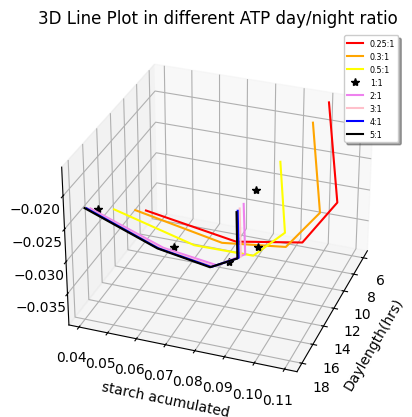

In [ ]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt
dL=[6,9,12,15,18]
fig = plt.figure()
ax = plt.axes(projection='3d')

z1 = PhloemExpD1
x1 =dL
y1 = SA1

ax.plot3D(x1, y1, z1, 'red',label="0.25:1")
z2 = PhloemExpD2
x2 =dL
y2 = SA2

ax.plot3D(x2, y2, z2, 'orange',label="0.3:1")
z3 = PhloemExpD3
x3 =dL
y3 = SA3

ax.plot3D(x3, y3, z3, 'yellow',label="0.5:1")
z4 = PhloemExpD4
x4 =dL
y4 = SA4

ax.plot3D(x4, y4, z4, 'k*',label="1:1")

z5 = PhloemExpD5
x5 =dL
y5 = SA5

ax.plot3D(x5, y5, z5, 'violet',label="2:1")

z6 = PhloemExpD6
x6 =dL
y6 = SA6

ax.plot3D(x6, y6, z6, 'pink',label="3:1")

z7 = PhloemExpD7
x7 =dL
y7 = SA7

ax.plot3D(x7, y7, z7, 'blue',label="4:1")
z8 = PhloemExpD8
x8 =dL
y8 = SA8

ax.plot3D(x8, y8, z8, 'black',label="5:1")

ax.set_title('3D Line Plot in different ATP day/night ratio')
legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulated')
#phloem export night rate
ax.view_init(elev=30, azim=20)
plt.savefig("3D_plot.png",
            dpi=300,
            bbox_inches='tight')
plt.show()

In [ ]:
def MNCPR(orggg_model,n):
  orgg_model=orggg_model.copy()

  #Setting photosythetically active photon flux intensity
  starchacc=[]
  perLight4=[]
  perDark4=[]
  for daylength in [6,7,8,9,10,11,12,13,14,15,16,17,18]:
      org_model=orgg_model.copy()
      Phloem_biomass=org_model.problem.Constraint((1*(24-daylength)*org_model.reactions.Phloem_output_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Phloem_output_tx_Dark.flux_expression),
        lb=0,ub=0)
      org_model.add_cons_vars(Phloem_biomass)

      #Making the objective reaction
      from cobra import Reaction,Metabolite
      #Making new metabolites and adding it to existing phloem transport reaction
      phloem_transport_Light=Metabolite('phloem_transport_Light',name='phloem transport during Light',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Light").add_metabolites({phloem_transport_Light:1})
      phloem_transport_Dark=Metabolite('phloem_transport_Dark',name='phloem transport during Dark',formula='',compartment='b1')
      org_model.reactions.get_by_id("Phloem_output_tx_Dark").add_metabolites({phloem_transport_Dark:1})
      #Making new reaction
      rxn = Reaction('diel_biomass')
      rxn.add_metabolites({phloem_transport_Light:-3*(daylength),phloem_transport_Dark:-1*(24-daylength)})
      rxn.lower_bound=0
      rxn.upper_bound=1000
      org_model.add_reactions([rxn])

      org_model.objective='diel_biomass'
      org_model.optimize()
      PPFD = ((500*daylength*3600)/1000000 )#mol/m2/day
      #print(PPFD)
      org_model.reactions.get_by_id("Photon_tx_Light").upper_bound = PPFD
      org_model.reactions.get_by_id("Photon_tx_Light").lower_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").upper_bound = 0
      org_model.reactions.get_by_id("Photon_tx_Dark").lower_bound = 0

      VATPase = ((0.0049*PPFD)+((2.7851*daylength*3600)/1000000)) #From cheung paper
      org_model.reactions.get_by_id("ATPase_tx_Light").bounds = (n*VATPase,n*VATPase)

      Constraint1=org_model.problem.Constraint(((24-daylength)*org_model.reactions.AraCore_Biomass_tx_Light.flux_expression)-(3*daylength*org_model.reactions.AraCore_Biomass_tx_Dark.flux_expression),lb=0,ub=0)
      org_model.add_cons_vars(Constraint1)
      nitrateflux=org_model.problem.Constraint((2*(24-daylength)*org_model.reactions.Nitrate_tx_Light.flux_expression)-(3*daylength*org_model.reactions.Nitrate_tx_Dark.flux_expression),
                                         lb=0,ub=0)

      org_model.add_cons_vars(nitrateflux)
      NGAM_constraint=org_model.problem.Constraint(3*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression)-org_model.reactions.ATPase_tx_Light.flux_expression,
                                                lb=0,ub=0)
      org_model.add_cons_vars(NGAM_constraint)
      #Night
      NGAM_constraint2=org_model.problem.Constraint(3*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression)-org_model.reactions.ATPase_tx_Dark.flux_expression,
                                                      lb=0,ub=0)
      org_model.add_cons_vars(NGAM_constraint2)
      atpdaynightconstraint=org_model.problem.Constraint(((24-daylength)*org_model.reactions.ATPase_tx_Light.flux_expression)-(daylength*org_model.reactions.ATPase_tx_Dark.flux_expression),
                                            lb=0,ub=0)
      org_model.add_cons_vars(atpdaynightconstraint)
      NADPHdaynightconstraint=org_model.problem.Constraint(((24-daylength)*(org_model.reactions.NADPHoxc_tx_Light.flux_expression+org_model.reactions.NADPHoxp_tx_Light.flux_expression+org_model.reactions.NADPHoxm_tx_Light.flux_expression))-(daylength*(org_model.reactions.NADPHoxc_tx_Dark.flux_expression+org_model.reactions.NADPHoxp_tx_Dark.flux_expression+org_model.reactions.NADPHoxm_tx_Dark.flux_expression)),
                                                        lb=0,ub=0)
      org_model.add_cons_vars(NADPHdaynightconstraint)

      from cobra.flux_analysis import pfba
      pfba(org_model)
      DL=org_model.reactions.get_by_id("diel_biomass")
      perLightstoich=DL.metabolites[org_model.metabolites.get_by_id("phloem_transport_Light")]
      perDarkstoich=DL.metabolites[org_model.metabolites.get_by_id("phloem_transport_Dark")]
      perLight4.append(DL.flux*perLightstoich)
      perDark4.append(DL.flux*perDarkstoich)
      StarchSynDay = org_model.reactions.get_by_id("GLYCOGENSYN_RXN_p_Light")

      StarchDayStoich = StarchSynDay.metabolites[org_model.metabolites.get_by_id("STARCH_p_Light")]
      starchacc.append(StarchSynDay.flux*StarchDayStoich)#mol GLC/m2/day
  print(starchacc)
  print(perLight4)
  print(perDark4)

In [ ]:
for n in [0,0.5,1,1.5,2]:
  print("For ",n,"*VATPase")
  MNCPR(C3_dup_model,n)

For  0 *VATPase
[0.06763356698802786, 0.0710678607319944, 0.07313583892335856, 0.07402746551793583, 0.07389887649053306, 0.07287960221026064, 0.07063056249134005, 0.06735944393627599, 0.06333713430757774, 0.05872079545026773, 0.051654257890194885, 0.046266468716014766, 0.040619016256505464]
[-0.03802756334543819, -0.04909935553867784, -0.06099541302912628, -0.07360085199815275, -0.08682126529654213, -0.10057834910707904, -0.11480568530121057, -0.1294481979656971, -0.14445937526821043, -0.15979935643069776, -0.17542646353241836, -0.19127982185557088, -0.20736448579487277]
[-0.03802756334543819, -0.039747097340834446, -0.040663608686084186, -0.04088936222119597, -0.04051659047171966, -0.0396217738906675, -0.03826856176707019, -0.03651103019545303, -0.03439508934957391, -0.03195987128613955, -0.029237743922069726, -0.02625409319586267, -0.02304049842165253]
For  0.5 *VATPase
[0.07130618084225161, 0.07490104678131415, 0.07705201764608414, 0.07796007716230825, 0.07779038878205402, 0.0766197

In [ ]:
#For  0 *VATPase
StA1=[0.06763356698802786, 0.0710678607319944, 0.07313583892335856, 0.07402746551793583, 0.07389887649053306, 0.07287960221026064, 0.07063056249134005, 0.06735944393627599, 0.06333713430757774, 0.05872079545026773, 0.051654257890194885, 0.046266468716014766, 0.040619016256505464]
PhloemExportL1=[-0.03802756334543819, -0.04909935553867784, -0.06099541302912628, -0.07360085199815275, -0.08682126529654213, -0.10057834910707904, -0.11480568530121057, -0.1294481979656971, -0.14445937526821043, -0.15979935643069776, -0.17542646353241836, -0.19127982185557088, -0.20736448579487277]
PhloemExportD1=[-0.03802756334543819, -0.039747097340834446, -0.040663608686084186, -0.04088936222119597, -0.04051659047171966, -0.0396217738906675, -0.03826856176707019, -0.03651103019545303, -0.03439508934957391, -0.03195987128613955, -0.029237743922069726, -0.02625409319586267, -0.02304049842165253]
#For  0.5 *VATPase
StA2=[0.07130618084225161, 0.07490104678131415, 0.07705201764608414, 0.07796007716230825, 0.07779038878205402, 0.07661971470966134, 0.07401322326413788, 0.07058820805579238, 0.06641682096682569, 0.061622310074713256, 0.056271020086596416, 0.050420232893890214, 0.043776476824799626]
PhloemExportL2=[-0.03503890415639685, -0.04588523636814129, -0.057602741737083, -0.07006986654371908, -0.08318674006098624, -0.09687044033331367, -0.11105073145976622, -0.12567004657706757, -0.14067880590492646, -0.1560347660226364, -0.17170154898507595, -0.18764771165669691, -0.20384079445133624]
PhloemExportD2=[-0.03503890415639685, -0.03714519134563819, -0.038401827824722, -0.038927703635399484, -0.03882047869512691, -0.03816108255554781, -0.03701691048658874, -0.035445397752506234, -0.03349495378688725, -0.031206953204527283, -0.02861692483084599, -0.025755568266605456, -0.022648977161259583]
#For  1 *VATPase
StA3=[0.07500092868219962, 0.07875894400638697, 0.08099452440374717, 0.08191963631607203, 0.08170846520693502, 0.08025262573189362, 0.0775470584830039, 0.07395827583519483, 0.06961076118991585, 0.06460572542838897, 0.05901316169184682, 0.05289350274606308, 0.046067558594739516]
PhloemExportL3=[-0.03203687814651879, -0.042656193853832285, -0.05419417079212445, -0.06652260764698605, -0.07953617332883933, -0.09314709892571371, -0.10728205514393588, -0.12187987545928285, -0.13688835797207657, -0.15226290173228946, -0.16796514239943022, -0.18396192051729918, -0.20021652285187322]
PhloemExportD3=[-0.03203687814651879, -0.03453120454834042, -0.036129447194749635, -0.036957004248325584, -0.03711688088679169, -0.03669431169800843, -0.03576068504797862, -0.034376375129541316, -0.03259246618382775, -0.030452580346457894, -0.027994190399905035, -0.025249675365119496, -0.0222462803168748]
#For  1.5 *VATPase
StA4=[0.07869567652212206, 0.08261684123153042, 0.08493703116174971, 0.08587919546983871, 0.08562654163087317, 0.08388553675409004, 0.08107430128381868, 0.07732834361523219, 0.0728047014139286, 0.06758914078094874, 0.06175530329853065, 0.055366772598465216, 0.04835864036539517]
PhloemExportL4=[-0.02903485213664056, -0.03942715133952326, -0.0507855998471683, -0.06297534875025167, -0.07588560659668338, -0.08942375751811377, -0.10351336736892894, -0.11808970434150336, -0.13309791003923235, -0.14849103744194073, -0.16422873581378575, -0.18027612937790466, -0.19659225125241775]
PhloemExportD4=[-0.02903485213664056, -0.031917217751042636, -0.03385706656477887, -0.03498630486125093, -0.03541328307845224, -0.03522754084046906, -0.03450445578964298, -0.03330735250657787, -0.03168997858076961, -0.029698207488388143, -0.02737145596896429, -0.02474378246363397, -0.021843583472490862]
#For  2 *VATPase
StA5=[0.08239042436212733, 0.0864747384565365, 0.08887953791939353, 0.0898387546235516, 0.08938569504742519, 0.08751844777640402, 0.08458185113429403, 0.08069841139495103, 0.07599864163816027, 0.07057255613290211, 0.06449744490472609, 0.057447277101759675, 0.05064972213547316]
PhloemExportL5=[-0.026032826126762876, -0.0361981088252143, -0.047377028902209545, -0.059428089853517316, -0.07223478922584942, -0.0857004161105146, -0.0997446453629462, -0.11429953322372191, -0.12930746210639002, -0.14471917315158866, -0.16049232922814305, -0.17658953472976852, -0.19296797965295479]
PhloemExportD5=[-0.026032826126762876, -0.02930323095374491, -0.031584685934806365, -0.033015605474176285, -0.03370956830539639, -0.03376076998293, -0.03324821512098206, -0.03223832988361387, -0.03078749097771191, -0.028943834630317734, -0.026748721538023844, -0.024237779276634897, -0.021440886628106087]


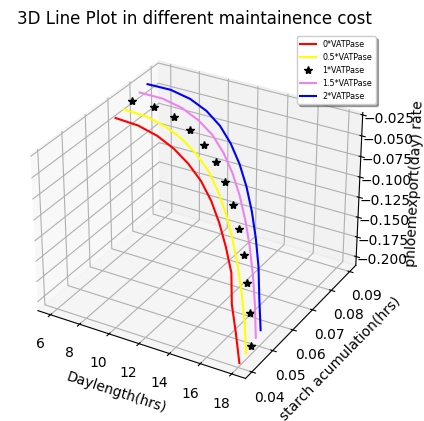

In [ ]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt
dLnew=[6,7,8,9,10,11,12,13,14,15,16,17,18]
fig = plt.figure()
ax = plt.axes(projection='3d')

z1 = PhloemExportL1
x1 =dLnew
y1 = StA1

ax.plot3D(x1, y1, z1, 'red',label="0*VATPase")
z2 = PhloemExportL2
x2 =dLnew
y2 = StA2

ax.plot3D(x2, y2, z2, 'yellow',label="0.5*VATPase")
z3 = PhloemExportL3
x3 =dLnew
y3 = StA3

ax.plot3D(x3, y3, z3, 'k*',label="1*VATPase")
z4 = PhloemExportL4
x4 =dLnew
y4 = StA4

ax.plot3D(x4, y4, z4, 'violet',label="1.5*VATPase")

z5 = PhloemExportL5
x5 =dLnew
y5 = StA5

ax.plot3D(x5, y5, z5, 'blue',label="2*VATPase")



ax.set_title('3D Line Plot in different maintainence cost')
legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulation(hrs)')
ax.set_zlabel('phloemexport(day) rate')
plt.show()

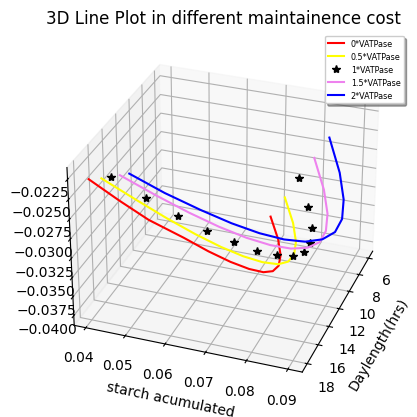

In [ ]:
from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt
dL=[6,7,8,9,10,11,12,13,14,15,16,17,18]
fig = plt.figure()
ax = plt.axes(projection='3d')

z1 = PhloemExportD1
x1 =dL
y1 = StA1

ax.plot3D(x1, y1, z1, 'red',label="0*VATPase")
z2 = PhloemExportD2
x2 =dL
y2 = StA2

ax.plot3D(x2, y2, z2, 'yellow',label="0.5*VATPase")
z3 = PhloemExportD3
x3 =dL
y3 = StA3

ax.plot3D(x3, y3, z3, 'k*',label="1*VATPase")
z4 = PhloemExportD4
x4 =dL
y4 = StA4

ax.plot3D(x4, y4, z4, 'violet',label="1.5*VATPase")

z5 = PhloemExportD5
x5 =dL
y5 = StA5

ax.plot3D(x5, y5, z5, 'blue',label="2*VATPase")



ax.set_title('3D Line Plot in different maintainence cost')
legend=ax.legend(loc="best",shadow=True,fontsize='xx-small')
plt.xlabel('Daylength(hrs)')
plt.ylabel('starch acumulated')
#ax.set_zlabel('phloemexport(night) rate')
ax.view_init(elev=30, azim=20)
plt.savefig("3D_plot.png",
            dpi=300,
            bbox_inches='tight')
plt.show()